In [16]:
### load modules 
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import re 
import pickle
import pingouin as pg
from itertools import groupby
from operator import itemgetter
from patsy import dmatrices
import statsmodels.formula.api as smf
import statsmodels.discrete.discrete_model as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

### load my scripts 
import data_combiner as dc
import plotting_funcs as pf
import sim as sim


plt.rcParams["figure.figsize"] = (20,10)
sns.set_context('talk',font_scale=2)
plt.rcParams["lines.linewidth"] = 3

plt.rcParams['font.size'] = 15
plt.rcParams['font.family'] = 'Verdana'

In [17]:
curr_round = 'round_1'
# all_filenames = glob.glob("/Users/rohinpalsule/Documents/GitHub/foraging_fMRI_pilot/experiment/experiment1k/run_exp/data/batch*/*.csv")
all_filenames = glob.glob("/Users/zyfxl/OneDrive - University of Southern California/Documents/GitHub/foraging_kids_4blocks_Yifan/data_analysis/data/foraging_pilot_data/*.csv")

### verify essential functions working

In [20]:
import importlib
import sim
import data_combiner as dc

importlib.invalidate_caches()
importlib.reload(sim)
importlib.reload(dc)

# Verify both functions work
print("data_combiner:", len(dc.load_data()))
print("sim:", len(sim.load_data()))

data_combiner: 3
sim: 3


In [39]:
all_data = dc.clean_data_group(all_filenames).reset_index(drop=True)
num_subs = all_data["sub_num"].nunique()

all_data["prt_rel_mvt"] = all_data["prt"] - all_data["opt_prt"]
all_data["prt_rel_om"] = all_data["prt"] - all_data["opt_prt_om"]


0


c:\Users\zyfxl\OneDrive - University of Southern California\Documents\GitHub\foraging_kids_4blocks_Yifan\data_analysis\data_analysis\data_combiner.py:350: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  clean_data['condition'] = clean_data['condition'].fillna(1)


1
2
3
4
5
6
7
8
9


c:\Users\zyfxl\OneDrive - University of Southern California\Documents\GitHub\foraging_kids_4blocks_Yifan\data_analysis\data_analysis\data_combiner.py:354: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  'gal_2_trans_2','gal_0_encount','gal_1_encount','gal_2_encount','opt_prt','opt_prt_om']]


In [40]:
all_sub_num = []
all_block = []
all_true_planet = []
all_planet = []
all_galaxy = []
all_stay_num = []
all_reward = []
all_planet_in_block = []

for sub_num in range(198):
    sub_data = all_data.query("sub_num=="+str(sub_num))
    for b in range(1,6):
        block_data = sub_data.query("block=="+str(b))
        block_planets = block_data.planet
        planet_in_block = 0
        for planet in block_planets:
            planet_data = block_data.query("planet=="+str(planet))
            planet_reward = planet_data.reset_index().reward_list[0]
            true_planet = planet_data.reset_index().true_planet[0]
            galaxy = planet_data.reset_index().galaxy[0]
            stay_num = 0
            for reward in planet_reward:
                all_sub_num += [sub_num]
                all_block += [b]
                all_true_planet += [true_planet]
                all_planet += [planet]
                all_galaxy += [galaxy]
                all_stay_num += [stay_num]
                all_reward += [reward]
                all_planet_in_block += [planet_in_block]
                stay_num += 1
            planet_in_block += 1

temp = pd.DataFrame({'sub_num':all_sub_num,'block':all_block,'true_planet':all_true_planet,
                     'planet':all_planet,'galaxy':all_galaxy,'stay_num':all_stay_num,'reward':all_reward,
                    'planet_in_block':all_planet_in_block})
temp.to_csv("new_pilot_data_child.csv")

In [41]:
len(temp['sub_num'].unique())

10

In [42]:
all_data

,sub_num,condition,age,gender,n_prac,block,planet,true_planet,prt,initial_reward,...,gal_2_trans_0,gal_2_trans_1,gal_2_trans_2,gal_0_encount,gal_1_encount,gal_2_encount,opt_prt,opt_prt_om,prt_rel_mvt,prt_rel_om
0,0,1,100,m,0,1,0,0,3,103,...,NaN,NaN,NaN,1,0,0,2,2,1,1
1,0,1,100,m,0,1,1,1,4,98,...,NaN,NaN,NaN,2,0,0,2,2,2,2
2,0,1,100,m,0,1,2,2,5,103,...,NaN,NaN,NaN,2,1,0,2,3,3,2
3,0,1,100,m,0,1,3,3,5,107,...,NaN,NaN,NaN,2,2,0,2,3,3,2
4,0,1,100,m,0,1,4,4,5,100,...,NaN,NaN,NaN,2,3,0,2,3,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
350,9,1,100,m,0,3,16,43,2,98,...,0.166667,0.333333,0.5,5,6,6,4,4,-2,-2
351,9,1,100,m,0,4,17,60,21,98,...,0.166667,0.333333,0.5,6,6,6,6,2,15,19
352,9,1,100,m,0,4,18,61,10,100,...,0.166667,0.333333,0.5,7,6,6,3,2,7,8
353,9,1,100,m,0,4,19,62,24,94,...,0.166667,0.333333,0.5,8,6,6,8,2,16,22


In [43]:
# avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean().reset_index()
# #avgd_data.to_csv("ref_point_galaxy_dataset_2022_newOpt.csv")

all_data = all_data.astype({'galaxy':'int32'})
avgd_data = all_data.groupby(by=['sub_num','true_planet'])[['galaxy','prt','prt_rel_om']].mean().reset_index()
avgd_data.loc[:,['sub_num','true_planet','galaxy','prt','prt_rel_om']].to_csv("new_pilot_avg_child.csv")

In [44]:
avgd_data

,sub_num,true_planet,galaxy,prt,prt_rel_om
0,0,0,0.0,3.0,1.0
1,0,1,0.0,4.0,2.0
2,0,2,1.0,5.0,2.0
3,0,3,1.0,5.0,2.0
4,0,4,1.0,5.0,2.0
...,...,...,...,...,...
350,9,43,1.0,2.0,-2.0
351,9,60,0.0,21.0,19.0
352,9,61,0.0,10.0,8.0
353,9,62,0.0,24.0,22.0


In [45]:
avgd_data = all_data.groupby(by=['sub_num']).mean(numeric_only=True).reset_index()
mean = np.mean(avgd_data.prt)
sd = stats.tstd(avgd_data.prt)

print("low bound: " + str(mean - 2.0*sd))
print("upp bound: " + str(mean + 2.0*sd))

low bound: -0.7161619531420582
upp bound: 12.638660314528217


### Dropping criterion (this is for adults, prob no need to run this for children)

In [ ]:
# subs_to_drop = list(set(all_data.query("catch_perf != 2 ").sub_num))

# x=avgd_data.prt < 1.5 # 24,39
# ind=np.where(x==True)[0]
# subs_to_drop += avgd_data.iloc[ind,:].sub_num.to_list()

# x=avgd_data.prt > mean + 2.0*sd
# ind=np.where(x==True)[0]
# subs_to_drop += avgd_data.iloc[ind,:].sub_num.to_list()

# x= avgd_data.n_prac > 2
# ind=np.where(x==True)[0]
# subs_to_drop +=avgd_data.iloc[ind,:].sub_num.to_list()

# all_data = all_data[~all_data['sub_num'].isin(subs_to_drop)]

In [32]:
len(np.unique(all_data.sub_num))

0

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\673727760.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x='galaxy',y='prt',palette='Set1',size=10,alpha=0.5,edgecolor='k',data=avgd_data)
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\673727760.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(["poor","neutral","rich"])


[Text(0, 0, 'poor'), Text(1, 0, 'neutral'), Text(2, 0, 'rich')]

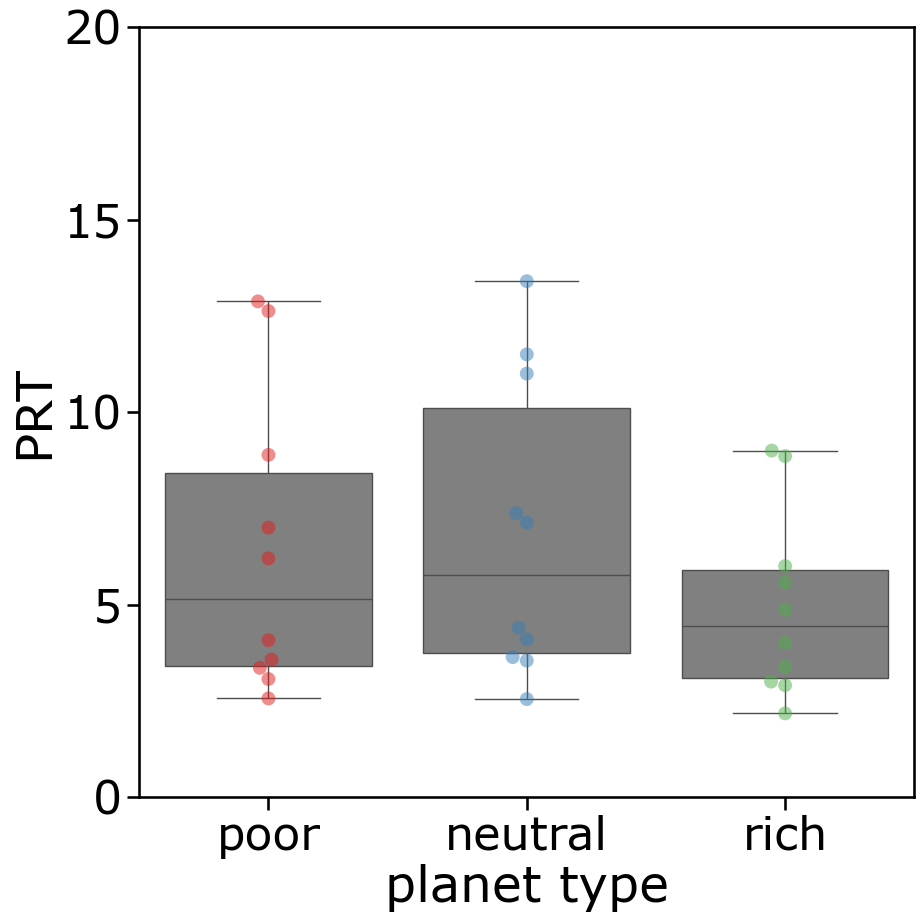

In [46]:
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=2)
avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean(numeric_only=True).reset_index()
sns.swarmplot(x='galaxy',y='prt',palette='Set1',size=10,alpha=0.5,edgecolor='k',data=avgd_data)

g=sns.boxplot(x='galaxy',y='prt',color='grey',data=avgd_data)
g.set_yticks(np.arange(0,25,5))
g.set_ylabel("PRT")
g.set_xlabel("planet type")
g.set_xticklabels(["poor","neutral","rich"])


#plt.savefig('plots/planet_type_prt.png') #optional save

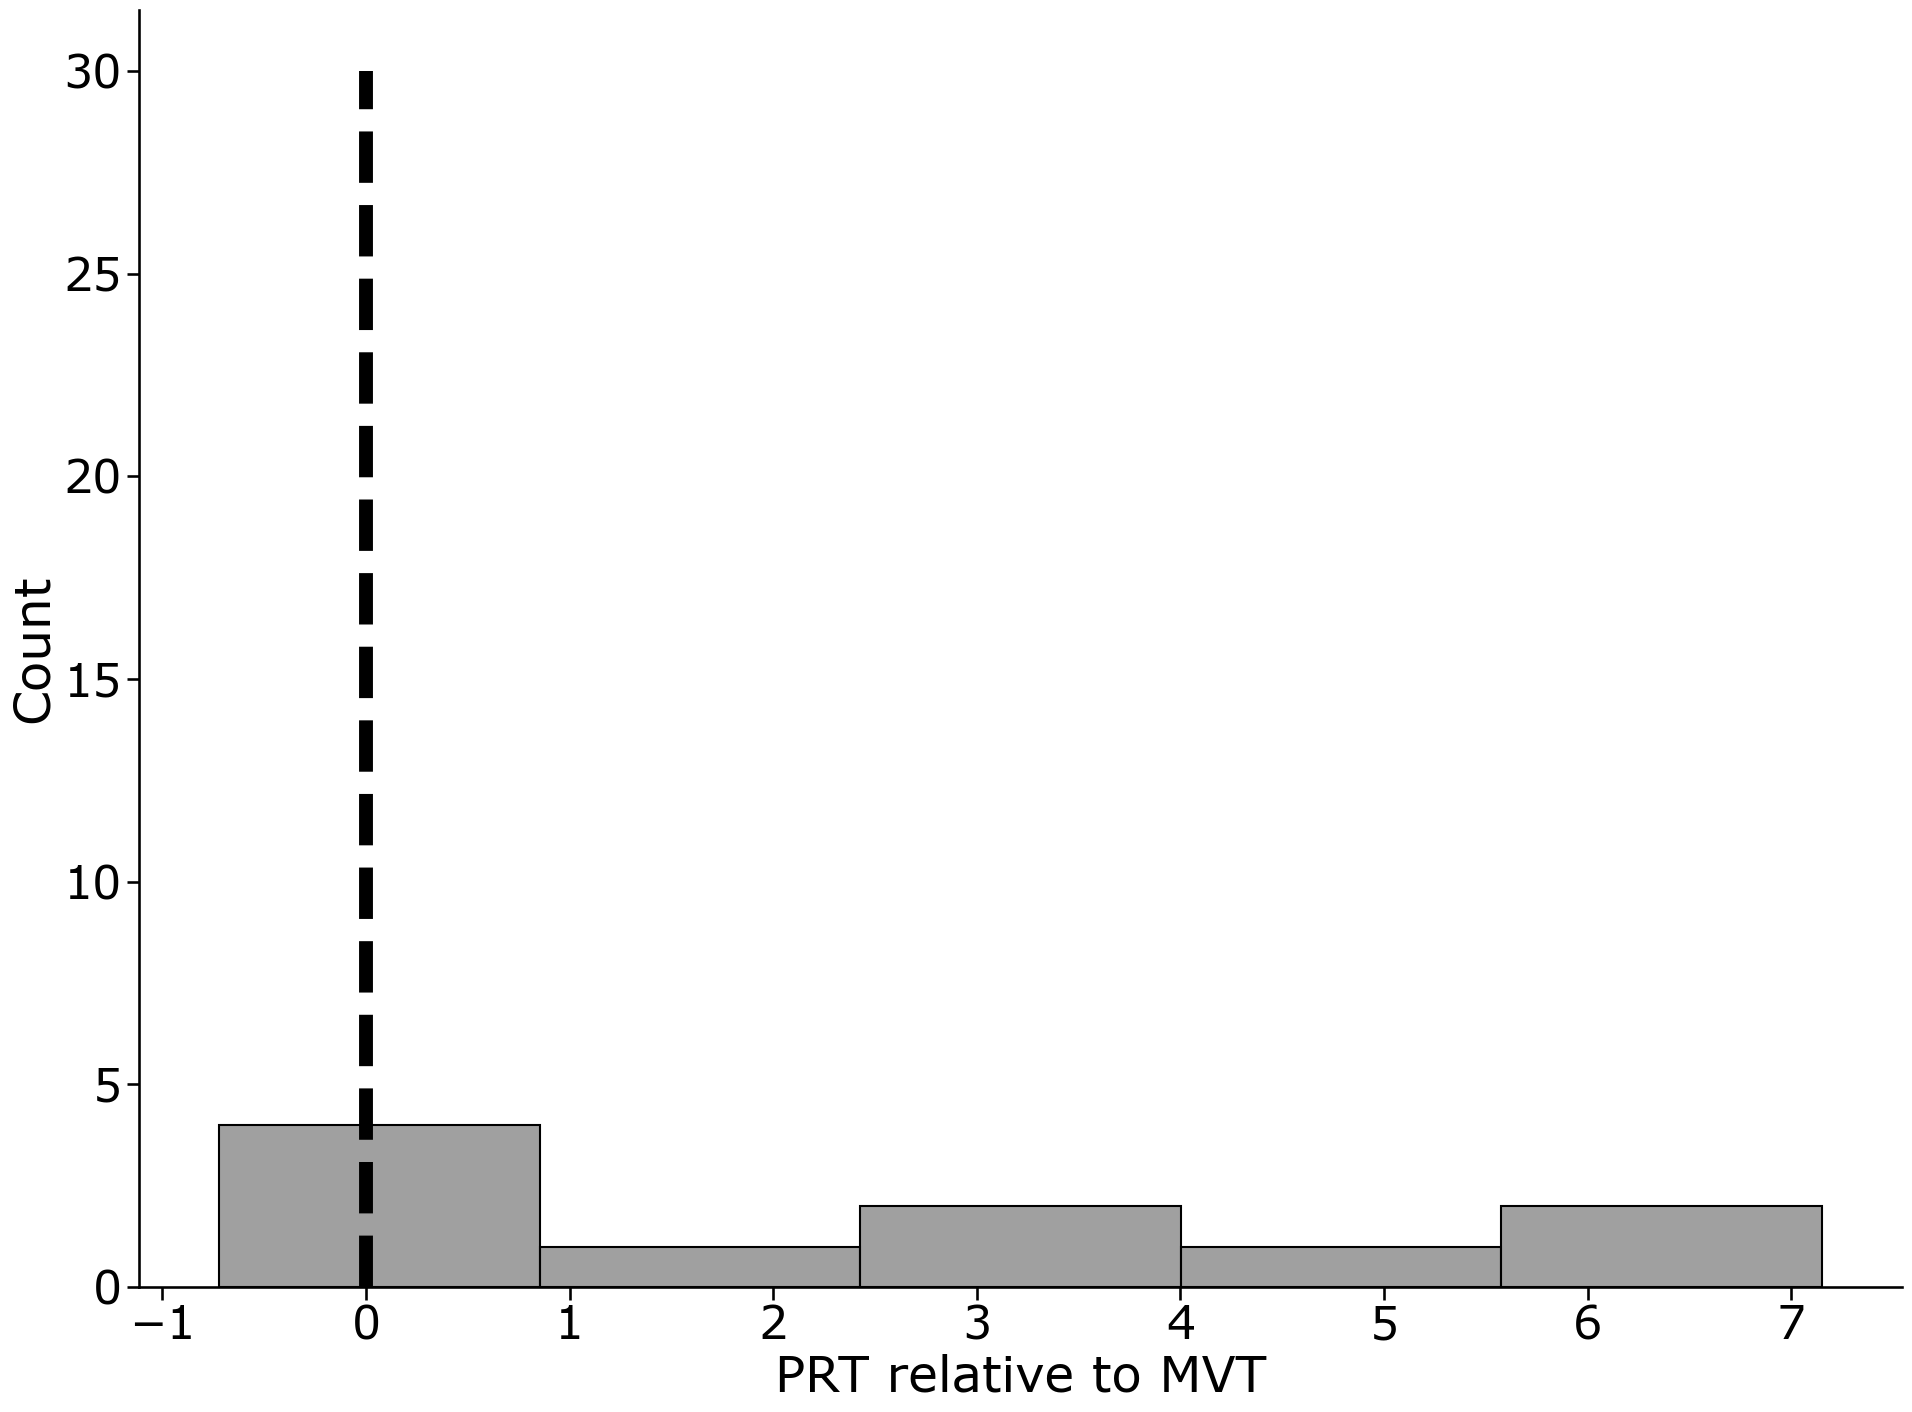

In [47]:
avgd_data = all_data.groupby(by=['sub_num']).mean(numeric_only=True).reset_index()
plt.rcParams["figure.figsize"] = (20,15)

sns.histplot(x='prt_rel_om',color='grey',data=avgd_data)
sns.despine(top=True,right=True)
plt.xlabel('PRT relative to MVT')
plt.plot([0,0],[0,30],'k--',linewidth=10)
plt.tight_layout()

plt.savefig('plots/avg_over_gal_indiv_sub.png')

In [48]:
avgd_data = all_data.groupby(by=['sub_num']).mean(numeric_only=True).reset_index()
stats.ttest_1samp(avgd_data.prt_rel_om,popmean=0)

TtestResult(statistic=np.float64(2.820224258461071), pvalue=np.float64(0.020039669472472793), df=np.int64(9))

In [50]:
len(np.unique(avgd_data.sub_num))

10

In [51]:
def label_period(row):
    if row['block'] ==1:
        return 'early'
    elif row['block'] ==2:
        return 'early'
    elif row['block'] ==3:
        return 'med'
    elif row['block'] ==4:
        return 'late'
    elif row['block'] ==5:
        return 'late'

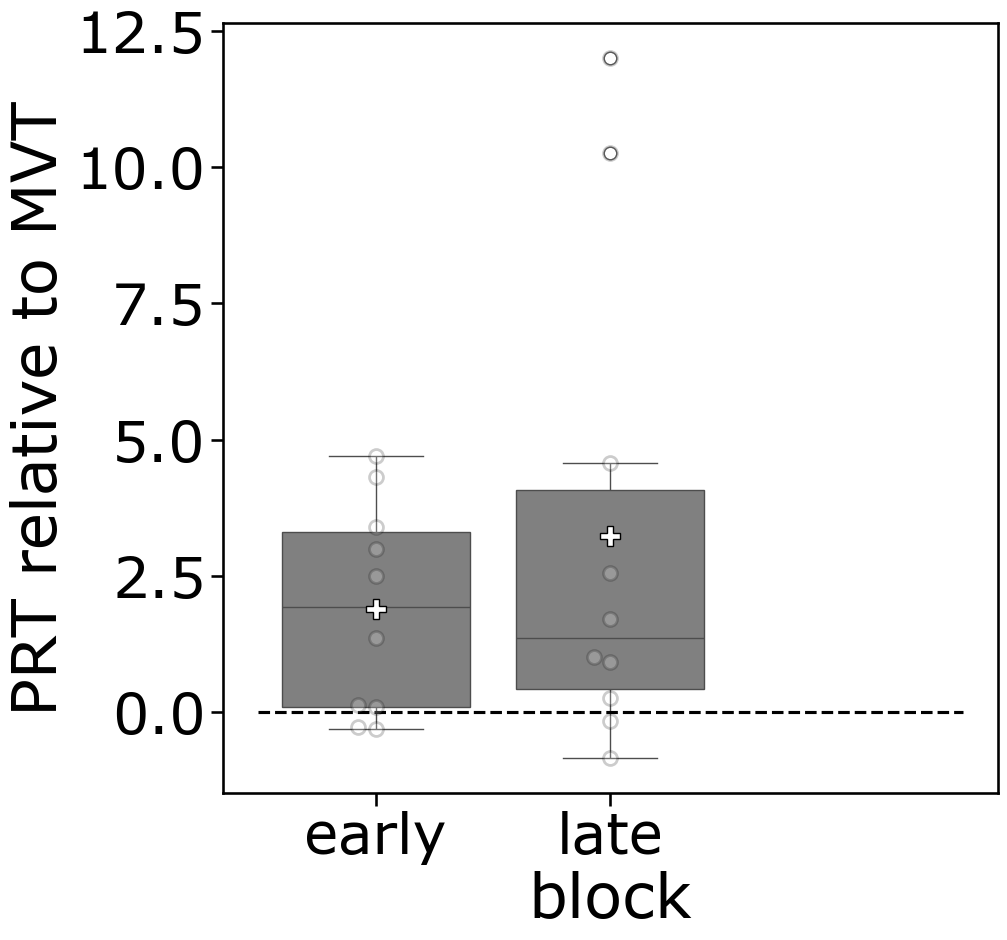

In [52]:
all_data['period'] = all_data.apply (lambda row: label_period(row), axis=1)
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=2.5)


avgd_data = all_data.groupby(by=['sub_num','period']).mean(numeric_only=True).reset_index()
#avgd_data=avgd_data.query("sub_num in @subs")
sns.swarmplot(x='period',y='prt_rel_om',color='white',edgecolor="black",linewidth=2,alpha=0.2,size=10,data=avgd_data.query(" period !='med'"))
sns.boxplot(x='period',y='prt_rel_om',color='grey',showmeans=True,
            meanprops={"marker":"P",
                       "markerfacecolor":"white", 
                       "markeredgecolor":"black",
                      "markersize":"15"},data=avgd_data.query(" period !='med'"))
plt.ylabel("PRT relative to MVT")
plt.xlabel("block")
plt.plot([-0.5,2.5],[0,0],'k--')

plt.savefig('plots/block_period.png',bbox_inches = "tight",dpi=300)

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\1183746343.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x='galaxy',y='prt_rel_om',palette='Set1',size=10,alpha=0.5,edgecolor='k',data=avgd_data)
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\1183746343.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(['poor','neutral','rich'])


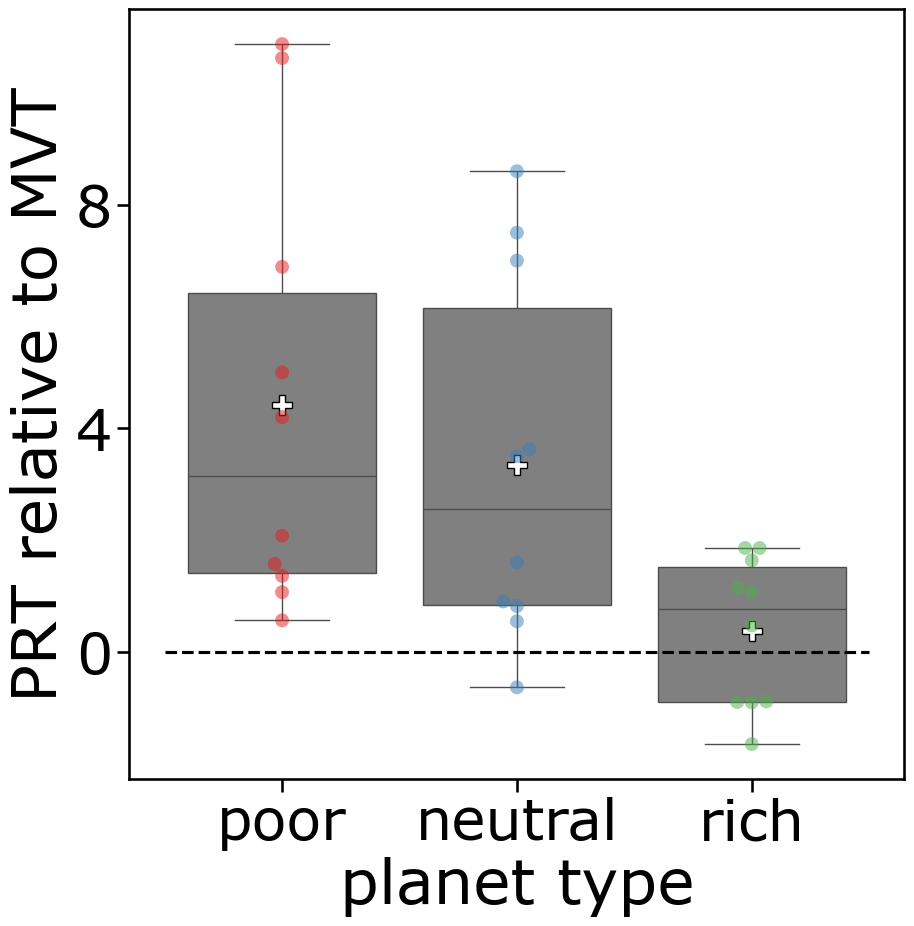

In [53]:
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=2.5)

avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean(numeric_only=True).reset_index()
sns.swarmplot(x='galaxy',y='prt_rel_om',palette='Set1',size=10,alpha=0.5,edgecolor='k',data=avgd_data)
g=sns.boxplot(x='galaxy',y='prt_rel_om',color='grey',data=avgd_data,showmeans=True,
            meanprops={"marker":"P",
                       "markerfacecolor":"white", 
                       "markeredgecolor":"black",
                      "markersize":"15"})
plt.ylabel("PRT relative to MVT")
plt.xlabel("planet type")
g.set_xticklabels(['poor','neutral','rich'])
plt.yticks([-8,-4,0,4,8])
plt.plot([-0.5,2.5],[0,0],'k--')
plt.savefig('plots/overharvesting_galaxy.png',bbox_inches = "tight",dpi=300)

In [54]:
avgd_data

,sub_num,galaxy,condition,age,n_prac,block,planet,true_planet,prt,initial_reward,...,gal_1_trans_0,gal_1_trans_1,gal_1_trans_2,gal_2_trans_0,gal_2_trans_1,gal_2_trans_2,opt_prt,opt_prt_om,prt_rel_mvt,prt_rel_om
0,0,0,1.0,100.0,0.0,2.500000,14.300000,32.400000,6.200000,102.100000,...,0.000000,0.645833,0.354167,0.275000,0.100000,0.625000,4.000000,2.000000,2.200000,4.200000
1,0,1,1.0,100.0,0.0,2.250000,12.875000,27.875000,7.125000,103.750000,...,0.000000,0.735374,0.264626,0.128571,0.228571,0.642857,4.375000,3.625000,2.750000,3.500000
2,0,2,1.0,100.0,0.0,2.733333,18.800000,39.733333,4.866667,99.400000,...,0.000000,0.636111,0.363889,0.163233,0.104305,0.732462,3.466667,3.800000,1.400000,1.066667
3,1,0,1.0,100.0,0.0,2.266667,19.533333,30.333333,3.066667,101.866667,...,0.034965,0.607226,0.357809,0.254666,0.085238,0.660096,3.266667,2.000000,-0.200000,1.066667
4,1,1,1.0,100.0,0.0,2.363636,20.727273,31.636364,3.636364,98.000000,...,0.000000,0.641865,0.358135,0.169996,0.176726,0.653278,3.363636,2.818182,0.272727,0.818182
5,1,2,1.0,100.0,0.0,2.700000,25.700000,40.000000,3.000000,99.000000,...,0.031818,0.583131,0.385051,0.148376,0.106220,0.745404,3.400000,3.900000,-0.400000,-0.900000
6,2,0,1.0,100.0,0.0,2.285714,18.214286,30.285714,3.571429,99.285714,...,0.041667,0.597222,0.361111,0.233796,0.120370,0.645833,3.500000,2.000000,0.071429,1.571429
7,2,1,1.0,100.0,0.0,2.300000,18.300000,29.900000,4.100000,99.300000,...,0.000000,0.646517,0.353483,0.102778,0.268651,0.628571,4.200000,3.200000,-0.100000,0.900000
8,2,2,1.0,100.0,0.0,2.666667,23.500000,38.833333,3.388889,100.388889,...,0.033333,0.574691,0.391975,0.114091,0.152862,0.733047,3.666667,4.277778,-0.277778,-0.888889
9,3,0,1.0,100.0,0.0,2.333333,12.000000,28.333333,7.000000,98.777778,...,0.053571,0.648810,0.297619,0.244048,0.107143,0.648810,4.111111,2.000000,2.888889,5.000000


In [55]:
avgd_data['sub_num'].unique()

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\1799945403.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x='galaxy',y='prt_rel_om',palette='Set1',size=10,alpha=0.3,edgecolor='k',data=avgd_data)
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\1799945403.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(['poor','neutral','rich'])


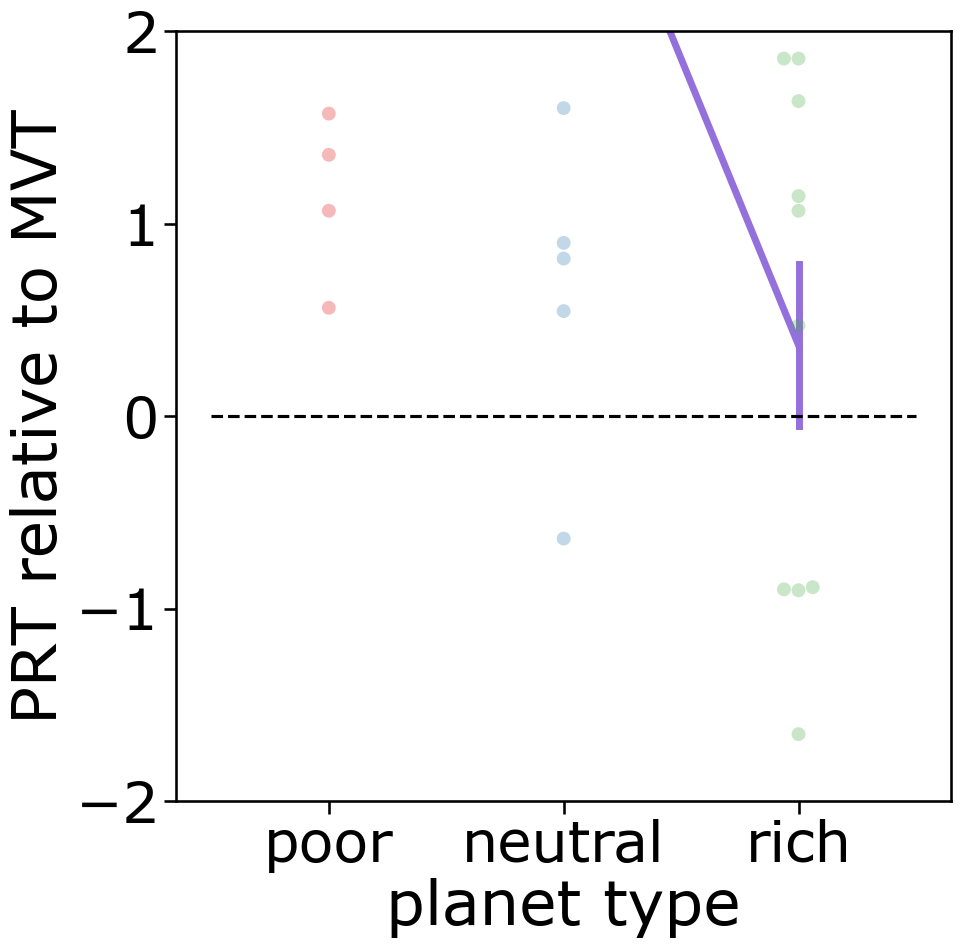

In [56]:
avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean(numeric_only=True).reset_index()
sns.swarmplot(x='galaxy',y='prt_rel_om',palette='Set1',size=10,alpha=0.3,edgecolor='k',data=avgd_data)
g=sns.lineplot(x='galaxy',y='prt_rel_om',color='mediumpurple',data=avgd_data,err_style='bars',errorbar='se',linewidth=5,err_kws={'elinewidth': 5})
plt.ylabel("PRT relative to MVT")
plt.xlabel("planet type")
g.set_xticklabels(['poor','neutral','rich'])
plt.ylim(-2,2)
plt.plot([-0.5,2.5],[0,0],'k--')
# plt.savefig('plots/overharvesting_galaxy.png',bbox_inches = "tight",dpi=300)

In [57]:
avgd_data = all_data.groupby(by=['sub_num','period']).mean(numeric_only=True).reset_index()

x=avgd_data.query("period=='early'").reset_index().prt_rel_om
y=avgd_data.query("period=='late'").reset_index().prt_rel_om

stats.ttest_rel(x,y)

TtestResult(statistic=np.float64(-1.4419545569879089), pvalue=np.float64(0.1831932450811631), df=np.int64(9))

In [58]:
avgd_data=avgd_data.query("sub_num not in @subs_to_drop & period !='med'")

x=avgd_data.query("period=='early'").reset_index().prt_rel_om
y=avgd_data.query("period=='late'").reset_index().prt_rel_om
z=x-y
stats.ttest_rel(x,y)

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\3124245455.py:6: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stats.ttest_rel(x,y)


TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(nan))

In [59]:
avgd_data = all_data.groupby(by=['sub_num']).mean(numeric_only=True).reset_index()

stats.ttest_1samp(avgd_data.prt_rel_om,popmean=0)

TtestResult(statistic=np.float64(2.820224258461071), pvalue=np.float64(0.020039669472472793), df=np.int64(9))

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\2690826120.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.barplot(x='galaxy',y='prt_rel_om',ci=68,color='grey',data=avgd_data,ax=ax)
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\2690826120.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  g=sns.pointplot(x='galaxy',y='prt_rel_om',hue='sub_num',ci=68,palette='hls',data=all_data.query("sub_num!='nan'"),ax=ax)
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\2690826120.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(['poor','neutral','rich'])


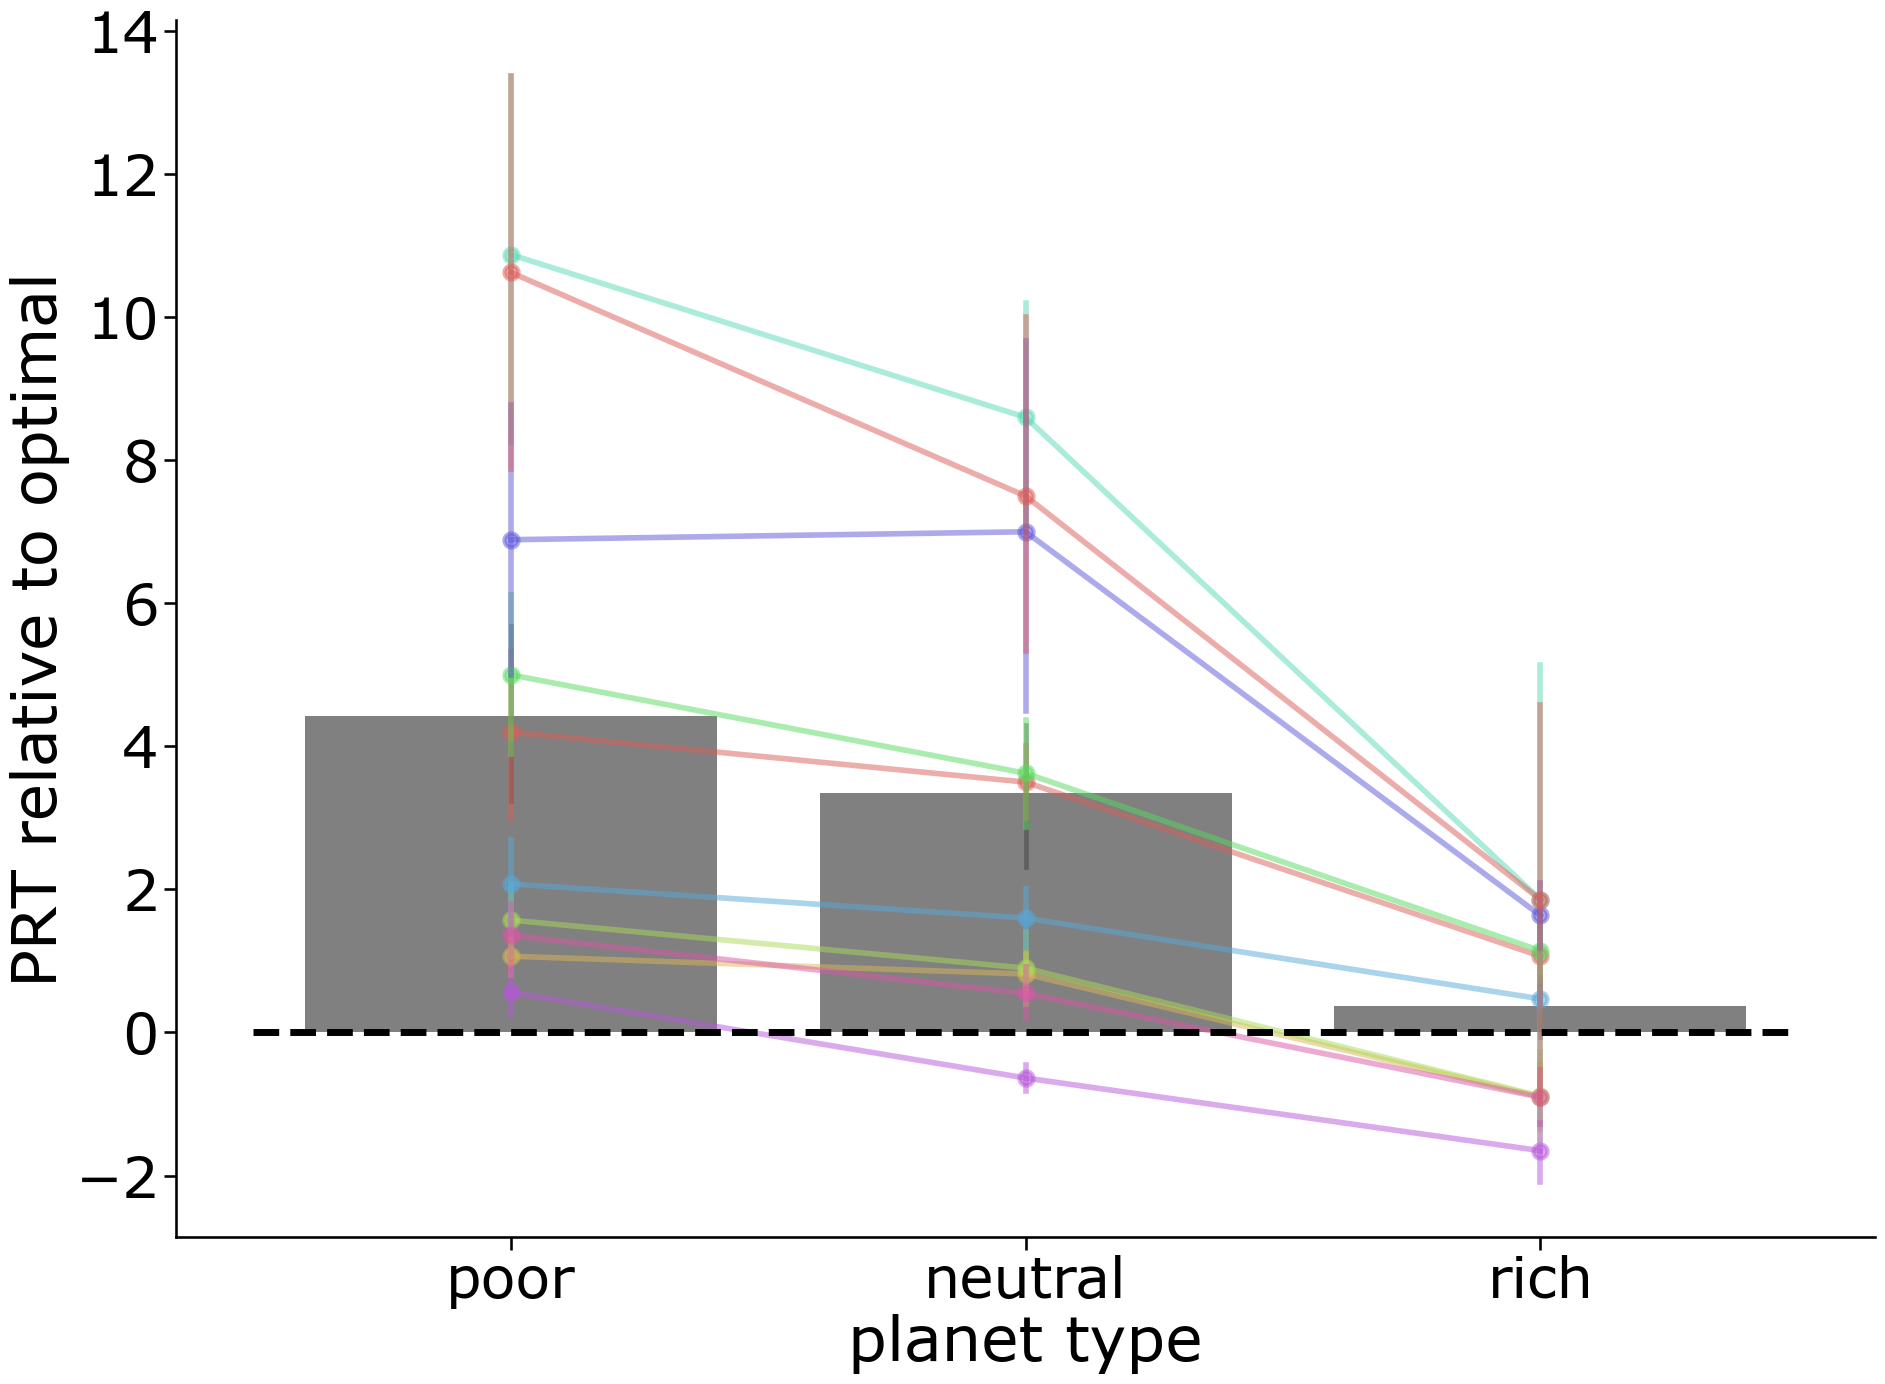

In [60]:
plt.rcParams["figure.figsize"] = (20,15)
avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean(numeric_only=True).reset_index()

fig, ax = plt.subplots()
sns.barplot(x='galaxy',y='prt_rel_om',ci=68,color='grey',data=avgd_data,ax=ax)

g=sns.pointplot(x='galaxy',y='prt_rel_om',hue='sub_num',ci=68,palette='hls',data=all_data.query("sub_num!='nan'"),ax=ax)

g.set_xticklabels(['poor','neutral','rich'])
g.set_ylabel('PRT relative to optimal')
g.set_xlabel('planet type')
sns.despine(top=True,right=True)
plt.setp(g.collections, alpha=.5) #for the markers
plt.setp(g.lines, alpha=.5)       #for the lines
g.get_legend().remove()
plt.plot([-0.5,2.5],[0,0],'k--', linewidth=5)


plt.tight_layout()
#plt.savefig('plots/galaxy_sep_indiv_sub_2022.png')

In [61]:
all_data.columns

Index(['sub_num', 'condition', 'age', 'gender', 'n_prac', 'block', 'planet',
       'true_planet', 'prt', 'initial_reward', 'leave_thresh', 'decay_list',
       'reward_list', 'total_reward', 'rt_list', 'avg_rt', 'catch_perf',
       'catch_rt', 'galaxy', 'preced_gal', 'num_in_gal', 'switch_point',
       'mean', 'mode', 'mean_post', 'mode_post', 'gal_0_trans_0',
       'gal_0_trans_1', 'gal_0_trans_2', 'gal_1_trans_0', 'gal_1_trans_1',
       'gal_1_trans_2', 'gal_2_trans_0', 'gal_2_trans_1', 'gal_2_trans_2',
       'gal_0_encount', 'gal_1_encount', 'gal_2_encount', 'opt_prt',
       'opt_prt_om', 'prt_rel_mvt', 'prt_rel_om', 'period'],
      dtype='object')

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\3449301568.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(['no switch','switch'],)


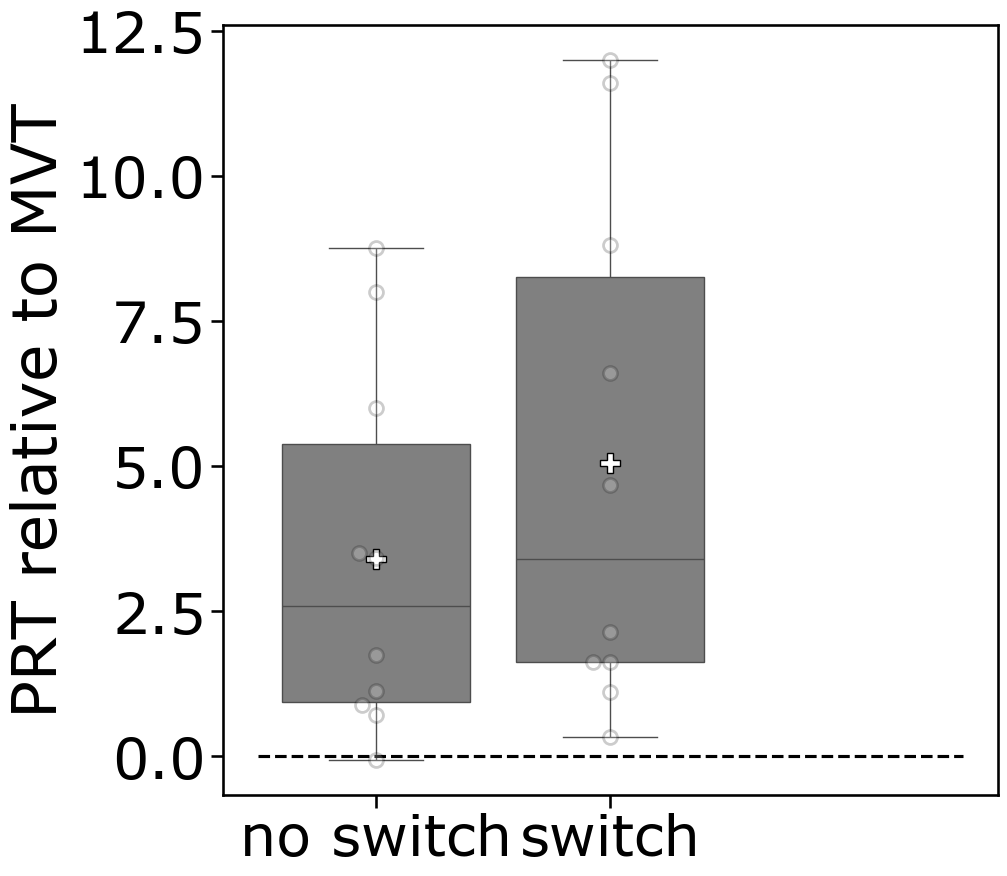

In [62]:
plt.rcParams["figure.figsize"] = (10,10)

sns.set_context('talk',font_scale=2.5)
avgd_data = all_data.query("galaxy!=2").groupby(by=['sub_num','switch_point']).mean(numeric_only=True).reset_index()
sns.swarmplot(x='switch_point',y='prt_rel_om',color='white',edgecolor="black",linewidth=2,alpha=0.2,size=10,data=avgd_data)
g=sns.boxplot(x='switch_point',y='prt_rel_om',color='grey',data=avgd_data,showmeans=True,
            meanprops={"marker":"P",
                       "markerfacecolor":"white", 
                       "markeredgecolor":"black",
                      "markersize":"15"})
plt.ylabel("PRT relative to MVT")
plt.xlabel("")
g.set_xticklabels(['no switch','switch'],)
plt.plot([-0.5,2.5],[0,0],'k--')

plt.savefig('plots/overharveting uncertainty.png',bbox_inches = "tight",dpi=300)

In [63]:
subs = np.unique(all_data.sub_num)
x=[]
for sub in subs:
    temp = all_data.query("sub_num==@sub & galaxy==2").prt_rel_om
    t,p = stats.ttest_1samp(temp,popmean=0)
    
    if p < 0.05:
        if t <0:
            x+=[-1]
        else:
            x+=[1]
    else:
        x+=[0]
        
x

[0, 0, 0, 0, 0, 1, 1, -1, -1, 0]

In [64]:
len(np.where(np.array(x)==1)[0])

2

In [65]:
len(np.where(np.array(x)==0)[0])

6

In [66]:
len(np.where(np.array(x)==-1)[0])

2

In [67]:
avgd_data = all_data.groupby(by=['sub_num','galaxy']).mean().reset_index()


TypeError: agg function failed [how->mean,dtype->object]

In [ ]:
print(stats.ttest_rel(avgd_data.query('galaxy==2').prt,avgd_data.query('galaxy==1').prt))

print(stats.ttest_rel(avgd_data.query('galaxy==1').prt,avgd_data.query('galaxy==0').prt))


Ttest_relResult(statistic=19.77493870559956, pvalue=8.406888612203487e-39)
Ttest_relResult(statistic=12.573217216755653, pvalue=2.4525462945216073e-23)


In [ ]:
print(stats.ttest_1samp(avgd_data.query('galaxy==0').prt_rel_om,popmean=0))
print(stats.ttest_1samp(avgd_data.query('galaxy==1').prt_rel_om,popmean=0))
print(stats.ttest_1samp(avgd_data.query('galaxy==2').prt_rel_om,popmean=0))

Ttest_1sampResult(statistic=6.923115011049861, pvalue=2.679084964561683e-10)
Ttest_1sampResult(statistic=9.00593130494536, pvalue=5.358558884154392e-15)
Ttest_1sampResult(statistic=1.3864788714050844, pvalue=0.16828278724279733)


C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\84096226.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  g=sns.pointplot(x='galaxy',y='prt_rel_om',ci=68,color='grey',data=avgd_data.query("sub_num!='nan'"))
C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\84096226.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(['poor','neutral','rich'])


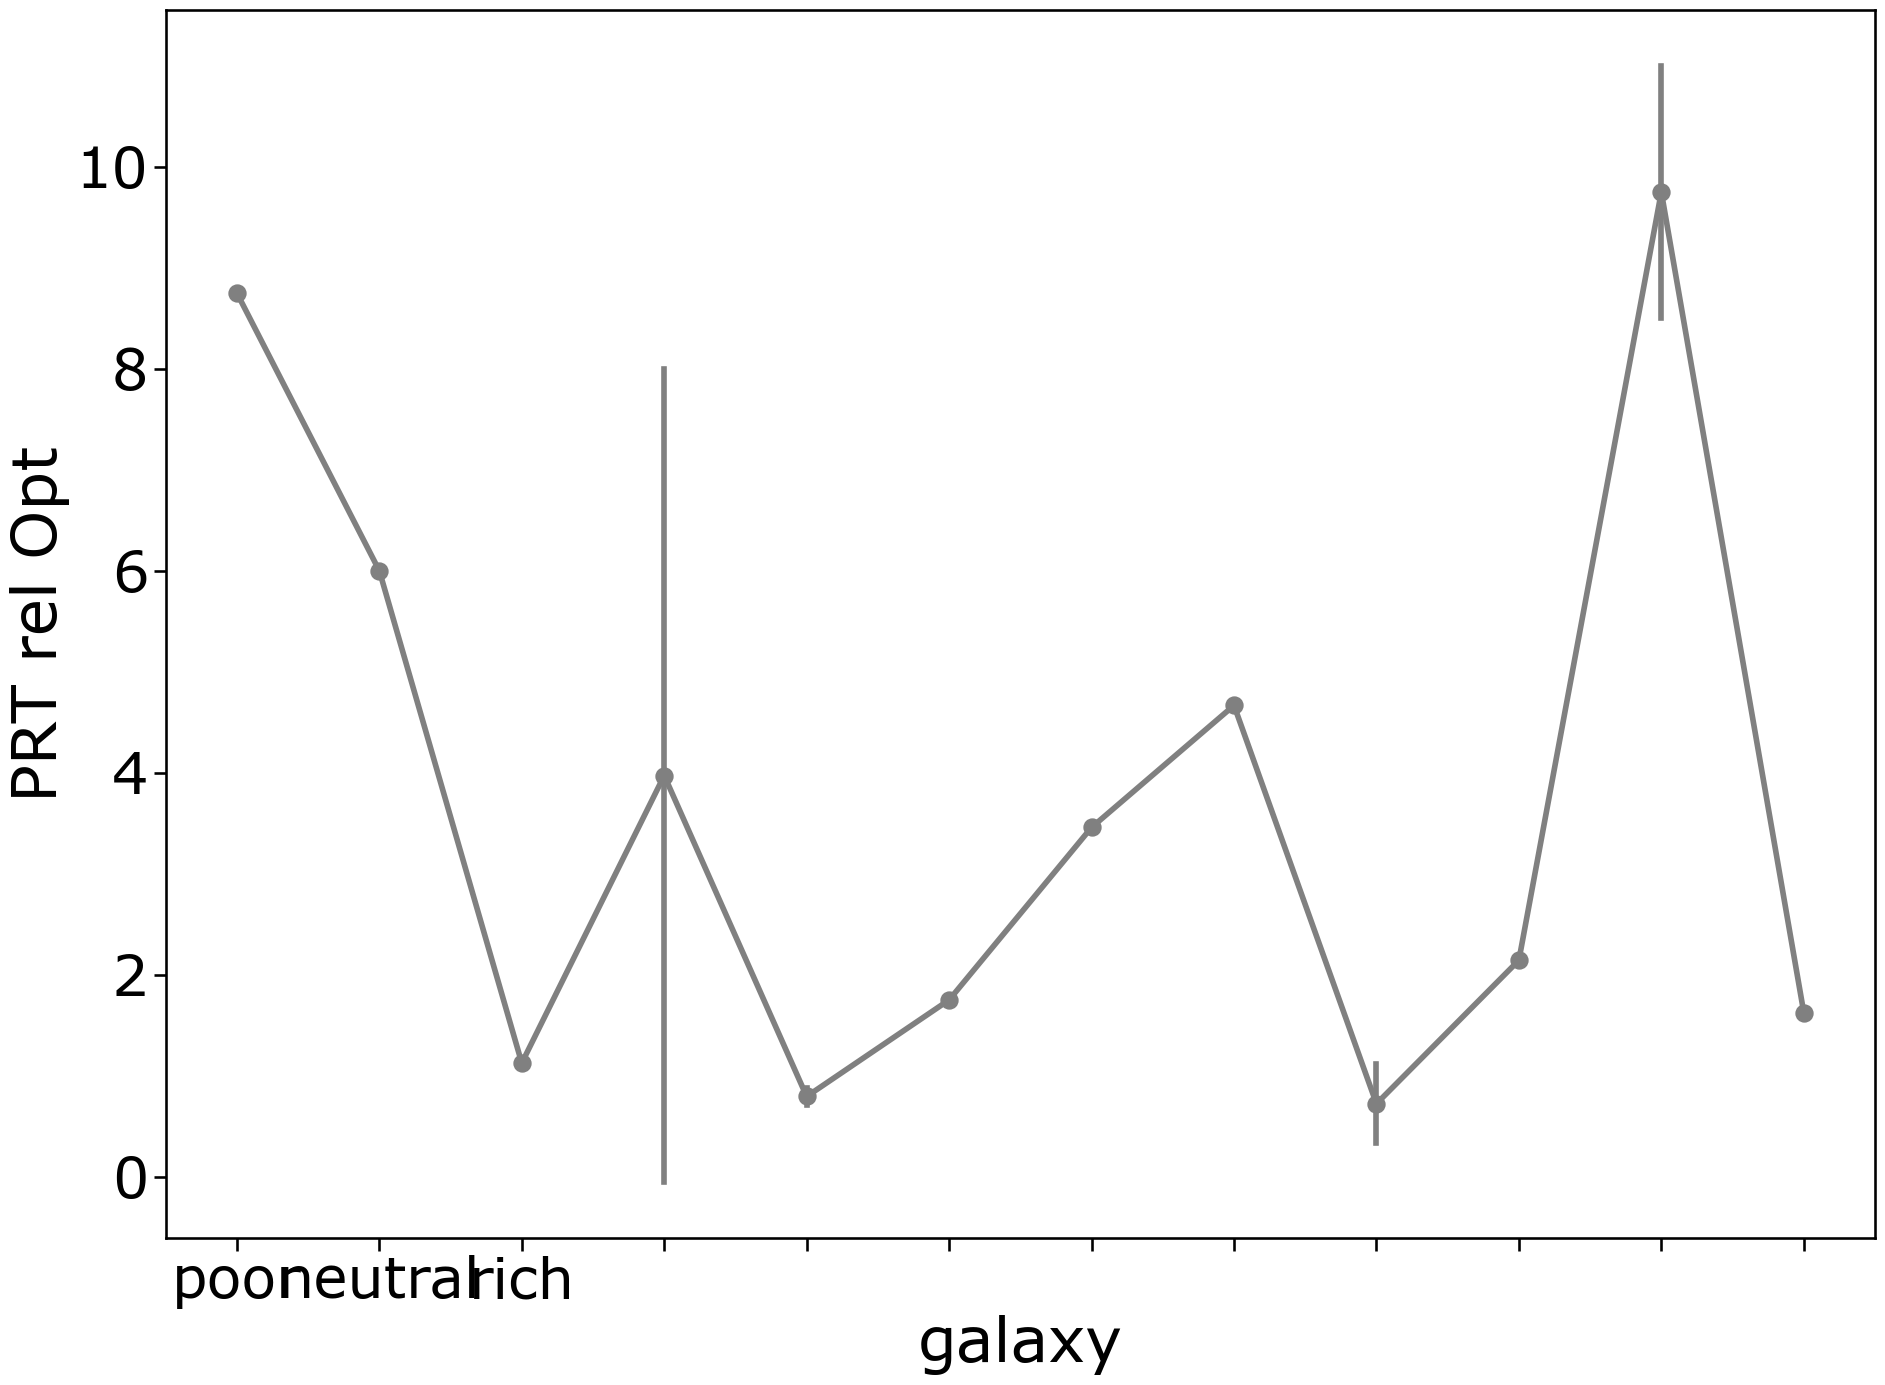

In [68]:
plt.rcParams["figure.figsize"] = (20,15)

g=sns.pointplot(x='galaxy',y='prt_rel_om',ci=68,color='grey',data=avgd_data.query("sub_num!='nan'"))
g.set_xticklabels(['poor','neutral','rich'])
g.set_ylabel('PRT rel Opt')

plt.tight_layout()
plt.savefig('plots/galaxy_sep_avg.png')

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\427557165.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.pointplot(x='num_in_gal',y='prt_rel_om',hue='preced_gal',hue_order=[0,2],palette=['r','g'],ci=68,aspect=10,data=temp.query('galaxy==1 &(preced_gal==0 | preced_gal==2) &num_in_gal <=3'))


AttributeError: Line2D.set() got an unexpected keyword argument 'aspect'

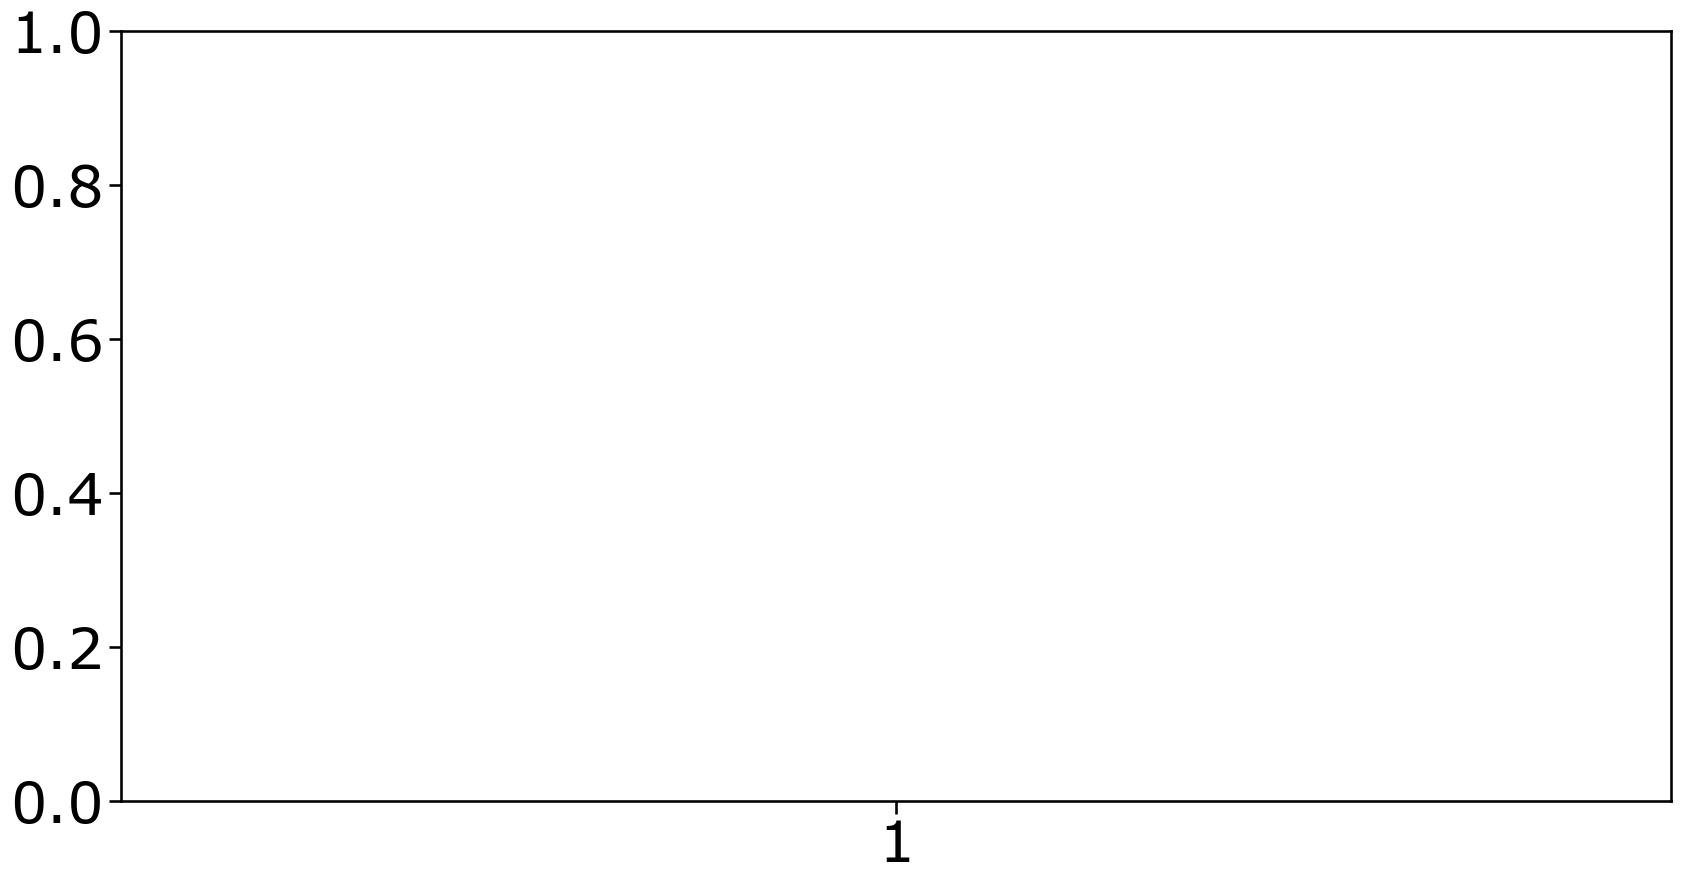

In [69]:
plt.rcParams["figure.figsize"] = (20,10)

temp=all_data.groupby(by=['sub_num','galaxy','preced_gal','num_in_gal']).prt_rel_om.mean().reset_index()
sns.pointplot(x='num_in_gal',y='prt_rel_om',hue='preced_gal',hue_order=[0,2],palette=['r','g'],ci=68,aspect=10,data=temp.query('galaxy==1 &(preced_gal==0 | preced_gal==2) &num_in_gal <=3'))
plt.ylabel("PRT relative to MVT")
plt.xlabel("Planet in neutral galaxy")

plt.legend().remove()
savefig=1
#plt.tight_layout()
plt.savefig("plots/recency_effects_neutral_only_2021.png")

C:\Users\zyfxl\AppData\Local\Temp\ipykernel_25144\3596334875.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.pointplot(x='num_in_gal',y='prt_rel_om',hue='preced_gal',hue_order=[1,2],palette=['b','g'],ci=68,aspect=10,data=temp.query('galaxy==0 &(preced_gal==1 | preced_gal==2)  &num_in_gal <=3'))


AttributeError: Line2D.set() got an unexpected keyword argument 'aspect'

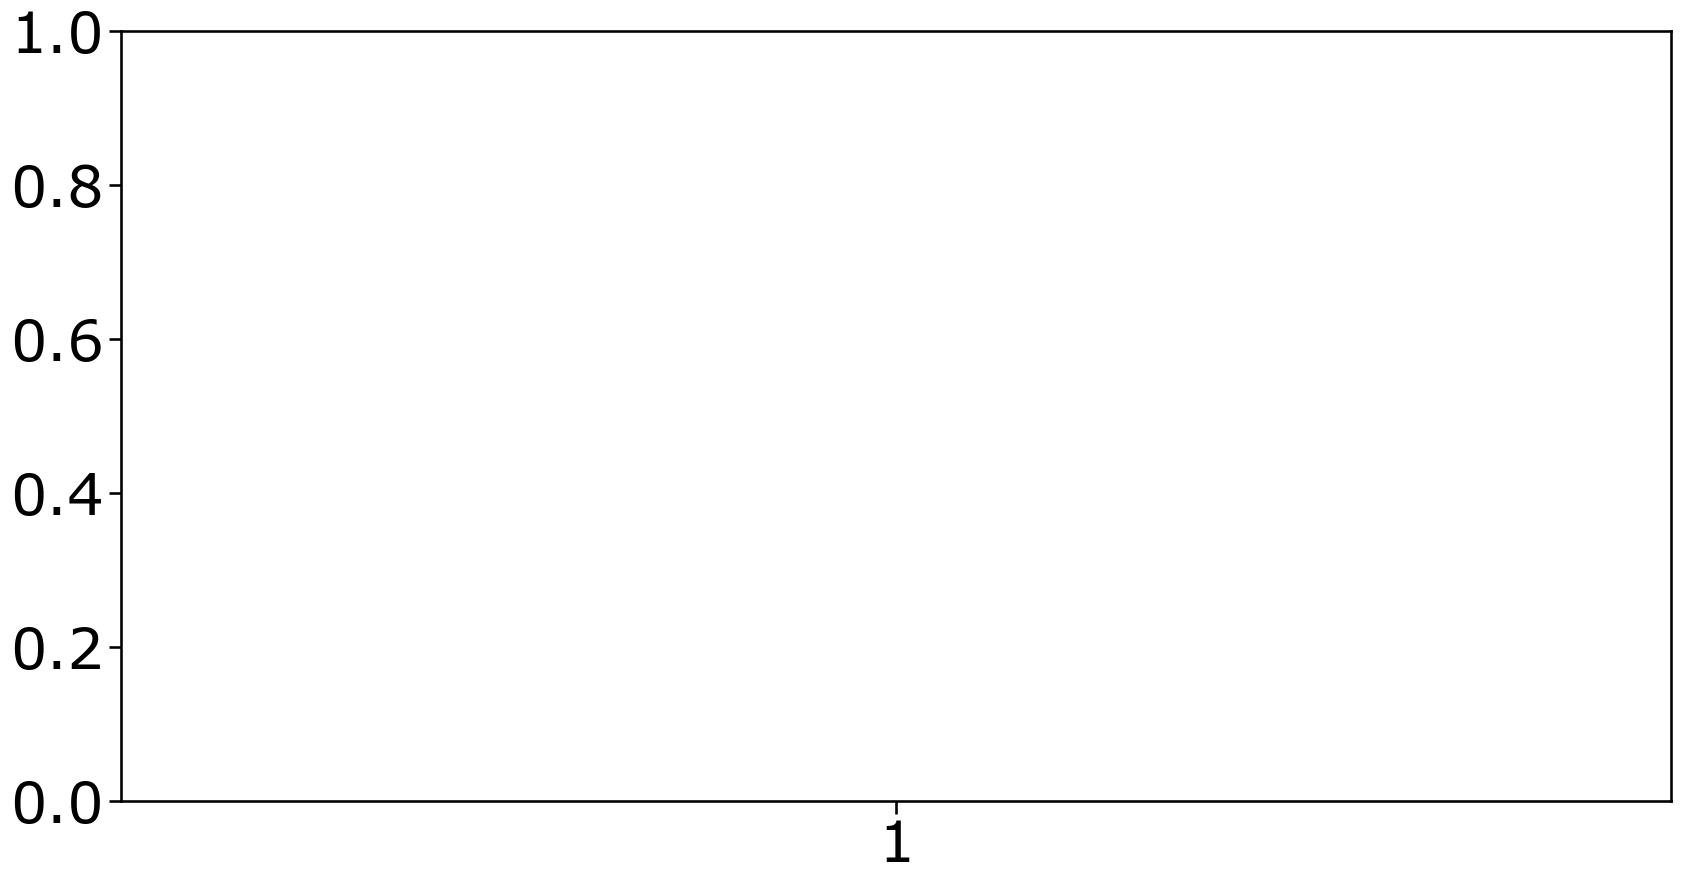

In [70]:
plt.rcParams["figure.figsize"] = (20,10)

temp=all_data.groupby(by=['sub_num','galaxy','preced_gal','num_in_gal']).prt_rel_om.mean().reset_index()
sns.pointplot(x='num_in_gal',y='prt_rel_om',hue='preced_gal',hue_order=[1,2],palette=['b','g'],ci=68,aspect=10,data=temp.query('galaxy==0 &(preced_gal==1 | preced_gal==2)  &num_in_gal <=3'))
plt.ylabel("PRT relative to MVT")
plt.xlabel("Planet in poor galaxy")

plt.legend().remove()
savefig=1
#plt.tight_layout()
if savefig:
    plt.savefig("plots/recency_effects_poor_only_2021.png")

# Reaction Time check 

In [71]:
def make_sub_rt_df(sub_num):
    print(sub_num)
    sub_df = pd.DataFrame(columns=['sub_num','condition','block','planet_num','stay_num','stay?','galaxy','prior_galaxy','num_in_gal'])
    curr_sub = all_data.query("sub_num=="+str(sub_num)).reset_index()
    n_planet = max(curr_sub.planet) + 1
    cond_num = curr_sub.condition[0]

    for p in range(n_planet):
        curr_planet = curr_sub.query("planet=="+str(p)).reset_index()
        curr_block = curr_planet.block[0]
        curr_galaxy = curr_planet.galaxy[0]
        curr_prior_galaxy = curr_planet.preced_gal[0]
        num_in_gal = curr_planet.num_in_gal[0]
        rt = curr_planet.rt_list[0]
        n_stay = len(rt)
        
        if n_stay == 0:
            rt = [np.nan]
            n_stay = 1
        tmp = pd.DataFrame({'sub_num':[sub_num]*n_stay, 'condition':[cond_num]*n_stay, 
                        'block':[curr_block]*n_stay,'planet_num':[p]*n_stay,'stay_num':range(n_stay),'stay?':[1]*(n_stay-1) + [0],
                        'galaxy':[curr_galaxy]*n_stay,'prior_galaxy':[curr_prior_galaxy]*n_stay,'num_in_gal':[num_in_gal]*n_stay,
                       'rt':rt})
        sub_df = pd.concat([sub_df,tmp])
    sub_df = sub_df.query("rt!=0")
    sub_df['zlog_rt'] = stats.zscore(np.log(sub_df['rt']),nan_policy='omit')
    return sub_df

def make_rt_df(subs):
    rt_df = pd.DataFrame(columns=['sub_num','condition','block','planet_num','stay_num','stay?','galaxy','prior_galaxy','num_in_gal'])

    for sub in subs:
        sub_df = make_sub_rt_df(sub)
        rt_df = pd.concat([rt_df,sub_df])
    return rt_df

In [72]:
subs = list(set(all_data.sub_num.tolist()))
rt_df = make_rt_df(subs)

0
1
2
3
4
5
6
7
8
9


In [73]:
len(np.unique(rt_df.sub_num))

10

In [74]:
def label_switch(row):
    if row['num_in_gal'] ==1:
        return 'switch'
    else:
        return 'no_switch'
    
def label_group(row):
    if row['alpha'] <0.8:
        return 'below'
    else:
        return 'above'
    


In [75]:
rt_df['switch'] = rt_df.apply (lambda row: label_switch(row), axis=1)
all_data['switch'] =  all_data.apply (lambda row: label_switch(row), axis=1)

In [76]:
x=all_data.groupby(by=['sub_num','switch']).mean(numeric_only=True).prt_rel_om.reset_index()

y=x.query("switch=='no_switch'").prt_rel_om.reset_index(drop=True)
z=x.query("switch=='switch'").prt_rel_om.reset_index(drop=True)
diff=z-y
stats.ttest_1samp(diff,popmean=0)

TtestResult(statistic=np.float64(1.9515226831965802), pvalue=np.float64(0.08276406784851428), df=np.int64(9))

In [77]:
avg_switch=rt_df.query("stay_num==1").groupby(by=['sub_num','switch']).mean(numeric_only=True).reset_index()
#subs_to_drop += [192,177,163,158,110,99,94,29,78,2,39,77,106,143,169,175,48,64,8,22,34,164]

#avg_switch=avg_switch.query("sub_num in @subs")

In [78]:
pal=sns.color_palette("Paired")

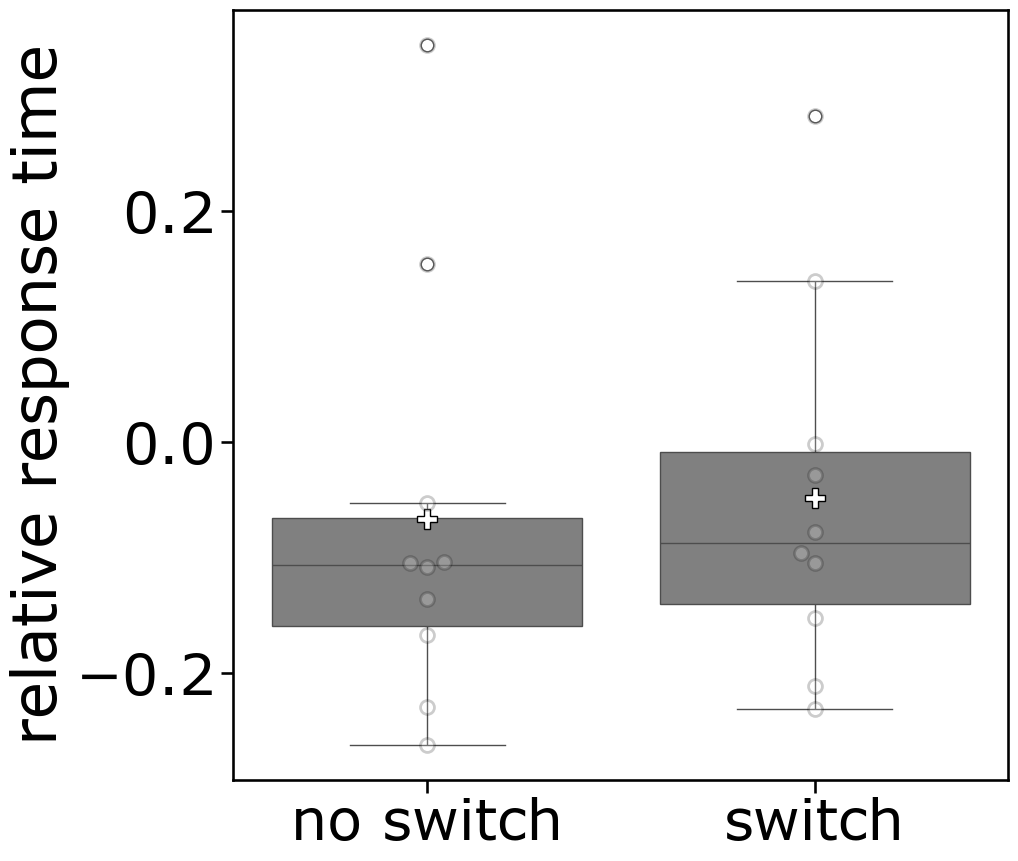

In [79]:
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=2.5)

avg_switch=rt_df.query("stay_num==1").groupby(by=['sub_num','switch']).mean(numeric_only=True).reset_index()

sns.boxplot(x='switch',y='zlog_rt',color='grey',order=['no_switch','switch'],showmeans=True,
            meanprops={"marker":"P",
                       "markerfacecolor":"white", 
                       "markeredgecolor":"black",
                      "markersize":"15"},data=avg_switch)
sns.swarmplot(x='switch',y='zlog_rt',color='white',edgecolor="black",linewidth=2,alpha=0.2,size=10,data=avg_switch)

plt.xticks([0,1],['no switch','switch'])
plt.xlabel('')
plt.ylabel('relative response time')
plt.savefig("plots/switch_zlog_rt.png",bbox_inches = "tight",dpi=300)

In [ ]:
avg_switch=all_data.query("galaxy!=2").groupby(by=['sub_num','switch']).mean().reset_index()

y=avg_switch.query("switch=='no_switch'").prt_rel_om.reset_index(drop=True)
z=avg_switch.query("switch=='switch'").prt_rel_om.reset_index(drop=True)
diff=z-y
stats.ttest_1samp(diff,popmean=0)

Ttest_1sampResult(statistic=4.672685571343366, pvalue=8.135712428785701e-06)

In [ ]:
avg_switch=rt_df.query("stay_num==1").groupby(by=['sub_num','switch']).mean().reset_index()

x=avg_switch.query("switch=='switch'").zlog_rt.reset_index(drop=True)-avg_switch.query("switch=='no_switch'").zlog_rt.reset_index(drop=True)
print(stats.ttest_1samp(x,popmean=0,nan_policy='omit'))


temp = pd.DataFrame({'sub_num':avg_switch.query("switch=='switch'").sub_num.reset_index(drop=True),'zlog_rt':x})

Ttest_1sampResult(statistic=2.645000360675243, pvalue=0.009311089367316103)


In [ ]:
len(np.unique(avg_switch.sub_num))

116

In [ ]:
x=avg_switch.query("switch=='switch'").zlog_rt.reset_index(drop=True)
y=avg_switch.query("switch=='no_switch'").zlog_rt.reset_index(drop=True)
stats.ttest_rel(x,y)

Ttest_relResult(statistic=2.321950973673055, pvalue=0.022442745014618383)

In [ ]:
print(stats.ttest_1samp(x-y,popmean=0))


Ttest_1sampResult(statistic=2.321950973673055, pvalue=0.022442745014618383)


In [ ]:
#temp=pd.merge(temp,quic)
params = pd.read_csv("../../../model/fitting/experiment1k_rescorla_wagner/params_val_adaptive_discount_10_10_3.csv")

params=params.join(temp.set_index('sub_num'), on='sub_num').dropna()
#params

In [ ]:
#params = pd.read_csv("../../../model/fitting/experiment1k_rescorla_wagner/params_val_adaptive_discount_10_10_3.csv")
#params=params.join(temp.set_index('sub_num'), on='sub_num').dropna()
params['alphaz']=-np.log(-1 + (10/np.array(params['alpha'])))
params['gamma_basez']=-np.log(-1 + ((12)/(np.array(params['gamma_base']+2))));
params['gamma_coefz']=-np.log(-1 + (6/(np.array(params['gamma_coef']+3))));
x=all_data.groupby(by=['sub_num','switch']).mean().prt_rel_om.reset_index()

y=x.query("switch=='no_switch'").prt_rel_om.reset_index(drop=True)
z=x.query("switch=='switch'").prt_rel_om.reset_index(drop=True)
diff=z-y
params['switch_explicit']= diff



In [ ]:
pg.corr(params['alphaz'],params['zlog_rt'],method='kendall')

,n,r,CI95%,r2,adj_r2,p-val,power
kendall,116,0.170074,"[-0.01, 0.34]",0.028925,0.011738,0.007612,0.449297


In [ ]:
pg.corr(params['gamma_coefz'],params['switch_explicit'],method='kendall')

,n,r,CI95%,r2,adj_r2,p-val,power
kendall,116,0.153935,"[-0.03, 0.33]",0.023696,0.006416,0.015712,0.380497


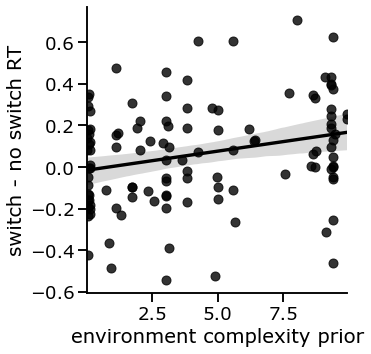

In [ ]:
sns.set_context('talk',font_scale=1.1)

sns.lmplot(x='alpha',y='zlog_rt',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.xlabel("environment complexity prior")
plt.ylabel("switch - no switch RT")
plt.savefig("plots/alpha_zlog_rt_corr.png",bbox_inches = "tight",dpi=300)

In [ ]:
pg.corr(params['alphaz'],params['gamma_coefz'],method='kendall')

,n,r,CI95%,r2,adj_r2,p-val,power
kendall,116,-0.331375,"[-0.48, -0.16]",0.109809,0.094054,2.944709e-07,0.956818


In [ ]:
%%R params

params$alpha2 <- params$alphaz^2


#fit quadratic regression model
quadraticModel <- lm(gamma_coefz ~ alpha + alpha2, data=params)

#view model summary
summary(quadraticModel)


Call:
lm(formula = gamma_coefz ~ alpha + alpha2, data = params)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.2270 -0.1609 -0.1166  0.0312  2.4156 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.28178    0.10039   2.807  0.00589 ** 
alpha       -0.02653    0.01475  -1.799  0.07465 .  
alpha2       0.02092    0.00489   4.279 3.96e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.5147 on 113 degrees of freedom
Multiple R-squared:  0.2266,	Adjusted R-squared:  0.2129 
F-statistic: 16.55 on 2 and 113 DF,  p-value: 4.957e-07



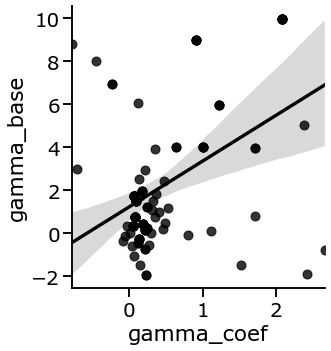

In [ ]:
sns.lmplot(x='gamma_coef',y='gamma_base',order=1,scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)


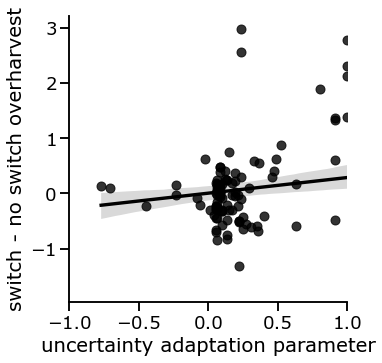

In [ ]:
sns.set_context('talk',font_scale=1.1)

sns.lmplot(x='gamma_coef',y='switch_explicit',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.xlabel("uncertainty adaptation parameter")
plt.ylabel("switch - no switch overharvest")
plt.xlim([-1,1])
#plt.ylim([-0.5,0.5])
plt.savefig("plots/gamma_coef_overharvesting_corr.png",bbox_inches = "tight",dpi=300)

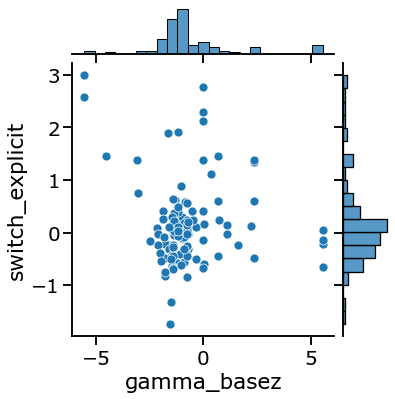

In [ ]:
sns.jointplot(x='gamma_basez',y='switch_explicit',data=params)


In [ ]:
%load_ext rpy2.ipython


The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


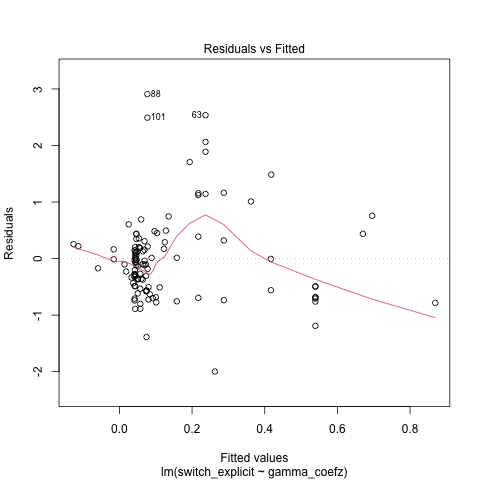

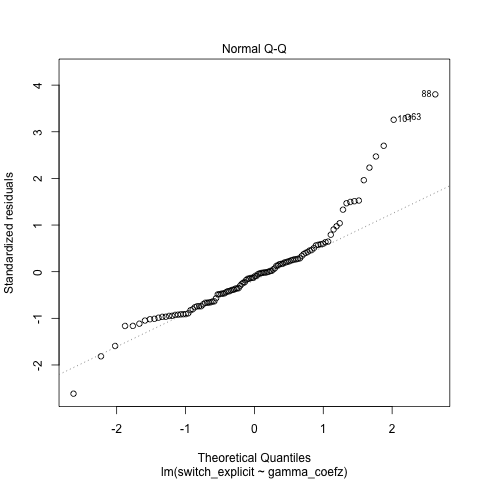

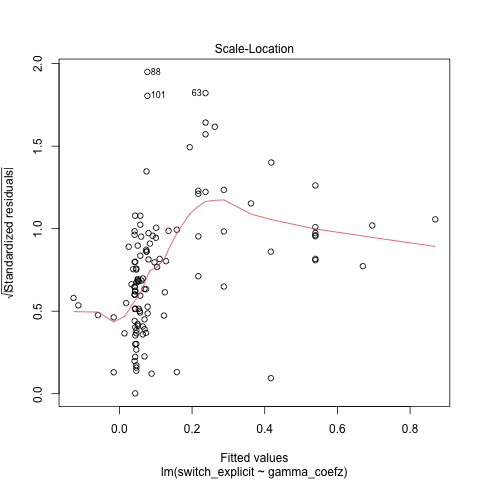

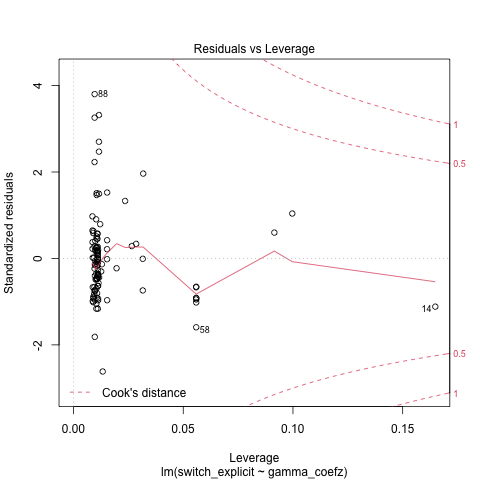

In [ ]:
%%R -i params


model<-lm(switch_explicit~gamma_coefz,data=params)
summary(model)
plot(model)


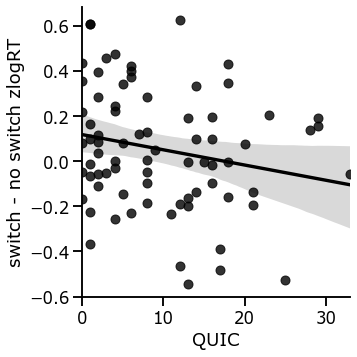

In [ ]:
sns.set_context('talk',font_scale=1.0)

sns.lmplot(x='total_score',y='zlog_rt',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.xlabel("QUIC")
plt.ylabel("switch - no switch zlogRT")
plt.savefig("plots/quic_zlog_rt_corr.png",bbox_inches = "tight",dpi=300)

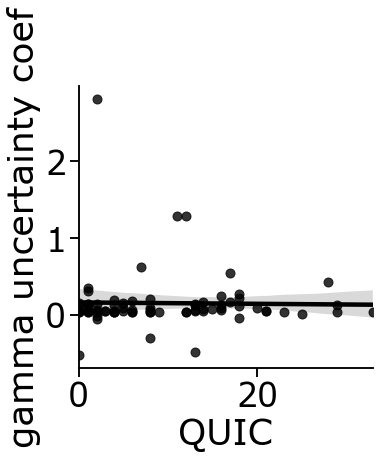

In [ ]:

sns.lmplot(x='total_score',y='gamma_coefz',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.xlabel("QUIC")
plt.ylabel("gamma uncertainty coef")
plt.savefig("plots/quic_gamma_coef_corr.png",bbox_inches = "tight",dpi=300)

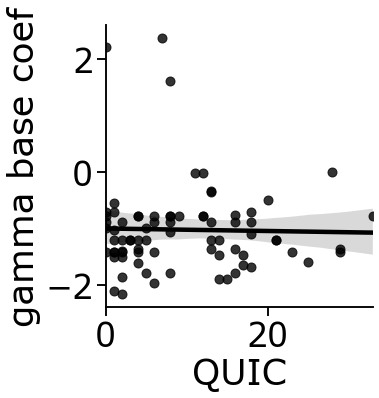

In [ ]:
sns.lmplot(x='total_score',y='gamma_basez',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.xlabel("QUIC")
plt.ylabel("gamma base coef")
plt.savefig("plots/quic_gamma_base_corr.png",bbox_inches = "tight",dpi=300)

In [ ]:
def label_quic_group(row):
    if row['total_score'] <8:
        return 'low'
    elif row['total_score'] >8:
        return 'high'
    else:
        return 'median'
    

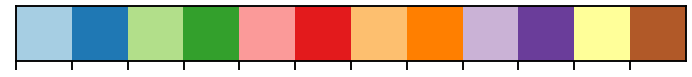

In [ ]:
params['quic_group'] = params.apply (lambda row: label_quic_group(row), axis=1)
sns.palplot(sns.color_palette("Paired"))

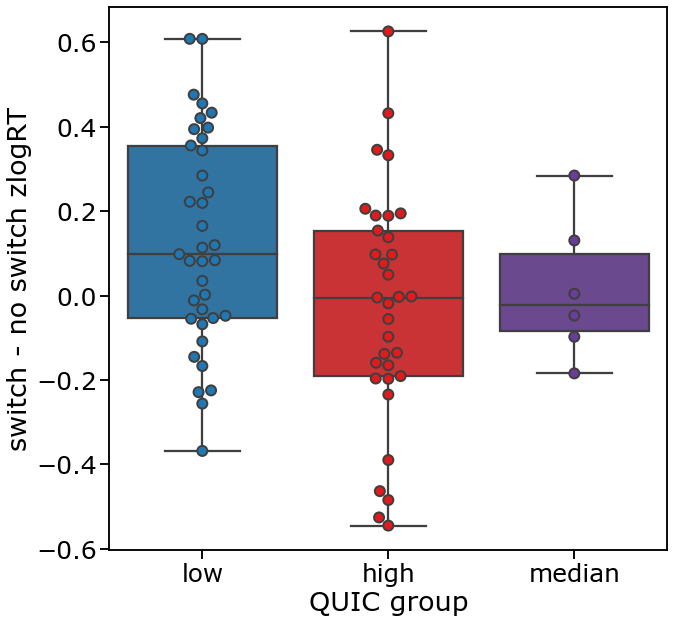

In [ ]:
sns.set_context('talk',font_scale=1.5)
my_pal = sns.color_palette("Paired")
sns.boxplot(x='quic_group',y='zlog_rt',palette=[my_pal[1],my_pal[5],my_pal[9]],data=params)
sns.swarmplot(x='quic_group',y='zlog_rt',size=10,linewidth=2,palette=[my_pal[1],my_pal[5],my_pal[9]],data=params)
plt.ylabel("switch - no switch zlogRT")
plt.xlabel("QUIC group")
plt.savefig("plots/quic_zlog_rt.png",bbox_inches = "tight",dpi=300)

<AxesSubplot:xlabel='quic_group', ylabel='alphaz'>

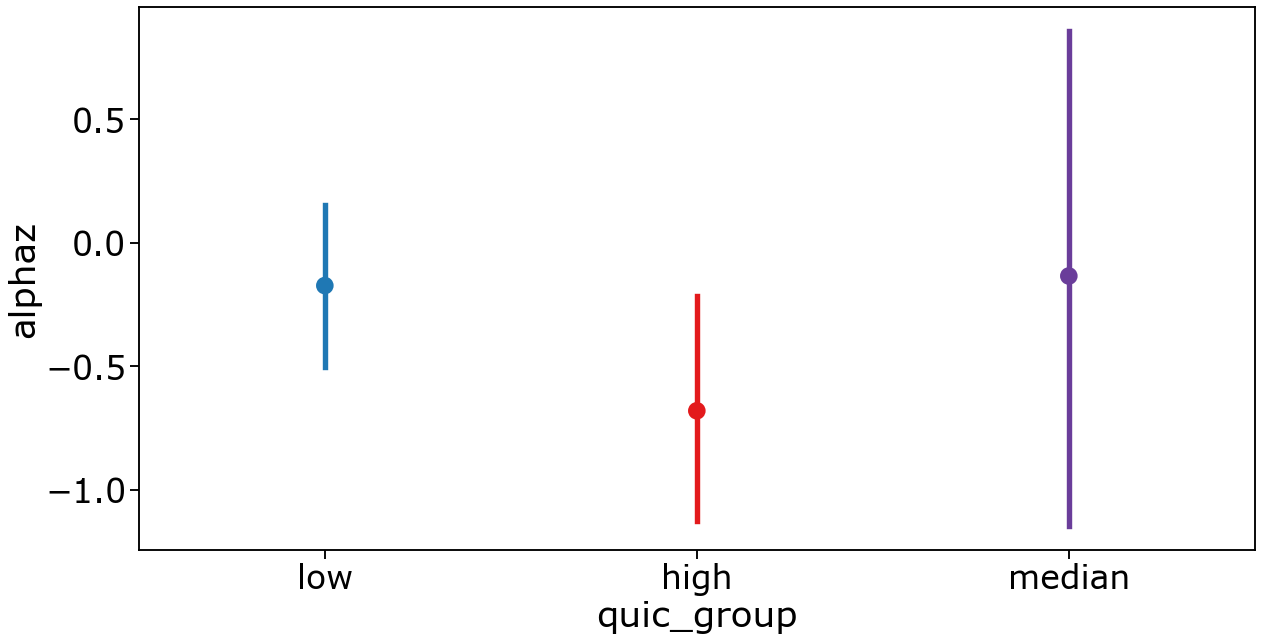

In [ ]:
my_pal = sns.color_palette("Paired")

sns.pointplot(x='quic_group',y='alphaz',palette=[my_pal[1],my_pal[5],my_pal[9]],ci=68,data=params)


In [ ]:
high=params.query("quic_group=='high'").zlog_rt
low=params.query("quic_group=='low'").zlog_rt

stats.ttest_ind(high,low)

Ttest_indResult(statistic=-2.4912096537460573, pvalue=0.015176502124824192)

In [ ]:
sns.set_context('talk',font_scale=1.2)

sns.lmplot(x='alpha',y='zlog_rt',scatter_kws={'color':'k'},line_kws={'color':'k'},data=params)
plt.ylabel('switch RT - no switch RT')
plt.xlabel('structure learning parameter')
#plt.savefig("plots/alpha_trans_switch_zlog_rt.png",bbox_inches = "tight",dpi=300)

NameError: name 'params' is not defined

<AxesSubplot:xlabel='switch_group', ylabel='zlog_rt'>

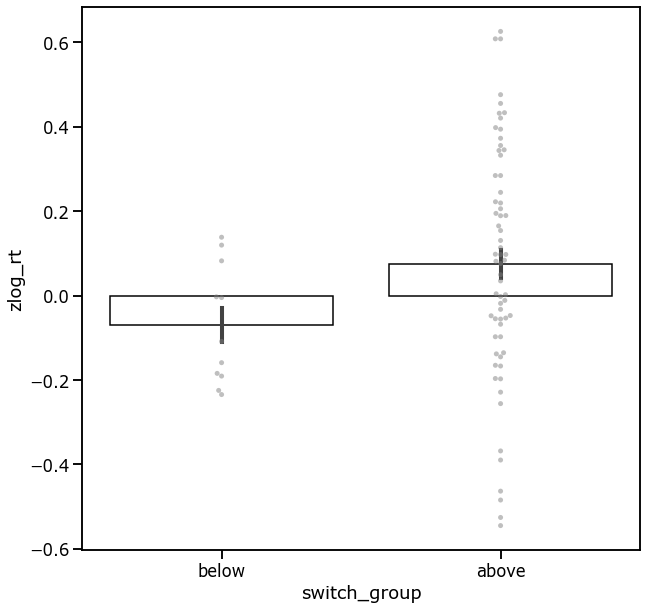

In [ ]:
sns.barplot(x='switch_group',y='zlog_rt',color='white',edgecolor='black',ci=68,data=params)
sns.swarmplot(x='switch_group',y='zlog_rt',color='grey',edgecolor="black",alpha=0.5,data=params)

In [ ]:
pg.corr(params['alphaz'],params['zlog_rt'],method='kendall')

,n,r,CI95%,r2,adj_r2,p-val,power
kendall,76,0.233599,"[0.01, 0.44]",0.054568,0.028666,0.003535,0.533885


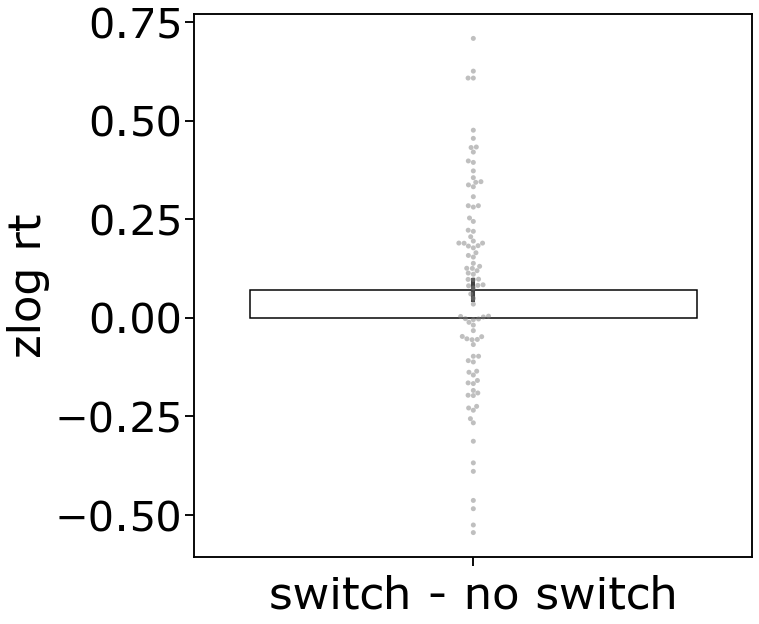

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=2.5)
sns.barplot(y='zlog_rt',color='white',edgecolor='black',ci=68,data=temp)
sns.swarmplot(y='zlog_rt',color='grey',edgecolor="black",alpha=0.5,data=temp)

plt.xlabel('switch - no switch')
plt.ylabel('zlog rt')
plt.savefig("plots/switch_zlog_rt_one_bar.png",bbox_inches = "tight",dpi=300)

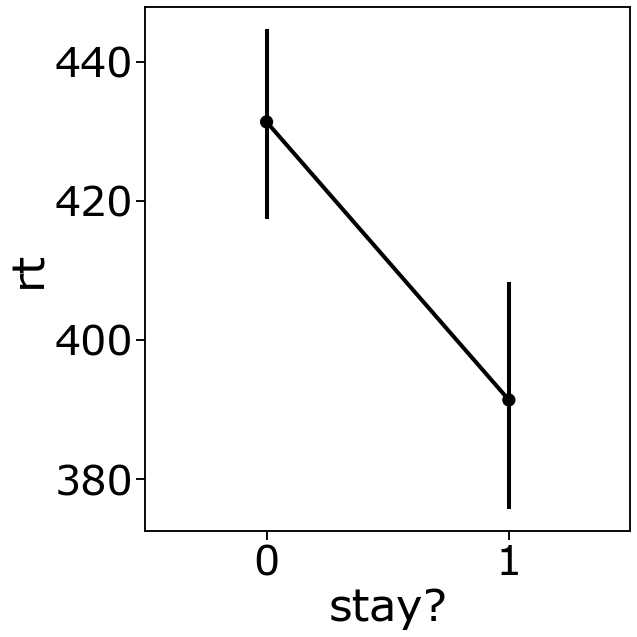

In [ ]:
avg = rt_df.groupby(by=['sub_num',"stay?"]).mean().reset_index()


sns.pointplot(x='stay?',y='rt',color='k',ci=68,data=avg)
plt.tight_layout()
plt.savefig("plots/stay_leave_rt.png")

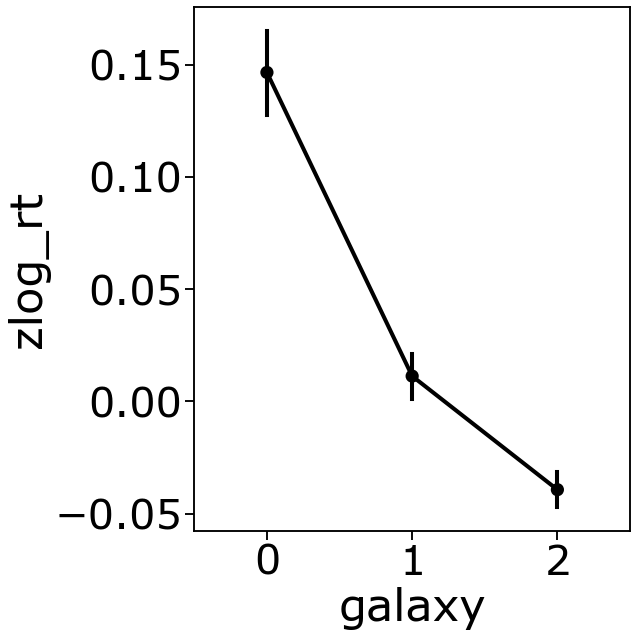

In [ ]:
avg = rt_df.groupby(by=['sub_num',"galaxy"]).mean().reset_index()

sns.pointplot(x='galaxy',y='zlog_rt',ci=68,color='k',data=avg)
plt.tight_layout()

plt.savefig("plots/galaxy_rt.png")

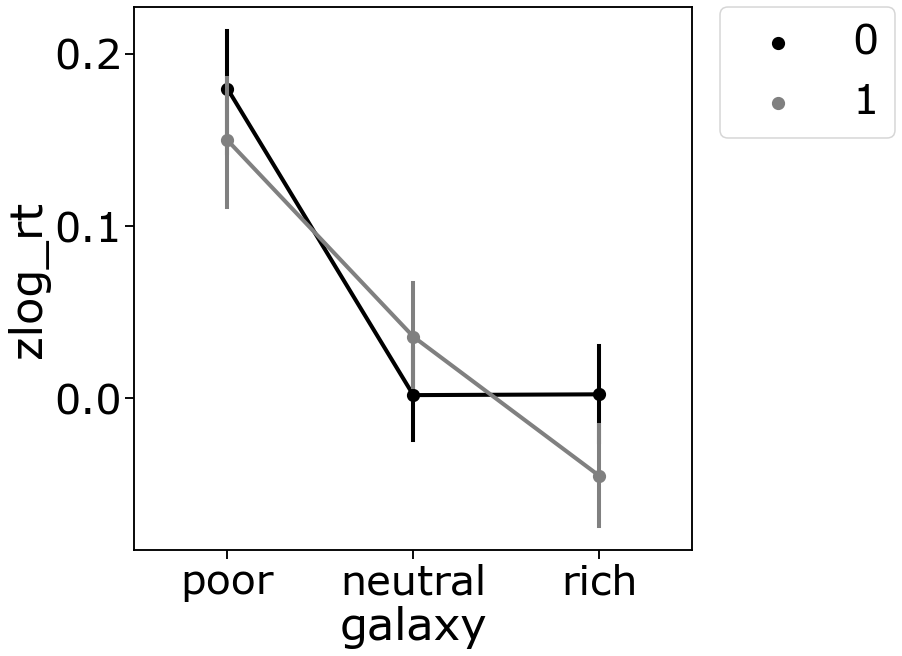

In [ ]:
avg = rt_df.groupby(by=['sub_num',"stay?","galaxy"]).mean().reset_index()

g=sns.pointplot(x='galaxy',y='zlog_rt',hue="stay?",palette=['black','grey'],legend_out=False,ci=68,data=avg)
g.set_xticklabels(['poor','neutral','rich'])

plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#plt.legend(labels=['leave','stay'])

plt.savefig("plots/galaxy_rt_staay.png")

<AxesSubplot:xlabel='num_in_gal', ylabel='zlog_rt'>

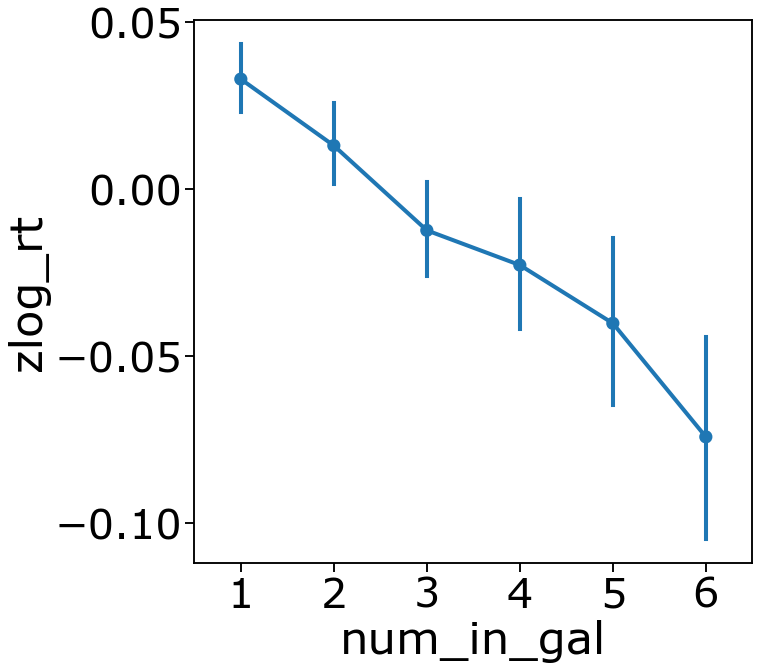

In [ ]:
avg = rt_df.groupby(by=['sub_num',"num_in_gal"]).mean().reset_index()
sns.pointplot(x='num_in_gal',y='zlog_rt',ci=68,data=avg.query("num_in_gal <= 6"))


(-0.5, 6.05)

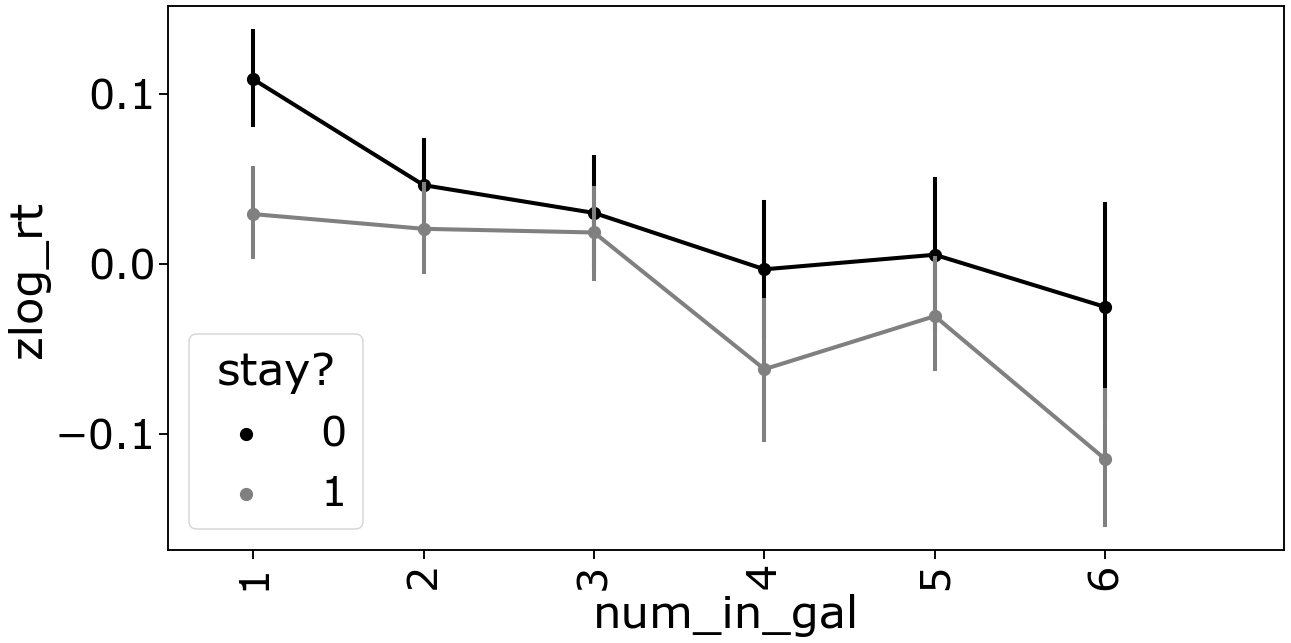

In [ ]:
plt.rcParams["figure.figsize"] = (20,10)

avg = rt_df.groupby(by=['sub_num',"num_in_gal","stay?"]).mean().reset_index()
sns.pointplot(x='num_in_gal',y='zlog_rt',hue="stay?",palette=['black','grey'],ci=68,data=avg.query("num_in_gal <= 6"))
plt.xticks(rotation=90)
plt.xlim([-0.5,6.05])

# correlate w/ model parameters

In [ ]:
params = pd.read_csv("params_2022.csv")

rt_df=pd.merge(rt_df, params, on='sub_num')
all_data=pd.merge(all_data, params, on='sub_num')
diff=pd.merge(diff, params, on='sub_num')

In [ ]:
sns.set_context('talk',font_scale=3)


In [ ]:
sns.lmplot(x='gamma',y='total_score',data=all_data)

KeyError: "['total_score'] not in index"

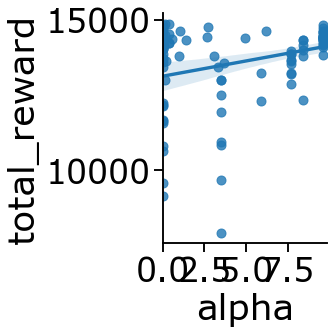

In [ ]:
sns.set_context('talk',font_scale=2)

avg = all_data.groupby(by=['sub_num','alpha']).mean().reset_index()

sns.lmplot(x='alpha',y='total_reward',data=avg)

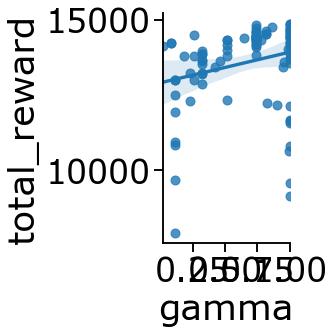

In [ ]:
avg = all_data.groupby(by=['sub_num','gamma']).mean().reset_index()

sns.lmplot(x='gamma',y='total_reward',data=avg)

Ttest_indResult(statistic=1.2614387049107507, pvalue=0.21020743729416597)


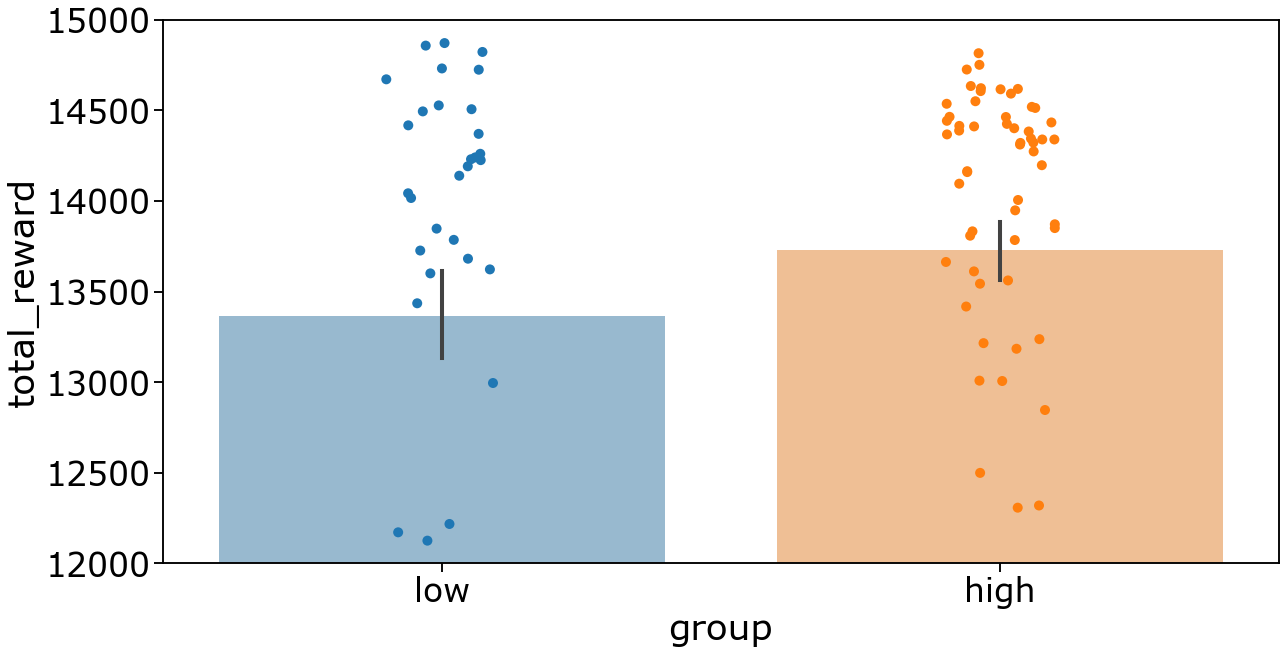

In [ ]:
avg = all_data.groupby(by=['sub_num','alpha']).mean().reset_index()

avg['group'] =avg.apply (lambda row: label_group(row), axis=1)
g=sns.barplot(x='group',y='total_reward',alpha=0.5,ci=68,data=avg)
sns.stripplot(x='group',y='total_reward',s=10,data=avg)
g.set_ylim([12000,15000])
print(stats.ttest_ind(avg.query("group=='high'").total_reward,avg.query("group=='low'").total_reward))
plt.savefig('plots/total_reward_v_alpha_large.png',bbox_inches = "tight",dpi=300)

In [ ]:
avg['rho_2_trans_0'] = rho_2_trans_0
avg['rho_2_trans_1'] = rho_2_trans_1

Ttest_indResult(statistic=1.9535199479513468, pvalue=0.05366906106672878)


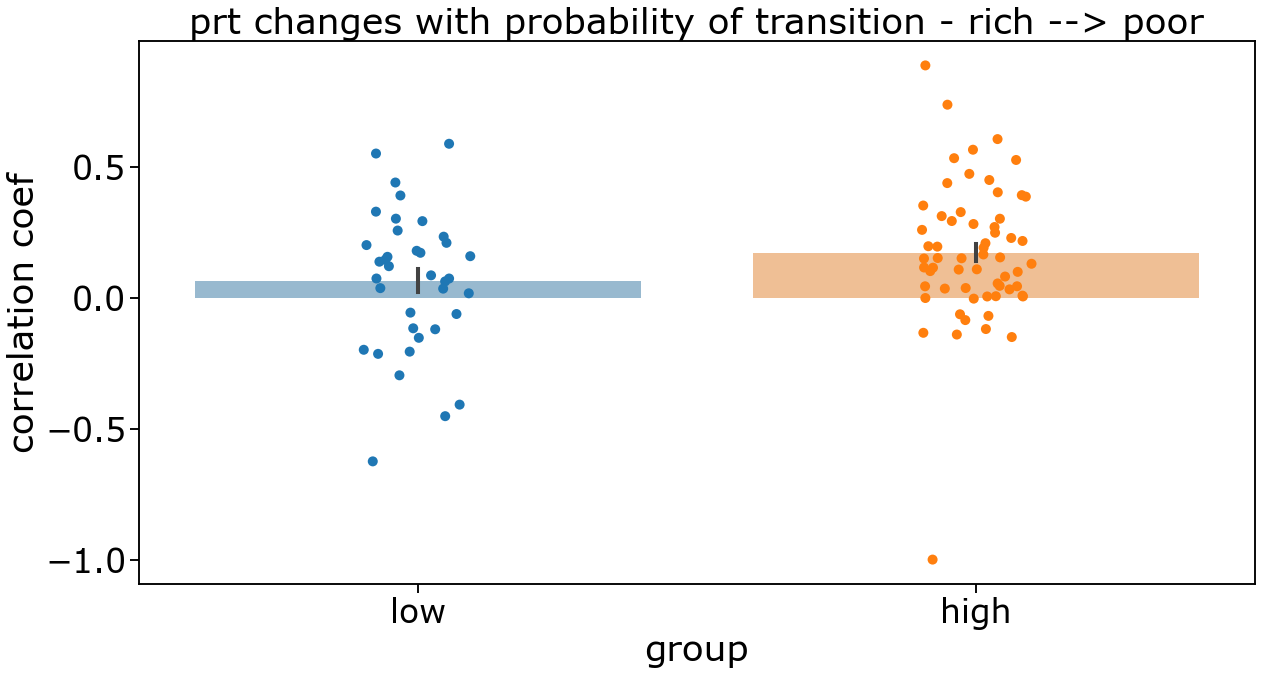

In [ ]:
g=sns.barplot(x='group',y='rho_2_trans_0',alpha=0.5,ci=68,data=avg)
sns.stripplot(x='group',y='rho_2_trans_0',s=10,data=avg)
g.set_ylabel('correlation coef')
g.set_title('prt changes with probability of transition - rich --> poor')
print(stats.ttest_ind(avg.query("group=='high'").rho_2_trans_0,avg.query("group=='low'").rho_2_trans_0))
plt.savefig('plots/rho_2_0_v_alpha_large.png',bbox_inches = "tight",dpi=300)

Ttest_indResult(statistic=-1.0746309166226926, pvalue=0.28523358486155304)


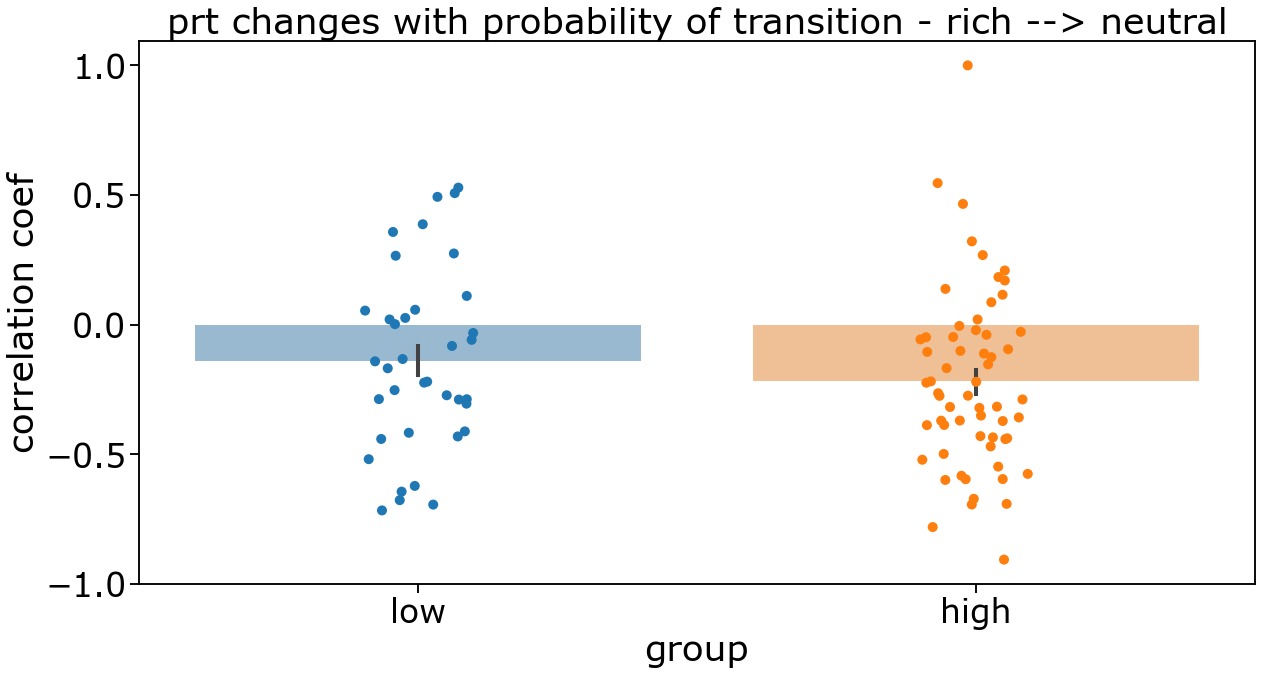

In [ ]:
g=sns.barplot(x='group',y='rho_2_trans_1',alpha=0.5,ci=68,data=avg)
sns.stripplot(x='group',y='rho_2_trans_1',s=10,data=avg)
g.set_ylabel('correlation coef')
g.set_title('prt changes with probability of transition - rich --> neutral')
print(stats.ttest_ind(avg.query("group=='high'").rho_2_trans_1,avg.query("group=='low'").rho_2_trans_1))
plt.savefig('plots/rho_2_1_v_alpha.png',bbox_inches = "tight",dpi=300)

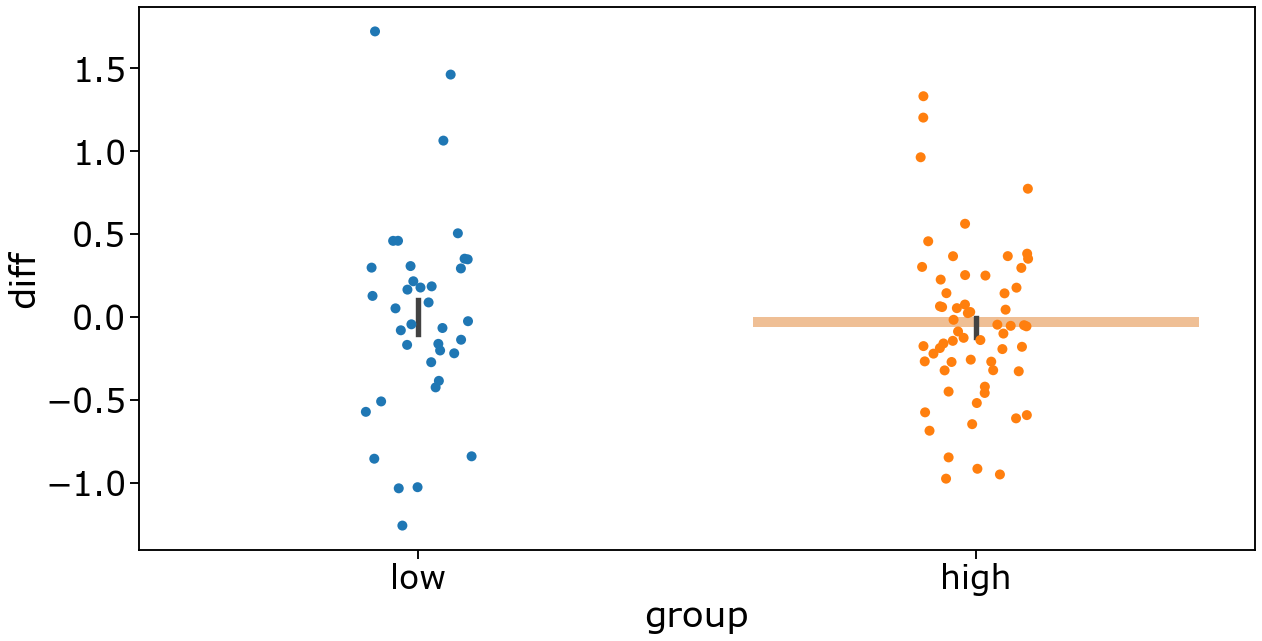

In [ ]:
avg = diff.groupby(by=['sub_num','alpha']).mean().reset_index()

avg['group'] =avg.apply (lambda row: label_group(row), axis=1)
g=sns.barplot(x='group',y='diff',alpha=0.5,ci=68,data=avg)
sns.stripplot(x='group',y='diff',s=10,data=avg)
#print(stats.ttest_ind(avg.query("group=='high'").diff,avg.query("group=='low'").diff))
plt.savefig('plots/diff_v_alpha_large.png',bbox_inches = "tight",dpi=300)

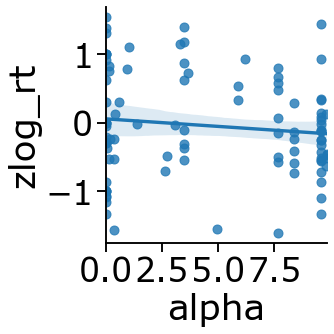

In [ ]:
avg=rt_df.groupby(by=['sub_num',"stay?","alpha","num_in_gal"]).mean().reset_index()
avg['stay']=avg['stay?']
leave_rt = avg.query("stay==0 & num_in_gal==6")

sns.lmplot(x='alpha',y='zlog_rt',data=leave_rt)

In [ ]:
def label_group (row):
    if row['alpha'] < 1:
        return 'low'
    else:
        return 'high'
leave_rt['group'] =leave_rt.apply (lambda row: label_group(row), axis=1)

NameError: name 'leave_rt' is not defined

Ttest_indResult(statistic=-0.06139467511006299, pvalue=0.9511725311105796)


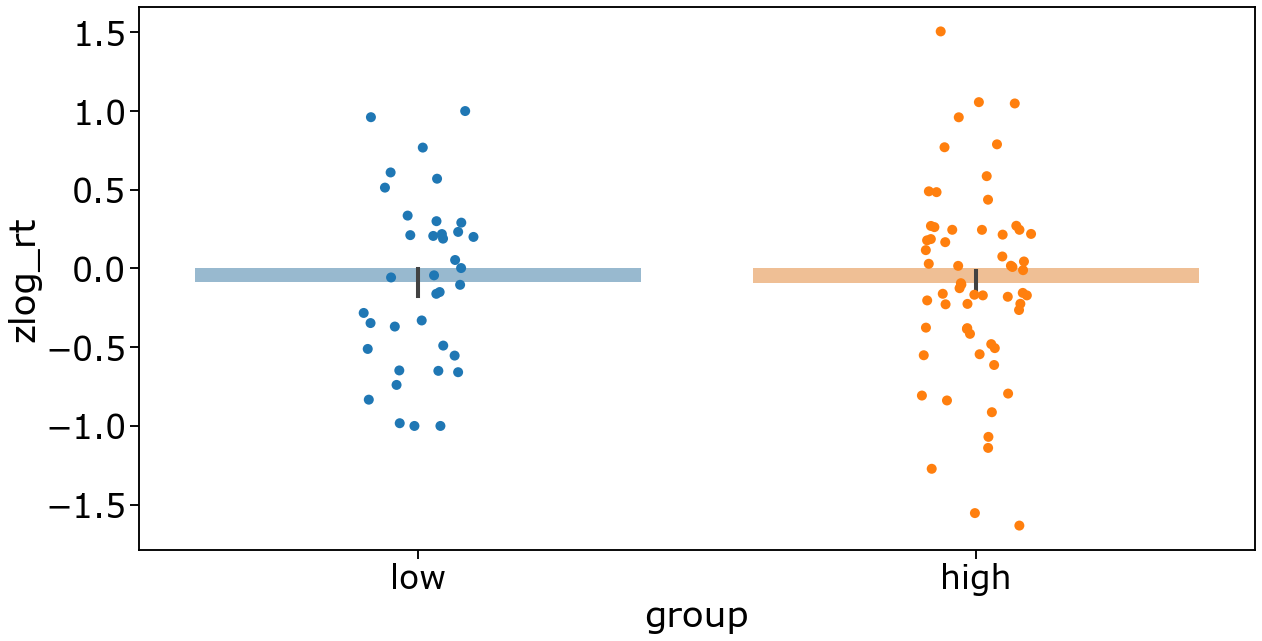

In [ ]:
sns.barplot(x='group',y='zlog_rt',ci=68,alpha=0.5,data=leave_rt)
sns.stripplot(x='group',y='zlog_rt',s=10,data=leave_rt)

print(stats.ttest_ind(leave_rt.query("group=='high'").zlog_rt,leave_rt.query("group=='low'").zlog_rt))
plt.savefig('plots/zlog_rt_v_alpha.png',bbox_inches = "tight",dpi=300)

# Demograpics 

/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


           n         r          CI95%       r2    adj_r2     p-val   BF10  \
pearson  116 -0.027751  [-0.21, 0.16]  0.00077 -0.016915  0.767455  0.121   

            power  
pearson  0.059966  


/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


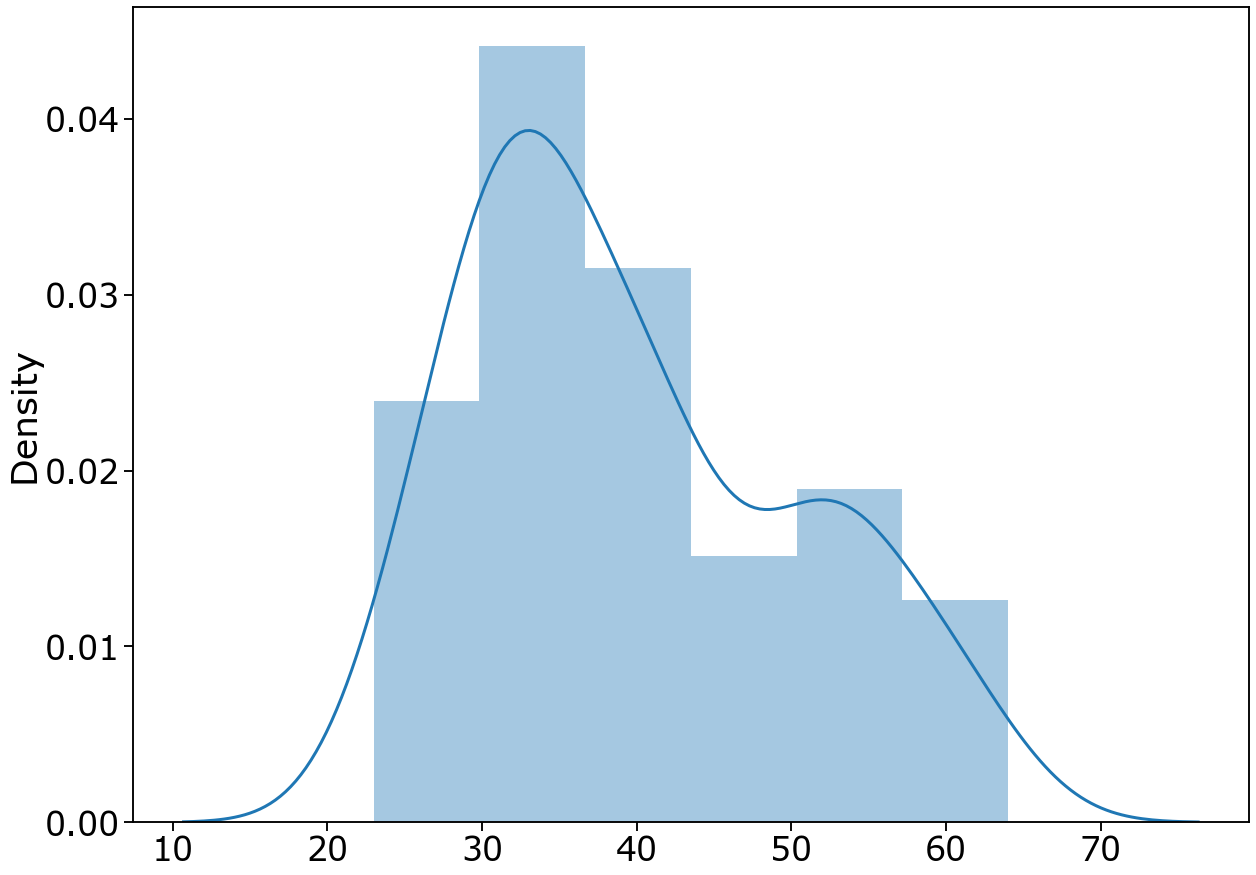

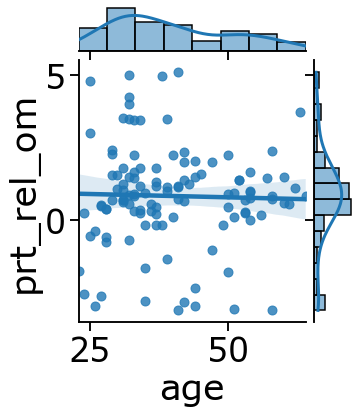

In [ ]:
sns.distplot(all_data.groupby("sub_num").age.mean().tolist())
if savefig:
    plt.savefig("plots/age_dsistribution.png")


print(pg.corr(all_data.groupby("sub_num").age.mean(),all_data.groupby("sub_num").prt_rel_om.mean()))
sns.jointplot(all_data.groupby("sub_num").age.mean(),all_data.groupby("sub_num").prt_rel_om.mean(),kind="reg")
if savefig:
    plt.savefig("plots/age_dsistribution_corr_prt_rel_mvt.png")


In [ ]:
np.std(all_data.groupby("sub_num").age.mean())

10.561087236394952

In [ ]:
stats.tstd(all_data.groupby(by='sub_num').age.mean())


13.505079766042831

/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


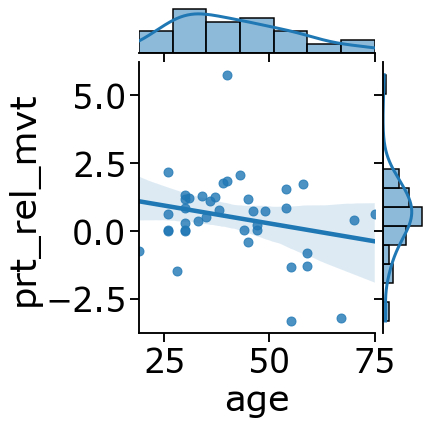

In [ ]:
sns.jointplot(all_data.groupby("sub_num").age.mean(),all_data.groupby("sub_num").prt_rel_mvt.mean(),kind="reg")


In [ ]:
x=all_data.groupby("sub_num")['gender'].agg(pd.Series.mode).to_frame().reset_index()
x['gender'].value_counts()

male}      111
female}     65
Name: gender, dtype: int64

In [ ]:
len(np.unique(all_data.sub_num))

176

TypeError: unsupported operand type(s) for +: 'builtin_function_or_method' and 'str'

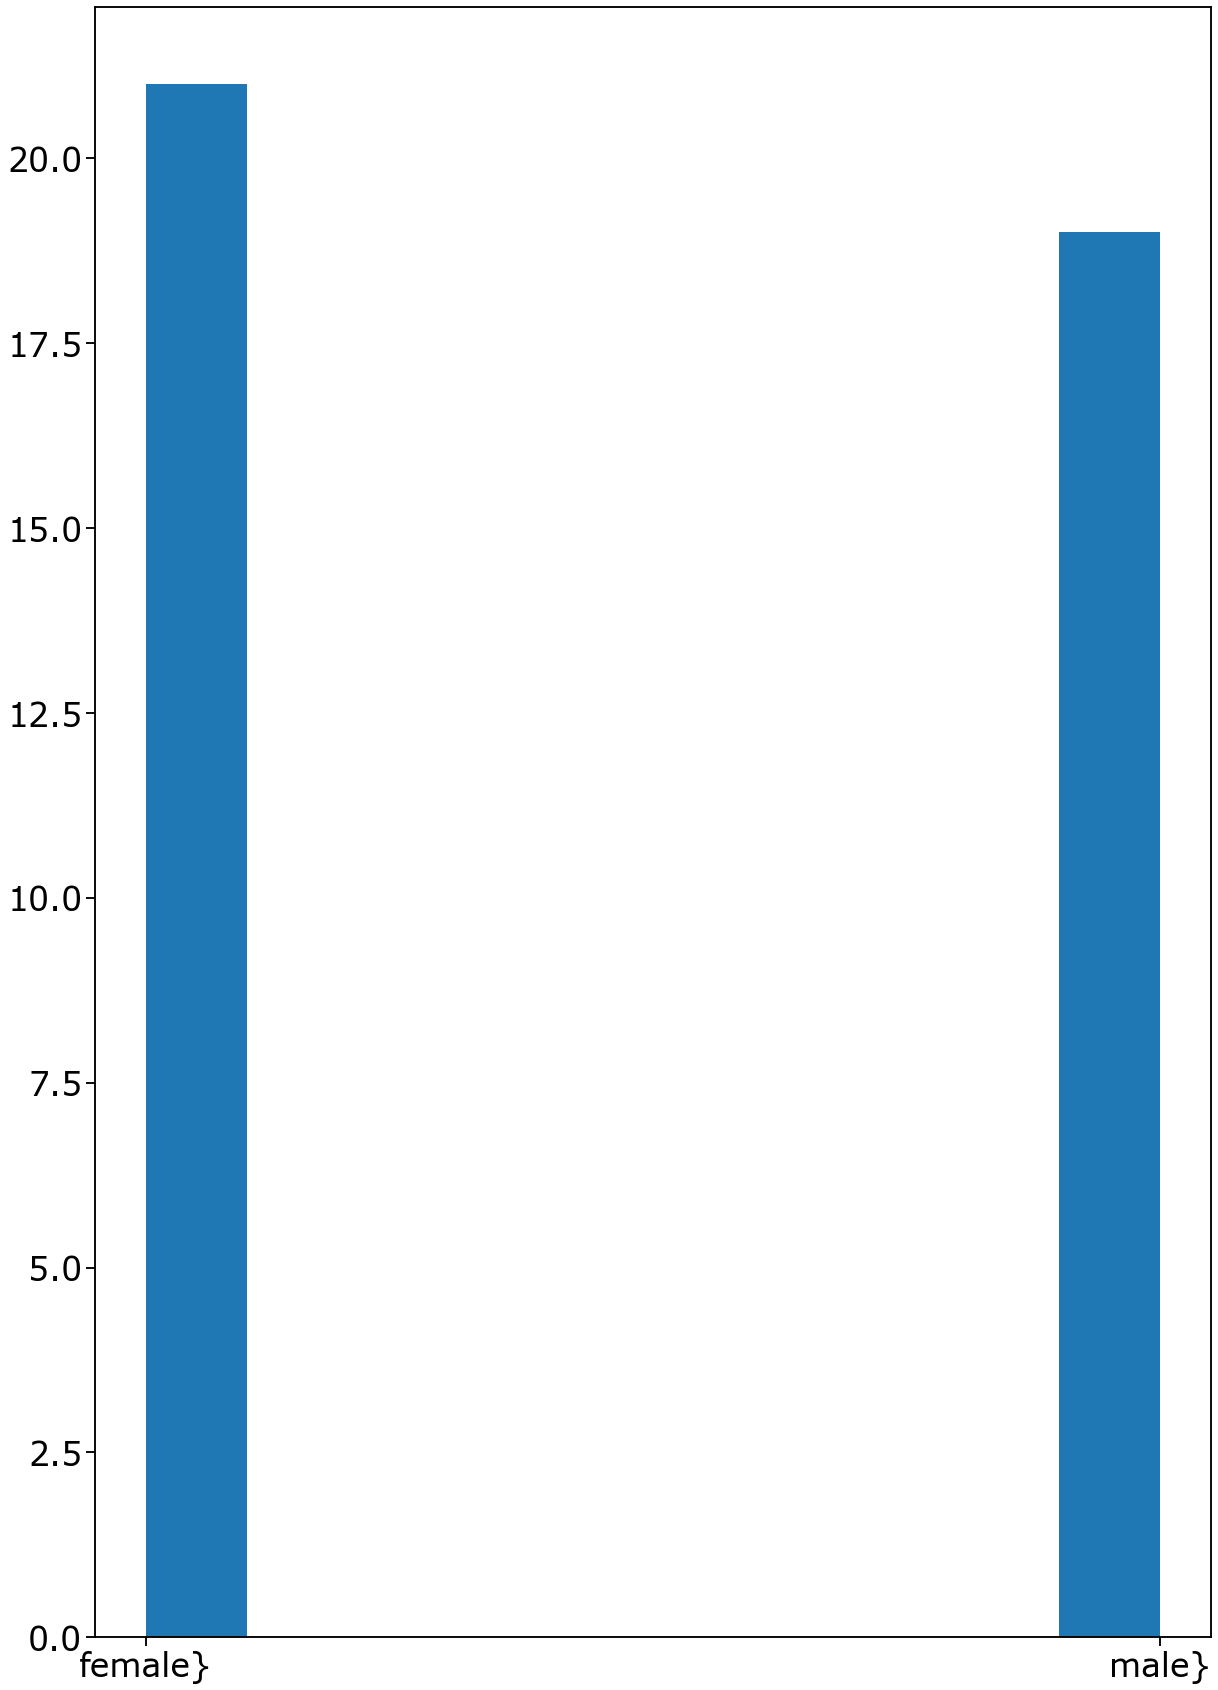

In [ ]:
plt.hist(gender_df['gender'].tolist())
if savefig:
    plt.savefig(round+"/hist_gender.png")


# QUIC

In [ ]:
##### FOR ANALYZING QUIC DATA 
def indiv_quic_data(filename,sub_num):
    raw_data = pd.read_csv(filename)
    sub_quic_data = pd.DataFrame(columns=["sub_num",'q_num','answer'])
    prior_12=raw_data.loc[raw_data["trial_type"]=="quic_prior_12"]

    for question in range(6,15):
        temp = re.split(':|{|}',str(prior_12.iloc[:,question].values[0]))
        temp = list(filter(lambda a: a != '', temp))
        q_num = int(temp[0][1])
        temp_df = pd.DataFrame({'sub_num': sub_num,'q_num':q_num,'answer':temp[1]}, index=[0])
        sub_quic_data = sub_quic_data.append(temp_df)
    
    prior_18=raw_data.loc[raw_data["trial_type"]=="quic_prior_18"]
    for question in range(6,35):
        temp = re.split(':|{|}',prior_18.iloc[:,question].values[0])
        temp = list(filter(lambda a: a != '', temp))
        temp[1] = temp[1].split('}')[0]
        q_num = int(temp[0][1:]) + 9

        temp_df = pd.DataFrame({'sub_num': sub_num,'q_num':q_num,'answer':temp[1]}, index=[0])
        sub_quic_data = sub_quic_data.append(temp_df)
    sub_quic_data = sub_quic_data.replace({'Yes':1,'No':0,'Prefer not to answer':np.nan})
    return sub_quic_data

def make_all_quic_data(filenames):
    num_subs = len(filenames)
    quic_data = pd.DataFrame(columns=["sub_num",'q_num','answer','total_score'])
    for f in range(num_subs):
        try:
            sub_data = indiv_quic_data(filenames[f],f)
            summary_score = quic_summary(sub_data)
            sub_data['total_score'] = summary_score
            quic_data = quic_data.append(sub_data)
        except:
            continue
    quic_data = quic_data.astype({'sub_num':'int','q_num':'int','total_score': 'int'})

    return quic_data

def quic_summary(dataframe):
    reverse_items = [0,1,2,3,4,5,6,8,9,10,13,15,25,32]
    # reverse code the dataframes 
    dataframe = reverse_code_items(dataframe,reverse_items)
    # now calc a summary score 
    return dataframe['answer'].sum()
    

def reverse_code_items(dataframe,reverse_items):
    for item in reverse_items:
        dataframe.iloc[item]['answer'] = 1 - dataframe.iloc[item]['answer']
    return dataframe

In [ ]:
all_quic_data = make_all_quic_data(all_filenames)
quic_sub_sort = all_quic_data.sort_values(by=['total_score'],ascending=False)['sub_num'].unique()
# high to low 
quic_sub_sort

#all_quic_data = all_quic_data.dropna()

<ipython-input-14-4b862fa89240>:51: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe.iloc[item]['answer'] = 1 - dataframe.iloc[item]['answer']


array([128,  91, 173,  80,  21, 132,  37,  52, 191, 115, 179,  17,  42,
        48,  35, 180, 141, 114, 150,  16, 181,  64,  19,   2,  77,  27,
       145,  12,  34,  93, 165, 144, 107, 133, 183,  66, 129, 172,  68,
        72,  56,  11,  51, 156, 164,   6, 120,  70, 167, 112,   3, 166,
        53,  54, 106,  46, 116,  84, 194,   5, 160,  58, 184, 171, 170,
       196, 127, 125,  50,  99, 189,  88,  38, 177, 113,  69, 161, 159,
        32, 126,  55,  20, 121, 176, 178, 101, 122,  45,  94,  28, 182,
       153, 117, 119,  36,  29,  63, 197, 130, 168, 149, 147,  67,  60,
       188, 192, 135,  97,  57,  24,   7,  82, 137,  81,   0,  22, 108,
        87, 157,  78, 198, 158, 162, 152, 111, 134,  18,  15, 110,  33,
        10,   1, 102, 190, 187,  47,   9,  31,  25, 151, 195, 136,  89,
       175,  76,  65, 140,  23,  44,  71,  30,  40, 104, 163, 143, 123,
       155,  92, 146, 138, 169, 142,  85, 124,  41,  96,  59, 148,  13,
         8,  75, 131,  39, 105, 100, 154, 109])

In [ ]:
quic=all_quic_data.loc[:,['sub_num','total_score']]
quic=quic.groupby(by='sub_num').mean().reset_index()

In [ ]:
x=avgd_data.merge(all_quic_data.loc[:,['sub_num','total_score']].drop_duplicates())
x.loc[:,['sub_num','condition','prt_rel_mvt','total_score']].to_csv('to_correlate_with_params.csv')

NameError: name 'avgd_data' is not defined

In [ ]:
quic.groupby(by='sub_num').mean().reset_index().to_csv("to_correlate.csv")

In [ ]:
avg = all_data.groupby('sub_num').mean().reset_index()
subs = avg["sub_num"].tolist()
avg = avg.set_index('sub_num')

avg = all_data.groupby(['sub_num','galaxy']).mean().reset_index()
avg_rich=avg.query("galaxy==2")
avg_rich = avg_rich.set_index('sub_num')

avg_quic=all_quic_data.groupby('sub_num').mean().reset_index(0)
avg_quic = avg_quic.set_index('sub_num')
quic_df = pd.DataFrame({'sub_num':subs,'avg_prt':list(avg['prt'].loc[subs]),'avg_rich_prt':list(avg_rich['prt'].loc[subs]),'total_reward':list(avg['total_reward'].loc[subs]),'quic_score':list(avg_quic['total_score'].loc[subs])})
quic_df = quic_df[~quic_df['sub_num'].isin(subs_to_drop)]


/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/seaborn/distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:ylabel='Density'>

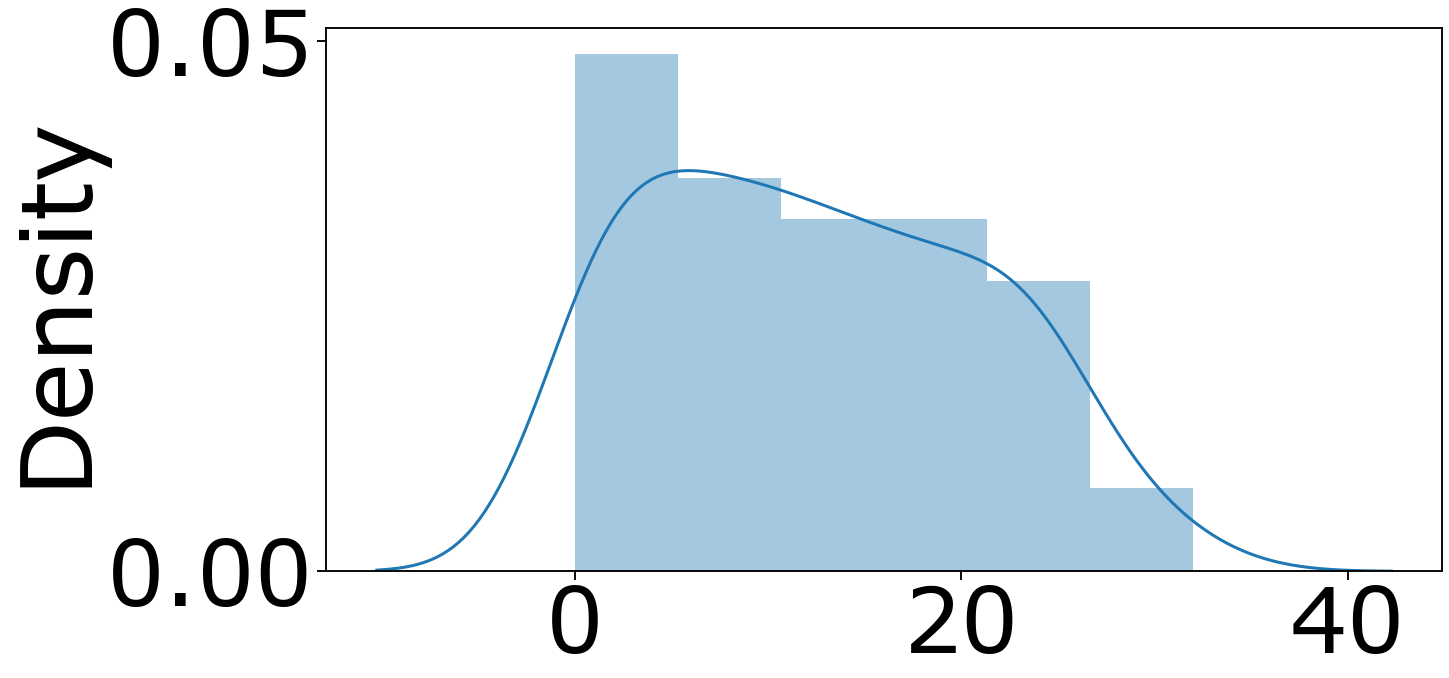

In [ ]:
sns.distplot(avg_quic['total_score'].tolist())

          n         r          CI95%        r2   adj_r2     p-val   BF10  \
pearson  36 -0.069046  [-0.39, 0.27]  0.004767 -0.05555  0.689057  0.224   

           power  
pearson  0.06827  


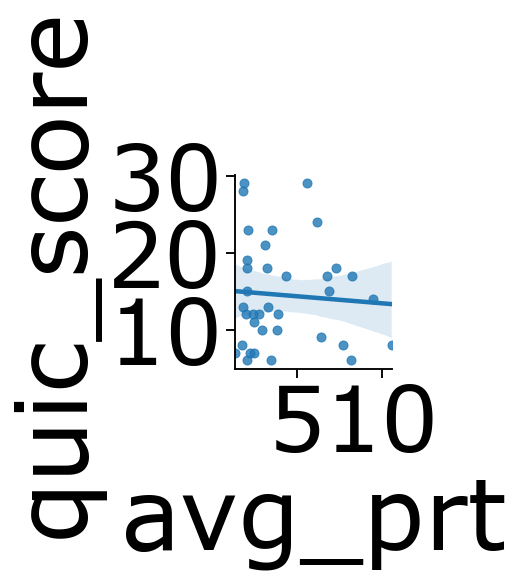

In [ ]:
x=quic_df.query("quic_score>5")
import pingouin as pg
print(pg.corr(x['quic_score'],x['avg_prt']))

sns.lmplot(x='avg_prt',y='quic_score',data=quic_df.query("quic_score>5"))

# Difference in PRTs in rich galaxies 

In [ ]:
print(pg.corr(quic_df['diff_rich'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_rich.png")

NameError: name 'quic_df' is not defined

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  51 -0.064401  [-0.33, 0.21]  0.004147 -0.037346  0.653446  0.073242
           n         r          CI95%       r2    adj_r2     p-val     power
spearman  54  0.119333  [-0.15, 0.38]  0.01424 -0.024417  0.390078  0.138424
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  49  0.080022  [-0.21, 0.35]  0.006404 -0.036796  0.584673  0.084802
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53 -0.128271  [-0.39, 0.15]  0.016454 -0.022888  0.360008  0.150731


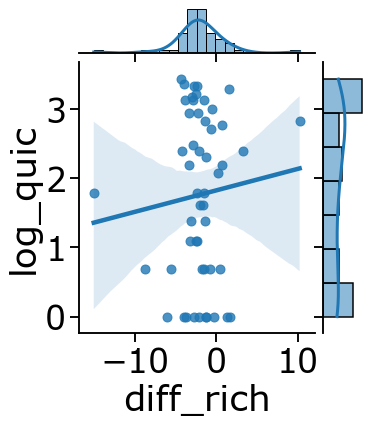

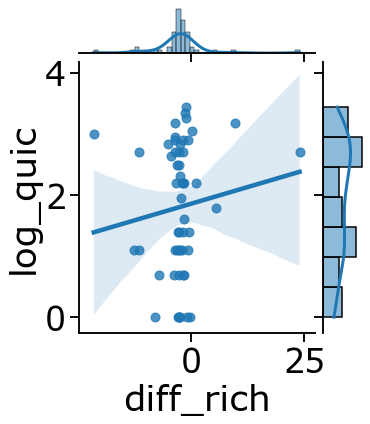

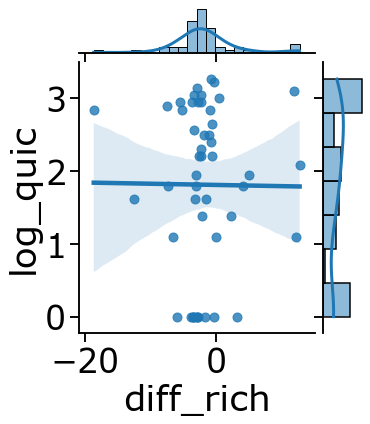

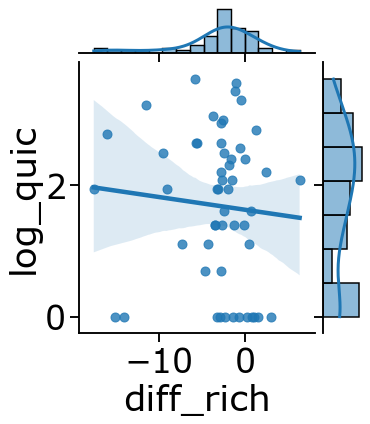

In [ ]:
savefig=0
print(pg.corr(quic_1['diff_rich'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_rich_cond_1.png")

print(pg.corr(quic_2['diff_rich'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_rich_cond_2.png")

print(pg.corr(quic_5['diff_rich'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_rich_cond_5.png")
    
print(pg.corr(quic_6['diff_rich'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_rich_cond_6.png")

# Difference in poor galaxies 

            n         r          CI95%        r2    adj_r2     p-val    power
spearman  129 -0.050319  [-0.22, 0.12]  0.002532 -0.013301  0.571184  0.08746


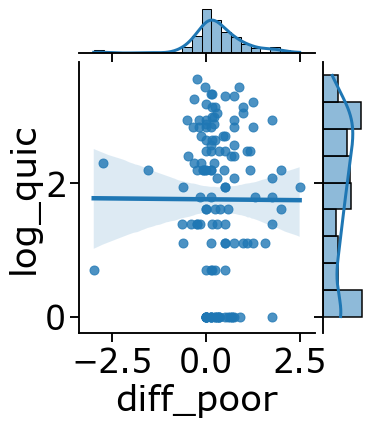

In [ ]:
print(pg.corr(quic_df['diff_poor'],quic_df['log_quic'],method='spearman'))

sns.jointplot(x='diff_poor',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_poor.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  33  0.010425  [-0.33, 0.35]  0.000109 -0.066551  0.954086  0.049914
           n         r           CI95%        r2    adj_r2     p-val    power
spearman  33 -0.398587  [-0.65, -0.06]  0.158871  0.102796  0.021587  0.64853
           n         r          CI95%        r2    adj_r2     p-val    power
spearman  32  0.019083  [-0.33, 0.37]  0.000364 -0.068576  0.917434  0.05076
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  31  0.139504  [-0.23, 0.47]  0.019461 -0.050577  0.454173  0.116618


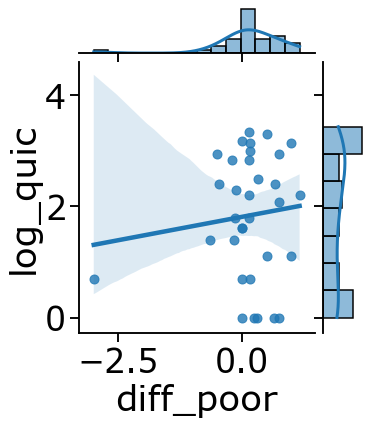

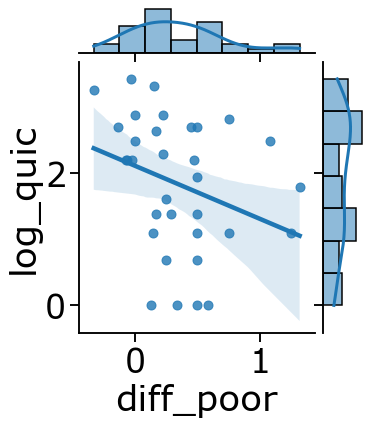

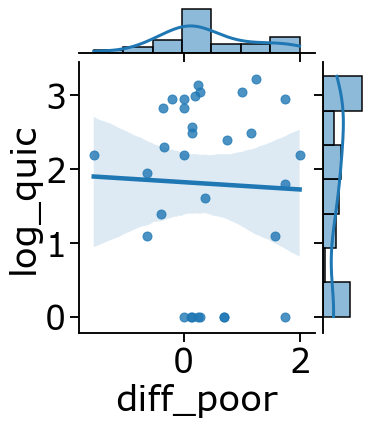

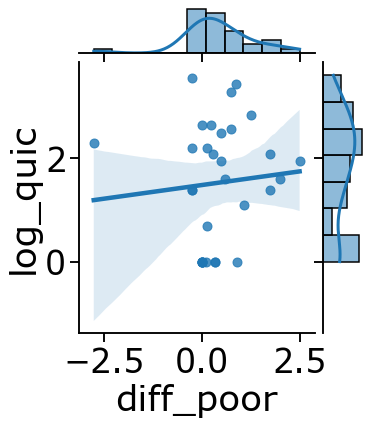

In [ ]:
print(pg.corr(quic_1['diff_poor'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_poor_cond_1.png")

print(pg.corr(quic_2['diff_poor'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_poor_cond_2.png")


print(pg.corr(quic_5['diff_poor'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_poor_cond_5.png")
    
print(pg.corr(quic_6['diff_poor'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_poor_cond_6.png")

# Difference in neutral galaxies

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  59  0.101087  [-0.16, 0.35]  0.010219 -0.025131  0.446177  0.118903


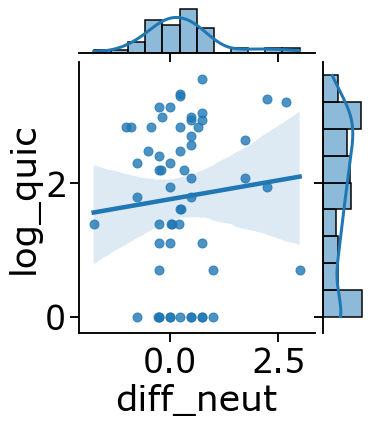

In [ ]:
print(pg.corr(quic_df['diff_neut'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut',y='log_quic',kind="reg",data=quic_df)

if savefig:
    plt.savefig(round +"/corr_diff_neut.png")

           n         r          CI95%        r2    adj_r2    p-val     power
spearman  16 -0.283106  [-0.68, 0.25]  0.080149 -0.061366  0.28801  0.189435
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  15  0.114027  [-0.42, 0.59]  0.013002 -0.151497  0.685745  0.068396
           n         r          CI95%        r2    adj_r2    p-val     power
spearman  11  0.240275  [-0.42, 0.73]  0.057732 -0.177835  0.47667  0.110518
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  17  0.428669  [-0.07, 0.75]  0.183757  0.067151  0.086006  0.419865


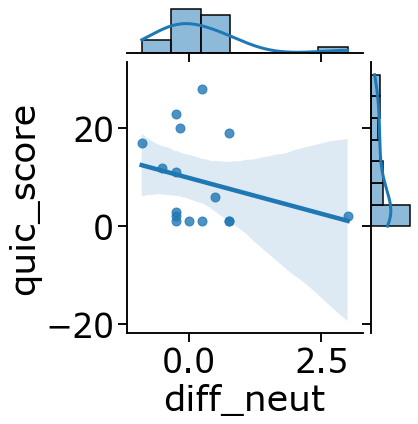

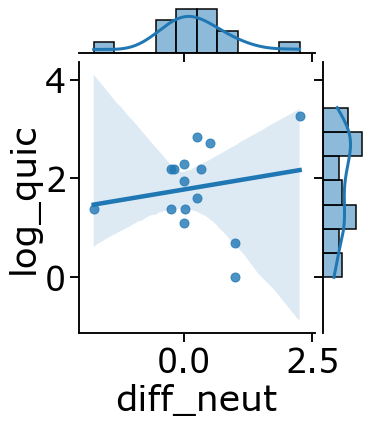

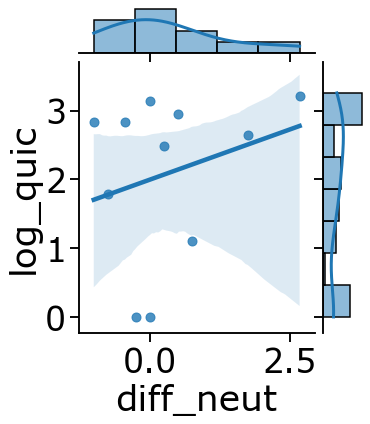

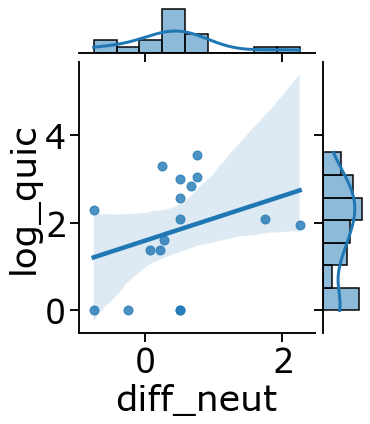

In [ ]:
print(pg.corr(quic_1['diff_neut'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut',y='quic_score',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_neut_cond_1.png")

print(pg.corr(quic_2['diff_neut'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_neut_cond_2.png")


print(pg.corr(quic_5['diff_neut'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_neut_cond_5.png")

print(pg.corr(quic_6['diff_neut'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_neut_cond_6.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  69  0.061171  [-0.18, 0.29]  0.003742 -0.026448  0.617564  0.078934


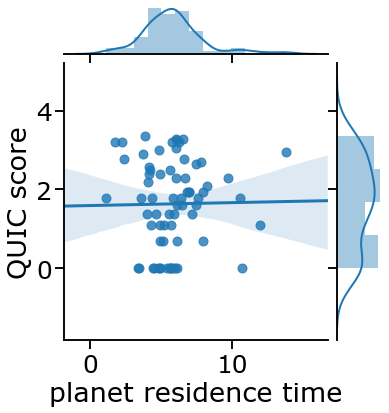

In [ ]:
print(pg.corr(quic_df['avg_prt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='avg_prt',y='log_quic',kind="reg",data=quic_df)
plt.ylabel("QUIC score")
plt.xlabel('planet residence time')
if savefig:
    plt.savefig(round +"/corr_prt_quic_all.png")

           n         r          CI95%        r2   adj_r2     p-val    power
spearman  55 -0.004569  [-0.27, 0.26]  0.000021 -0.03844  0.973591  0.04984
           n         r         CI95%        r2    adj_r2     p-val     power
spearman  61  0.167171  [-0.09, 0.4]  0.027946 -0.005573  0.197842  0.253148
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  56 -0.060309  [-0.32, 0.21]  0.003637 -0.033961  0.658825  0.072472
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  61 -0.099694  [-0.34, 0.16]  0.009939 -0.024201  0.444607  0.119388


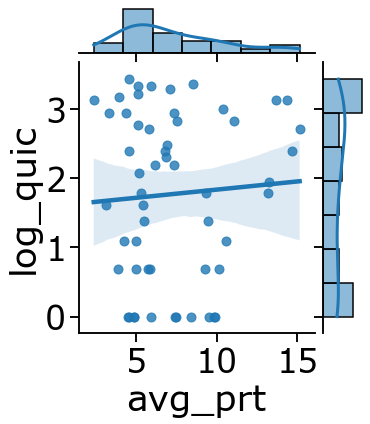

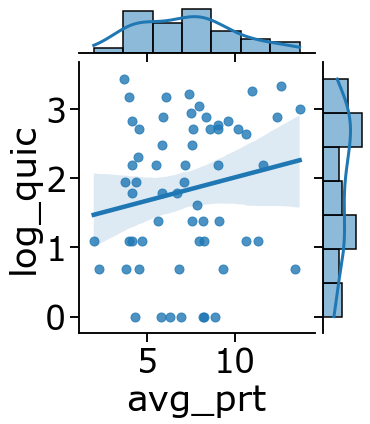

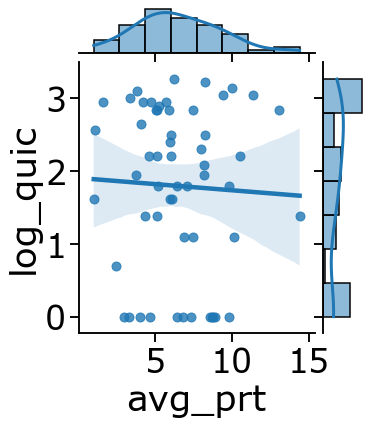

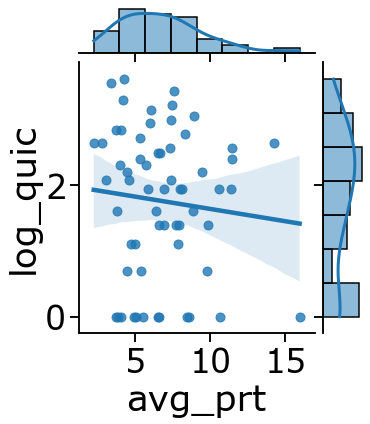

In [ ]:
print(pg.corr(quic_1['avg_prt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='avg_prt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig(round +"/corr_avg_prt_cond_1.png")

print(pg.corr(quic_2['avg_prt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='avg_prt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig(round +"/corr_avg_prt_cond_2.png")


print(pg.corr(quic_5['avg_prt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='avg_prt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig(round +"/corr_avg-prt_cond_5.png")
    
    
print(pg.corr(quic_6['avg_prt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='avg_prt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig(round +"/corr_avg-prt_cond_6.png")

            n         r          CI95%        r2    adj_r2     p-val     power
spearman  207  0.017694  [-0.12, 0.15]  0.000313 -0.009488  0.800232  0.057301


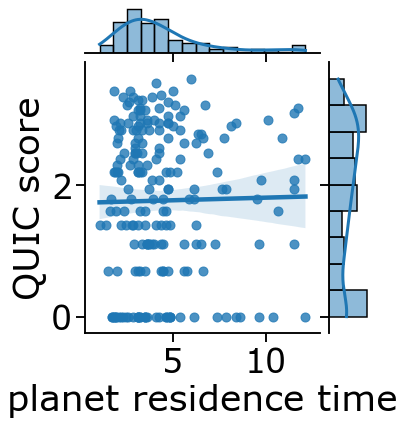

In [ ]:
print(pg.corr(quic_df['neutral_prt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='neutral_prt',y='log_quic',kind="reg",data=quic_df)
plt.ylabel("QUIC score")
plt.xlabel('planet residence time')
if savefig:
    plt.savefig(round +"/corr_neutral_prt_quic_all.png")

           n        r          CI95%        r2    adj_r2     p-val     power
spearman  51  0.00874  [-0.27, 0.28]  0.000076 -0.041587  0.951461  0.050119
           n         r         CI95%       r2    adj_r2     p-val     power
spearman  54 -0.069354  [-0.33, 0.2]  0.00481 -0.034217  0.618256  0.078795
           n         r          CI95%        r2    adj_r2    p-val     power
spearman  49  0.055739  [-0.23, 0.33]  0.003107 -0.040236  0.70365  0.066526
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53  0.121786  [-0.15, 0.38]  0.014832 -0.024575  0.385005  0.140408


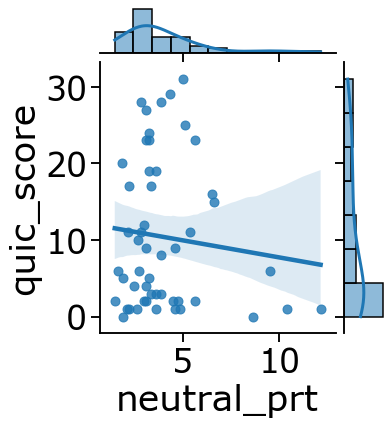

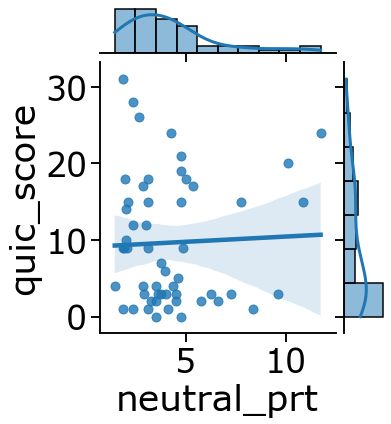

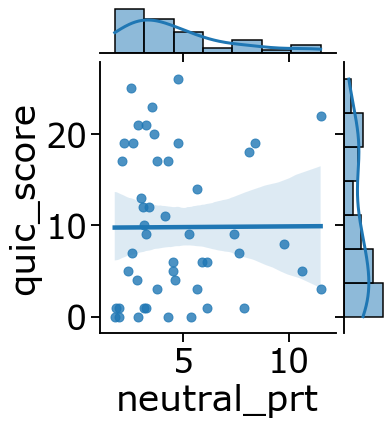

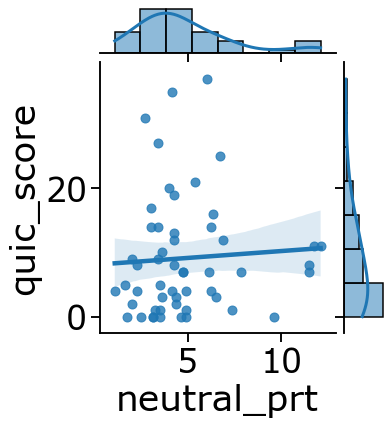

In [ ]:
print(pg.corr(quic_1['neutral_prt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='neutral_prt',y='quic_score',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_neutral_prt_cond_1.png")

print(pg.corr(quic_2['neutral_prt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='neutral_prt',y='quic_score',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_neutral_prt_cond_2.png")


print(pg.corr(quic_5['neutral_prt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='neutral_prt',y='quic_score',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_neutral_prt_cond_5.png")

print(pg.corr(quic_6['neutral_prt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='neutral_prt',y='quic_score',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_neutral_prt_cond_6.png")

            n         r          CI95%        r2    adj_r2     p-val     power
spearman  207  0.076033  [-0.06, 0.21]  0.005781 -0.003966  0.276206  0.193312


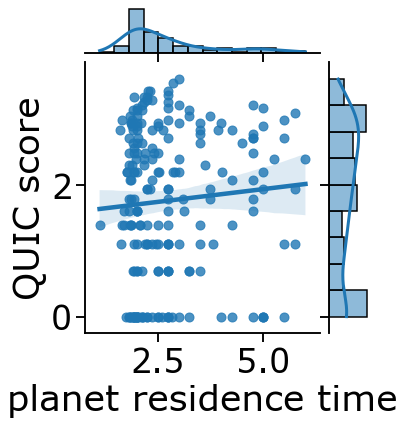

In [ ]:
print(pg.corr(quic_df['poor_prt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='poor_prt',y='log_quic',kind="reg",data=quic_df)
plt.ylabel("QUIC score")
plt.xlabel('planet residence time')
if savefig:
    plt.savefig("plots/corr_poor_prt_quic_all.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  51 -0.147165  [-0.41, 0.13]  0.021658 -0.019107  0.302757  0.178739
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  54  0.108973  [-0.16, 0.37]  0.011875 -0.026875  0.432814  0.123207
           n         r         CI95%        r2    adj_r2     p-val     power
spearman  49  0.023859  [-0.26, 0.3]  0.000569 -0.042884  0.870736  0.052736
           n         r         CI95%        r2    adj_r2     p-val     power
spearman  53  0.284239  [0.02, 0.51]  0.080792  0.044023  0.039141  0.549209


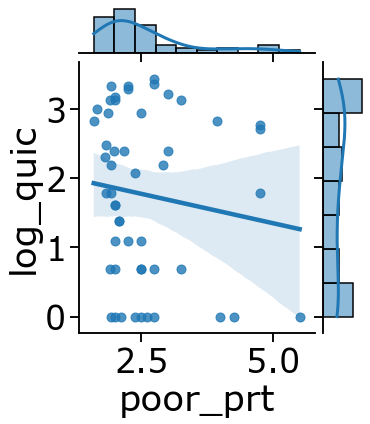

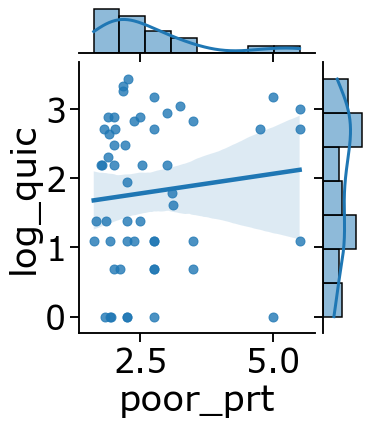

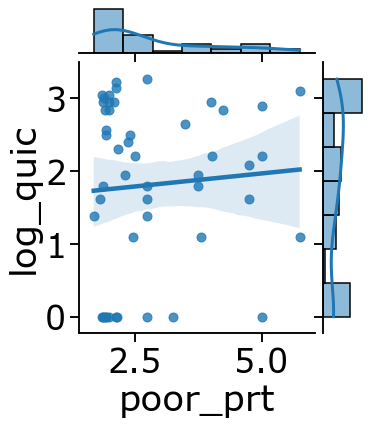

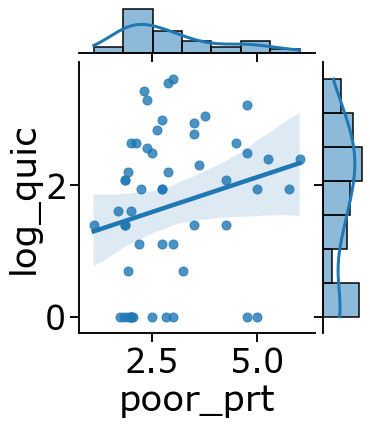

In [ ]:
print(pg.corr(quic_1['poor_prt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='poor_prt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig(round +"/corr_poor_prt_cond_1.png")

print(pg.corr(quic_2['poor_prt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='poor_prt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig(round +"/corr_poor_prt_cond_2.png")


print(pg.corr(quic_5['poor_prt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='poor_prt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig(round +"/corr_poor_prt_cond_5.png")
    
    
print(pg.corr(quic_6['poor_prt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='poor_prt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig(round +"/corr_poor_prt_cond_6.png")

# Correlations relative to MVT

In [ ]:
x1 = avgd_data_post.query('galaxy == 2 and preced_gal == 0').groupby('sub_num').prt_rel_mvt.mean()
x2 = avgd_data_post.query('galaxy == 2 and preced_gal == 1').groupby('sub_num').prt_rel_mvt.mean()
diff_rich = x1 - x2


x1 = avgd_data_post.query('galaxy == 0 and preced_gal == 1').groupby('sub_num').prt_rel_mvt.mean()
x2 = avgd_data_post.query('galaxy == 0 and preced_gal == 2').groupby('sub_num').prt_rel_mvt.mean()
diff_poor = x1-x2

x1 = avgd_data_post.query('galaxy == 1 and preced_gal == 2').groupby('sub_num').prt_rel_mvt.mean()
x2 = avgd_data_post.query('galaxy == 1 and preced_gal == 0').groupby('sub_num').prt_rel_mvt.mean()
diff_neut = x1-x2


quic_df['diff_rich_rel_mvt'] = diff_rich
quic_df['diff_poor_rel_mvt'] = diff_poor
quic_df['diff_neut_rel_mvt'] = diff_neut
quic_df["neutral_prt_rel_mvt"] = avgd_data_post.query("galaxy == 1").groupby("sub_num").prt_rel_mvt.mean()
quic_df["poor_prt_rel_mvt"] = avgd_data_post.query("galaxy == 0").groupby("sub_num").prt_rel_mvt.mean()

In [ ]:
quic_1 = quic_df.loc[quic_df['condition']==1]
quic_2 = quic_df.loc[quic_df['condition']==2]
quic_5 = quic_df.loc[quic_df['condition']==5]
quic_6 = quic_df.loc[quic_df['condition']==6]

# diff rich

            n         r          CI95%       r2    adj_r2    p-val     power
spearman  207 -0.075895  [-0.21, 0.06]  0.00576 -0.003987  0.27708  0.192778


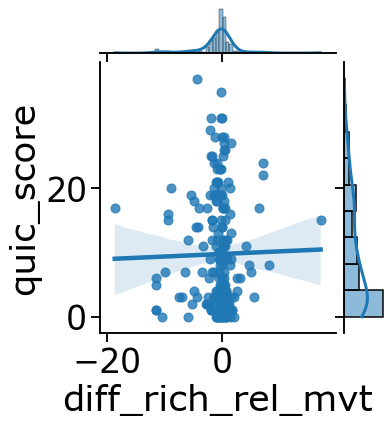

In [ ]:
print(pg.corr(quic_df['diff_rich_rel_mvt'],quic_df['quic_score'],method='spearman'))
sns.jointplot(x='diff_rich_rel_mvt',y='quic_score',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_rich_rel_prt.png")

           n        r         CI95%        r2    adj_r2     p-val     power
spearman  51 -0.08345  [-0.35, 0.2]  0.006964 -0.034413  0.560436  0.089625
           n         r          CI95%       r2    adj_r2    p-val     power
spearman  54  0.010936  [-0.26, 0.28]  0.00012 -0.039091  0.93744  0.050418
           n         r          CI95%        r2    adj_r2    p-val     power
spearman  49 -0.060236  [-0.34, 0.22]  0.003628 -0.039692  0.68097  0.069391
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53 -0.183408  [-0.43, 0.09]  0.033638 -0.005016  0.188653  0.262143


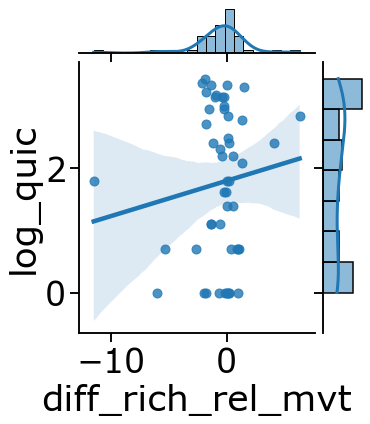

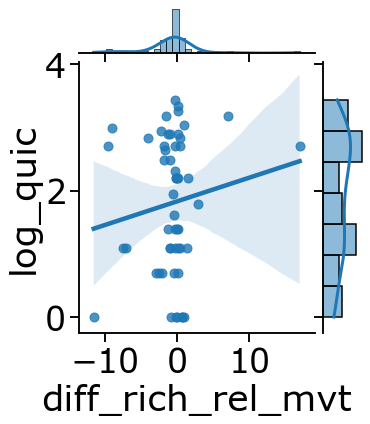

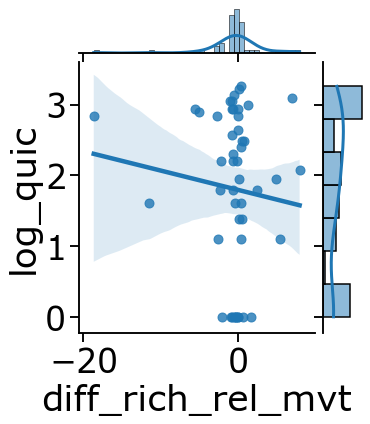

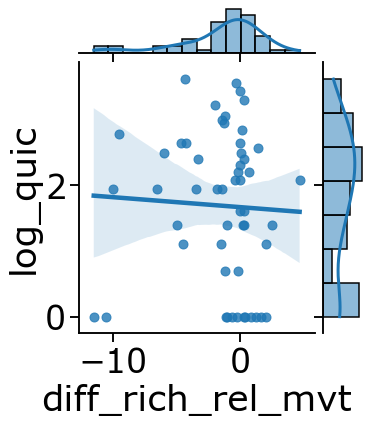

In [ ]:
print(pg.corr(quic_1['diff_rich_rel_mvt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_rel_mvt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_rich_rel_mvt_cond_1.png")

print(pg.corr(quic_2['diff_rich_rel_mvt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_rel_mvt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_rich_rel_mvt_cond_2.png")

print(pg.corr(quic_5['diff_rich_rel_mvt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_rel_mvt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_rich_rel_mvt_cond_5.png")
    
print(pg.corr(quic_6['diff_rich_rel_mvt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_rel_mvt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_rich_rel_mvt_cond_6.png")

# diff poor

            n         r          CI95%        r2    adj_r2     p-val     power
spearman  129 -0.087396  [-0.26, 0.09]  0.007638 -0.008114  0.324697  0.166709


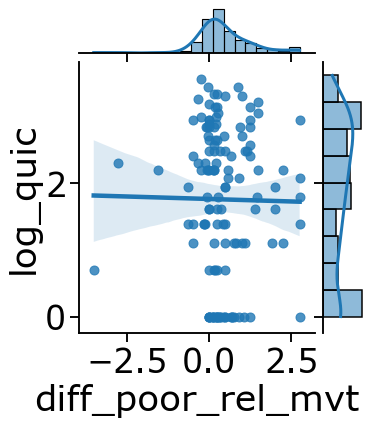

In [ ]:
print(pg.corr(quic_df['diff_poor_rel_mvt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor_rel_mvt',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_poor_poor_rel_mvt.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  33 -0.039547  [-0.38, 0.31]  0.001564 -0.064998  0.827037  0.055067
           n         r           CI95%        r2    adj_r2     p-val     power
spearman  33 -0.368169  [-0.63, -0.03]  0.135548  0.077918  0.035022  0.572773
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  32 -0.017437  [-0.36, 0.33]  0.000304 -0.068641  0.924537  0.050555
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  31  0.100519  [-0.26, 0.44]  0.010104 -0.060603  0.590556  0.083652


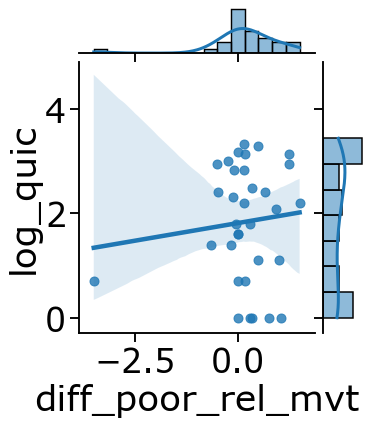

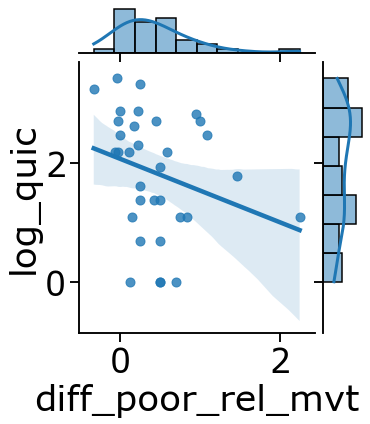

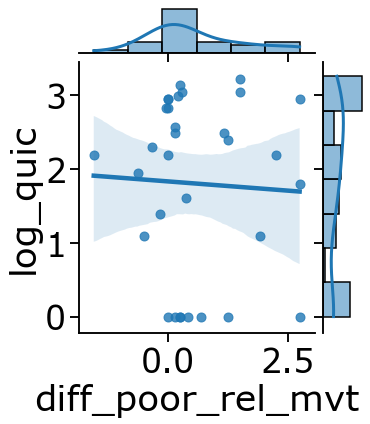

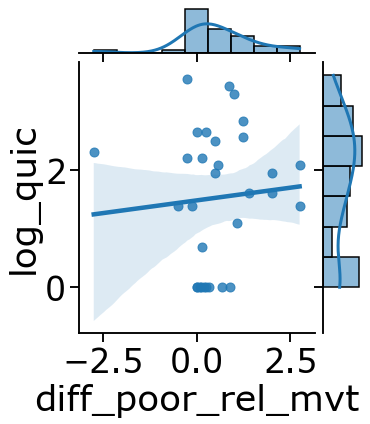

In [ ]:
print(pg.corr(quic_1['diff_poor_rel_mvt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor_rel_mvt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_poor_rel_mvt_cond_1.png")

print(pg.corr(quic_2['diff_poor_rel_mvt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor_rel_mvt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_poor_rel_mvt_cond_2.png")

print(pg.corr(quic_5['diff_poor_rel_mvt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor_rel_mvt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_poor_rel_mvt_cond_5.png")
    
    
print(pg.corr(quic_6['diff_poor_rel_mvt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_poor_rel_mvt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_poor_rel_mvt_cond_6.png")

# diff neutral

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  59  0.078147  [-0.18, 0.33]  0.006107 -0.029389  0.556321  0.090488


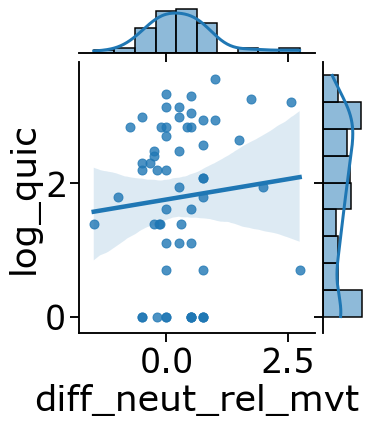

In [ ]:
print(pg.corr(quic_df['diff_neut_rel_mvt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_rel_mvt',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_neut_rel_mvt.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  16 -0.240305  [-0.66, 0.29]  0.057746 -0.087216  0.369993  0.147689
           n         r         CI95%        r2    adj_r2     p-val     power
spearman  15 -0.018083  [-0.53, 0.5]  0.000327 -0.166285  0.948998  0.049542
           n        r          CI95%        r2    adj_r2     p-val     power
spearman  11  0.30115  [-0.36, 0.76]  0.090691 -0.136636  0.368161  0.149224
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  17  0.262208  [-0.25, 0.66]  0.068753 -0.064282  0.309299  0.176991


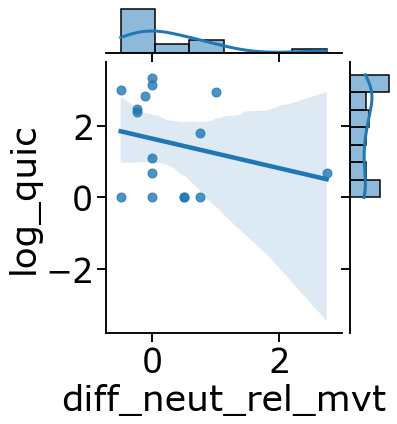

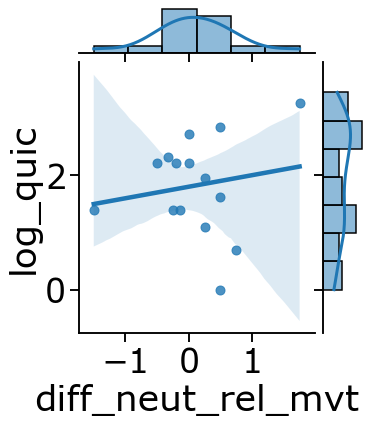

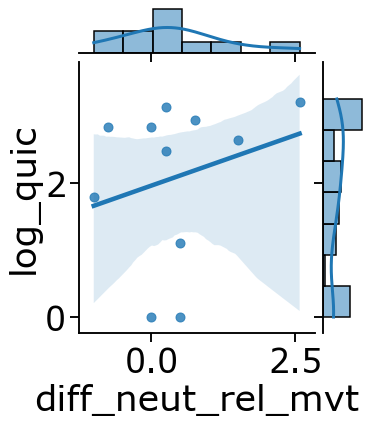

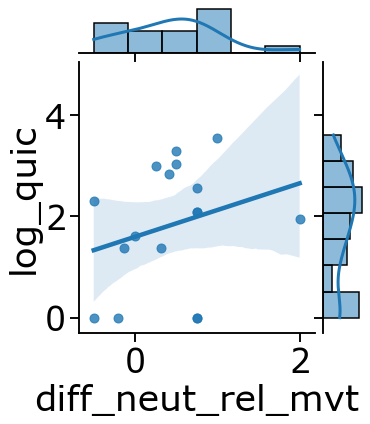

In [ ]:
print(pg.corr(quic_1['diff_neut_rel_mvt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_rel_mvt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_neut_rel_mvt_cond_1.png")

print(pg.corr(quic_2['diff_neut_rel_mvt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_rel_mvt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_neut_rel_mvt_cond_2.png")

print(pg.corr(quic_5['diff_neut_rel_mvt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_rel_mvt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_neut_rel_mvt_cond_5.png")
    
print(pg.corr(quic_6['diff_neut_rel_mvt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_rel_mvt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_neut_rel_mvt_cond_6.png")

# difference between average neutral and average poor

In [ ]:
quic_df["diff_neut_poor"] = avgd_data_post.query("galaxy == 1").groupby("sub_num").prt.mean() - avgd_data_post.query("galaxy == 0").groupby("sub_num").prt.mean()

In [ ]:
quic_1 = quic_df.loc[quic_df['condition']==1]
quic_2 = quic_df.loc[quic_df['condition']==2]
quic_5 = quic_df.loc[quic_df['condition']==5]
quic_6 = quic_df.loc[quic_df['condition']==6]

            n         r         CI95%        r2    adj_r2     p-val     power
spearman  207 -0.035004  [-0.17, 0.1]  0.001225 -0.008567  0.616566  0.079156


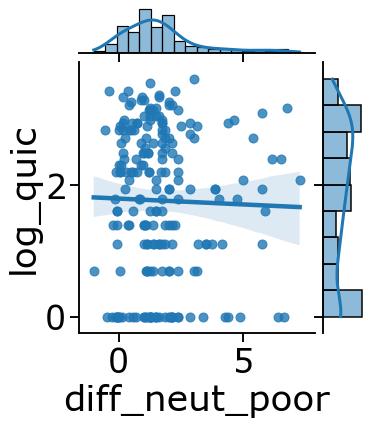

In [ ]:
print(pg.corr(quic_df['diff_neut_poor'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_ddiff_neut_poor.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  51 -0.007918  [-0.28, 0.27]  0.000063 -0.041601  0.956023  0.050042
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  54 -0.159797  [-0.41, 0.11]  0.025535 -0.012679  0.248408  0.212557
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  49  0.074443  [-0.21, 0.35]  0.005542 -0.037696  0.611206  0.079987
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53  0.007413  [-0.26, 0.28]  0.000055 -0.039943  0.957984  0.050023


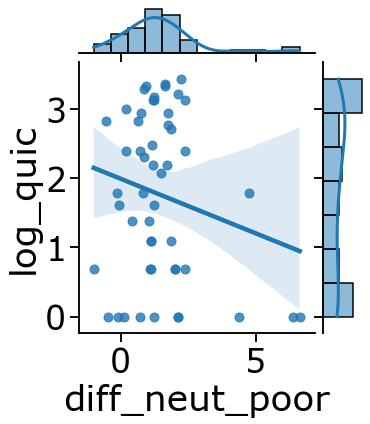

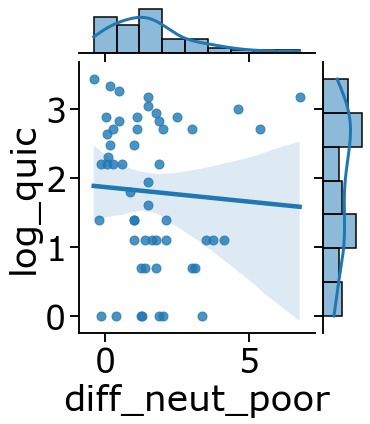

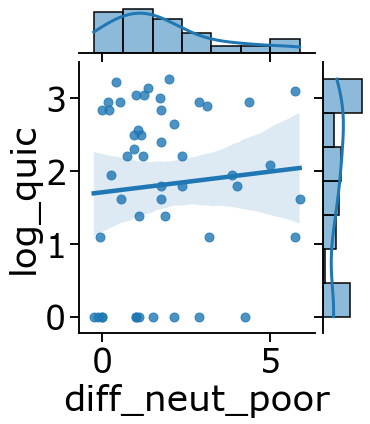

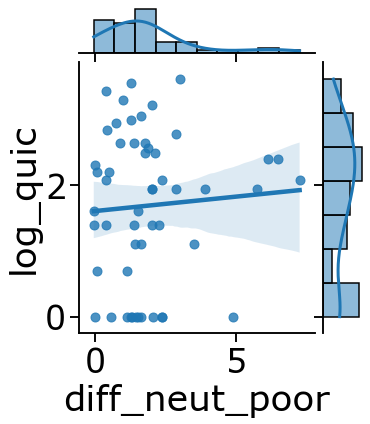

In [ ]:
print(pg.corr(quic_1['diff_neut_poor'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_neut_poor_cond_1.png")

print(pg.corr(quic_2['diff_neut_poor'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_neut_poor_cond_2.png")

print(pg.corr(quic_5['diff_neut_poor'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_neut_poor_cond_5.png")
    
    
print(pg.corr(quic_6['diff_neut_poor'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_neut_poor_cond_6.png")

# difference between average neutral and average rich

In [ ]:
quic_df["diff_rich_neut"] = avgd_data_post.query("galaxy == 2").groupby("sub_num").prt.mean() - avgd_data_post.query("galaxy == 1").groupby("sub_num").prt.mean()

In [ ]:
quic_1 = quic_df.loc[quic_df['condition']==1]
quic_2 = quic_df.loc[quic_df['condition']==2]
quic_5 = quic_df.loc[quic_df['condition']==5]
quic_6 = quic_df.loc[quic_df['condition']==6]

            n         r          CI95%        r2    adj_r2    p-val     power
spearman  207 -0.013378  [-0.15, 0.12]  0.000179 -0.009623  0.84828  0.054132


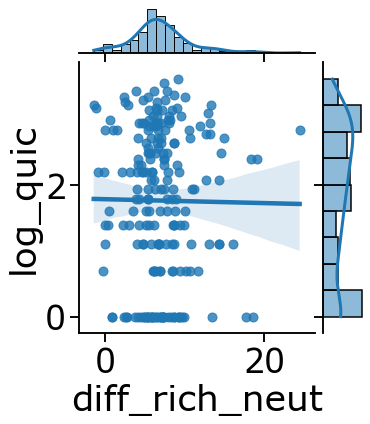

In [ ]:
print(pg.corr(quic_df['diff_rich_neut'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut.png")

           n         r         CI95%       r2    adj_r2     p-val     power
spearman  51 -0.076221  [-0.34, 0.2]  0.00581 -0.035615  0.594999  0.082876
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  54 -0.154598  [-0.41, 0.12]  0.023901 -0.014378  0.264334  0.201729
           n         r          CI95%        r2    adj_r2     p-val     power
spearman  49  0.198536  [-0.09, 0.45]  0.039416 -0.002348  0.171459  0.280016
           n        r          CI95%        r2    adj_r2     p-val     power
spearman  53  0.00954  [-0.26, 0.28]  0.000091 -0.039905  0.945944  0.050233


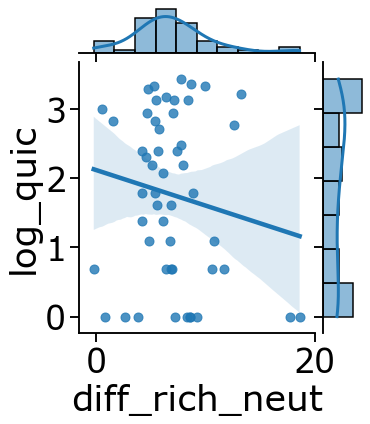

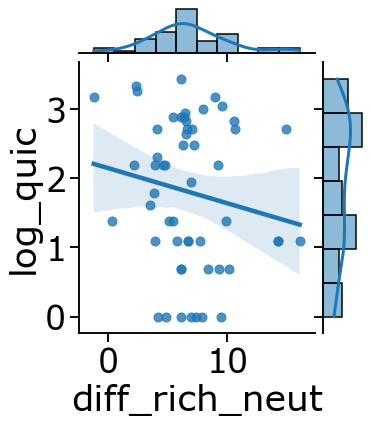

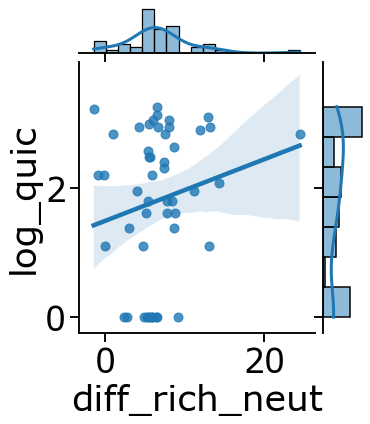

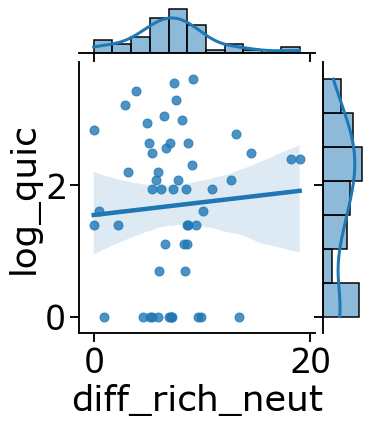

In [ ]:
print(pg.corr(quic_1['diff_rich_neut'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig("plots/corr_diff_rich_neut_cond_1.png")

print(pg.corr(quic_2['diff_rich_neut'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig("plots/corr_diff_rich_neut_cond_2.png")

print(pg.corr(quic_5['diff_rich_neut'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig("plots/corr_diff_rich_neut_cond_5.png")
    
print(pg.corr(quic_6['diff_rich_neut'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig("plots/corr_diff_rich_neut_cond_6.png")

# difference between average neutral and average poor relative to to mvt

In [ ]:
quic_df["diff_neut_poor_rel_mvt"] = avgd_data_post.query("galaxy == 1").groupby("sub_num").prt_rel_mvt.mean() - avgd_data_post.query("galaxy == 0").groupby("sub_num").prt_rel_mvt.mean()

quic_1 = quic_df.loc[quic_df['condition']==1]
quic_2 = quic_df.loc[quic_df['condition']==2]
quic_5 = quic_df.loc[quic_df['condition']==5]
quic_6 = quic_df.loc[quic_df['condition']==6]

            n         r         CI95%        r2    adj_r2   p-val    power
spearman  207 -0.039276  [-0.17, 0.1]  0.001543 -0.008246  0.5742  0.08687


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


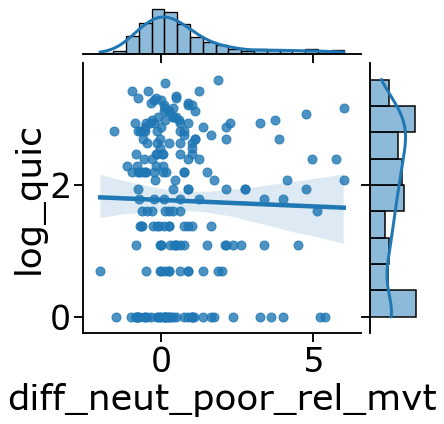

In [ ]:
print(pg.corr(quic_df['diff_neut_poor_rel_mvt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor_rel_mvt',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_ddiff_neut_poor_rel_mvt.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  51 -0.004528  [-0.28, 0.27]  0.000021 -0.041645  0.974844  0.049806


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2    adj_r2     p-val     power
spearman  54 -0.178056  [-0.43, 0.09]  0.031704 -0.006268  0.197694  0.253521


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2    adj_r2     p-val     power
spearman  49  0.066338  [-0.22, 0.34]  0.004401 -0.038886  0.650639  0.073652


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53 -0.007192  [-0.28, 0.26]  0.000052 -0.039946  0.959239  0.050004


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


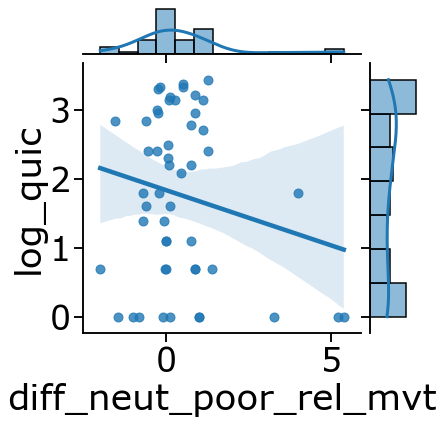

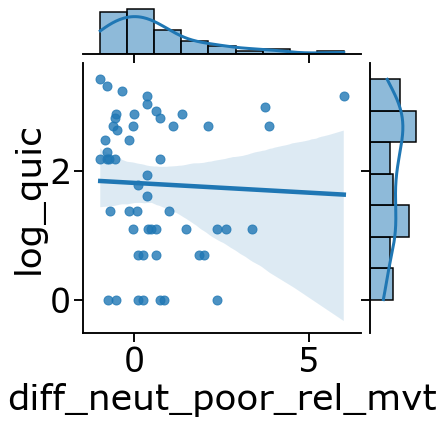

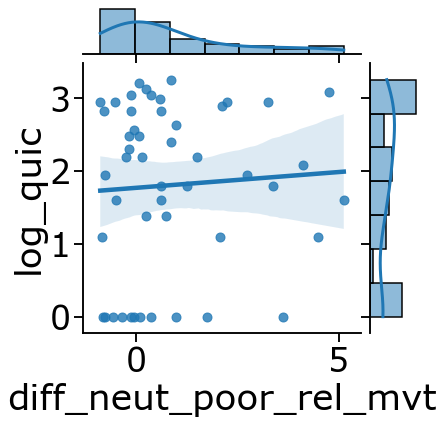

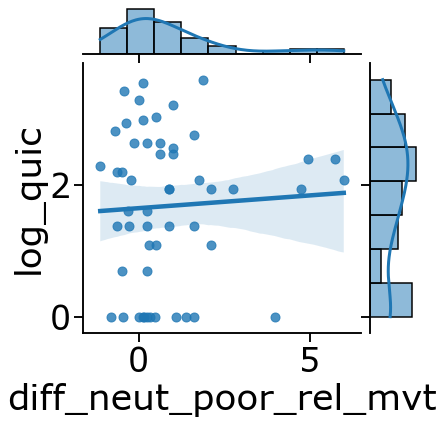

In [ ]:
print(pg.corr(quic_1['diff_neut_poor_rel_mvt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor_rel_mvt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig(round +"/corr_diff_neut_poor_rel_mvt_cond_1.png")

print(pg.corr(quic_2['diff_neut_poor_rel_mvt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor_rel_mvt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig(round +"/corr_diff_neut_poor_rel_mvt_cond_2.png")

print(pg.corr(quic_5['diff_neut_poor_rel_mvt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor_rel_mvt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig(round +"/corr_diff_neut_poor_rel_mvt_cond_5.png")
    
print(pg.corr(quic_6['diff_neut_poor_rel_mvt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_neut_poor_rel_mvt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig(round +"/corr_diff_neut_poor_rel_mvt_cond_6.png")

# difference between average neutral and average rich relative to mvt

In [ ]:
quic_df["diff_rich_neut_rel_mvt"] = avgd_data_post.query("galaxy == 2").groupby("sub_num").prt_rel_mvt.mean() - avgd_data_post.query("galaxy == 1").groupby("sub_num").prt_rel_mvt.mean()

quic_1 = quic_df.loc[quic_df['condition']==1]
quic_2 = quic_df.loc[quic_df['condition']==2]
quic_5 = quic_df.loc[quic_df['condition']==5]
quic_6 = quic_df.loc[quic_df['condition']==6]

            n         r          CI95%        r2    adj_r2     p-val     power
spearman  207  0.008235  [-0.13, 0.14]  0.000068 -0.009735  0.906252  0.051515


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


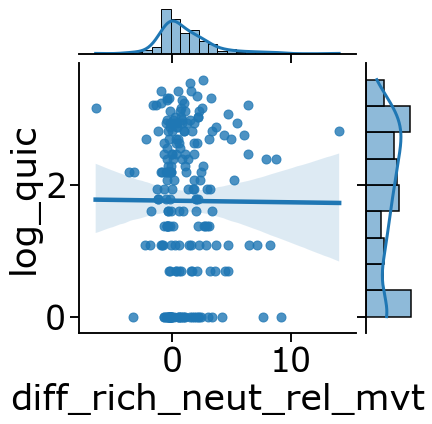

In [ ]:
print(pg.corr(quic_df['diff_rich_neut_rel_mvt'],quic_df['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut_rel_mvt',y='log_quic',kind="reg",data=quic_df)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut_rel_mvt.png")

           n         r          CI95%        r2    adj_r2     p-val     power
spearman  51 -0.085771  [-0.35, 0.19]  0.007357 -0.034003  0.549541  0.091933


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2    adj_r2     p-val     power
spearman  54 -0.130142  [-0.38, 0.14]  0.016937 -0.021615  0.348262  0.155933


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2   adj_r2     p-val     power
spearman  49  0.266587  [-0.02, 0.51]  0.071068  0.03068  0.064084  0.463792


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


           n         r          CI95%        r2    adj_r2     p-val     power
spearman  53 -0.018513  [-0.29, 0.25]  0.000343 -0.039644  0.895321  0.051699


/Library/Frameworks/Python.framework/Versions/3.6/lib/python3.6/site-packages/seaborn/axisgrid.py:1629: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  f.tight_layout()


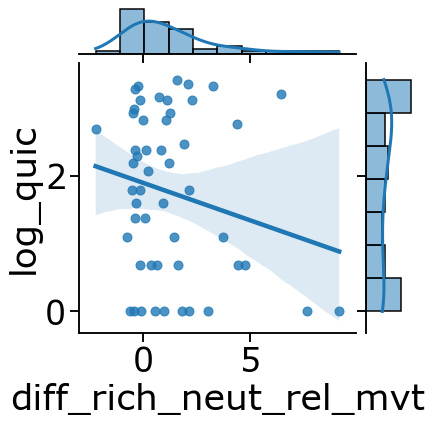

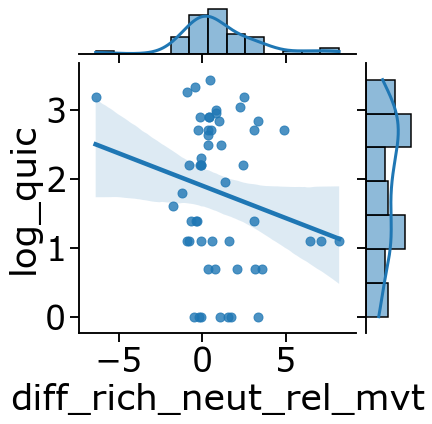

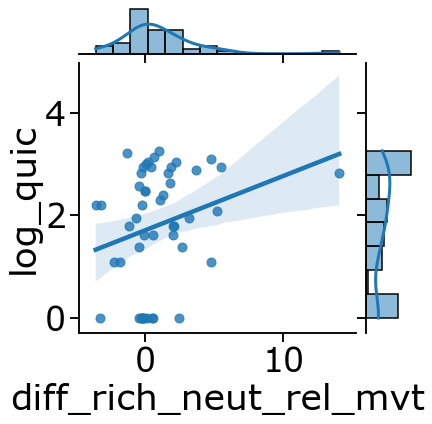

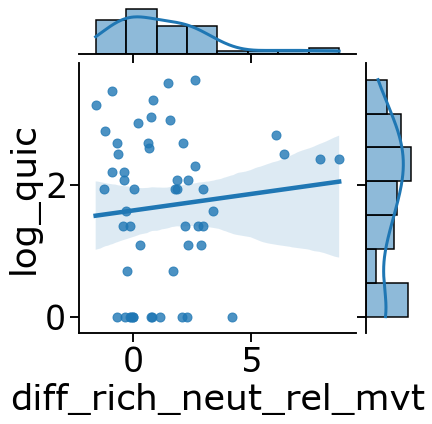

In [ ]:
print(pg.corr(quic_1['diff_rich_neut_rel_mvt'],quic_1['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut_rel_mvt',y='log_quic',kind="reg",data=quic_1)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut_rel_mvt_cond_1.png")

print(pg.corr(quic_2['diff_rich_neut_rel_mvt'],quic_2['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut_rel_mvt',y='log_quic',kind="reg",data=quic_2)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut_rel_mvt_cond_2.png")

print(pg.corr(quic_5['diff_rich_neut_rel_mvt'],quic_5['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut_rel_mvt',y='log_quic',kind="reg",data=quic_5)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut_rel_mvt_cond_5.png")
    
print(pg.corr(quic_6['diff_rich_neut_rel_mvt'],quic_6['log_quic'],method='spearman'))
sns.jointplot(x='diff_rich_neut_rel_mvt',y='log_quic',kind="reg",data=quic_6)
if savefig:
    plt.savefig(round +"/corr_diff_rich_neut_rel_mvt_cond_6.png")

In [ ]:
quic_df["diff_rich_neut_rel_mvt"] = avgd_data.query("galaxy == 1 & prior_galaxy==2").groupby("sub_num").prt_rel_mvt.mean() - avgd_data.query("galaxy == 1 & prior_galaxy==0").groupby("sub_num").prt_rel_mvt.mean()


NameError: name 'avgd_data' is not defined

In [ ]:
high_quic = quic_df.loc[quic_df['quic_score']>13].reset_index(drop=True)
low_quic = quic_df.loc[quic_df['quic_score']<3].reset_index(drop=True)

In [ ]:
high_quic['group'] = 'high_quic'
low_quic['group'] = 'low_quic'
sep_quic = pd.concat([high_quic,low_quic],ignore_index=True)

In [ ]:
all_data.to_csv('all_data_dataset_2022.csv')

In [ ]:
all_data.query("sub_num==1").condition.tolist()[0]

5

In [ ]:
def _sim(cond):
    condition = dc.condition_type(cond)
    exp_struc, rho_0,decay = dc.load_data(condition)
    
    total_treasure = 0
    total_time = 10
    max_block_time = 360

    harvest_time = 2
    travel_time =15.5
    iti = 1.5

    k=[1]
    prts=[]
    planet_vis = []

    for block in range(5):
        t = (5.5 + harvest_time + iti)
        planet = 0
        r = 0
        next_reward = rho_0[block][planet]
        block_prts = []
        block_planet_vis = []
        while t < max_block_time:
            total_treasure += next_reward

            if r > 0:
                k.append(decay[block][planet][r-1])

            v_stay = next_reward*(sum(k)/len(k))
            v_leave = ((total_treasure/total_time)*(harvest_time+iti))

            if v_stay > v_leave:
                choice = 1
            else:
                choice=0


            if choice == 0:
                block_prts.append(r)
                r=0
                block_planet_vis.append(planet)
                planet += 1
                next_reward = rho_0[block][planet]
                t += travel_time
                total_time += travel_time
            else:
                next_reward = next_reward*decay[block][planet][r]
                r+=1
                t += (harvest_time + iti)
                total_time += (harvest_time + iti)
        print('global_rr: ' + str(total_treasure/total_time))
        prts.append(block_prts)
        planet_vis.append(block_planet_vis)
    return total_treasure,prts,planet_vis

global_rr: 8.9541385571695
global_rr: 9.7324106260411
global_rr: 9.802297691870198
global_rr: 10.437378820318687
global_rr: 10.671937962921824
[[1, 1, 1, 1, 1, 1, 7, 9, 8, 1, 1, 1, 1, 1], [7, 9, 5, 9, 1, 1, 1, 1, 1, 2, 2, 2], [2, 2, 2, 2, 1, 1, 1, 1, 7, 7, 5, 7], [7, 15, 10, 5, 11, 1, 1, 1, 1, 1], [2, 2, 2, 2, 9, 10, 6, 8, 7, 1, 1]]


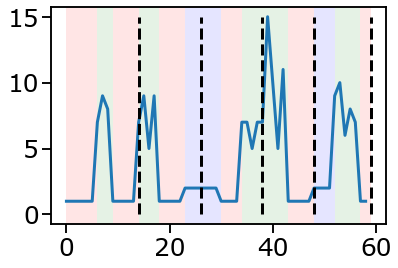

In [ ]:
cond_num = 1
total_treasure,prts,planet_vis=_sim(cond_num )

condition = dc.condition_type(cond_num )

exp_struc, rho_0,decay = dc.load_data(condition)


plt.plot(dc.flatten_list(prts))
plt.plot([len(prts[0]),len(prts[0])],[0,15],'k--')
plt.plot([len(prts[1])+len(prts[0]),len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[2])+len(prts[1])+len(prts[0]),len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')

for block in range(5):
    for planet in range(len(prts[block])):
        planet_num = planet + sum([planet_vis[i][-1] + 1 for i in range(block)])
        galaxy = dc.flatten_list(exp_struc[block])[planet]
        if galaxy == 0:
            plt.axvspan(planet_num, planet_num+1, facecolor='r', alpha=0.1)
        elif galaxy == 1:
            plt.axvspan(planet_num, planet_num+1, facecolor='b', alpha=0.1)
        elif galaxy == 2:
            plt.axvspan(planet_num, planet_num+1, facecolor='g', alpha=0.1)
print(prts)

global_rr: 10.09409566068481
global_rr: 10.284472454679772
global_rr: 10.176058125800438
global_rr: 10.716055356421476
global_rr: 10.894454924663826
[[1, 1, 1, 1, 1, 1, 1, 1, 2, 10, 6, 9, 4], [6, 5, 12, 5, 3, 2, 2, 2, 2, 1, 1, 1], [2, 2, 2, 2, 1, 1, 1, 1, 7, 7, 5, 6], [7, 14, 10, 5, 11, 1, 1, 1, 1, 1], [2, 2, 2, 2, 9, 10, 6, 8, 7, 1, 1]]


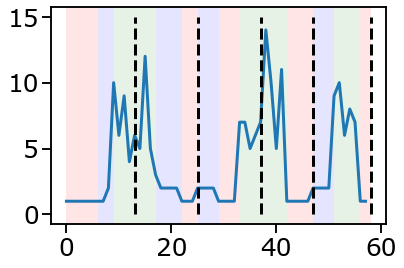

In [ ]:
cond_num = 2
total_treasure,prts,planet_vis=_sim(cond_num )

condition = dc.condition_type(cond_num )

exp_struc, rho_0,decay = dc.load_data(condition)


plt.plot(dc.flatten_list(prts))
plt.plot([len(prts[0]),len(prts[0])],[0,15],'k--')
plt.plot([len(prts[1])+len(prts[0]),len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[2])+len(prts[1])+len(prts[0]),len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')

for block in range(5):
    for planet in range(len(prts[block])):
        planet_num = planet + sum([planet_vis[i][-1] + 1 for i in range(block)])
        galaxy = dc.flatten_list(exp_struc[block])[planet]
        if galaxy == 0:
            plt.axvspan(planet_num, planet_num+1, facecolor='r', alpha=0.1)
        elif galaxy == 1:
            plt.axvspan(planet_num, planet_num+1, facecolor='b', alpha=0.1)
        elif galaxy == 2:
            plt.axvspan(planet_num, planet_num+1, facecolor='g', alpha=0.1)
print(prts)

global_rr: 11.49349488569011
global_rr: 10.790549944879036
global_rr: 10.381836308638503
global_rr: 10.86733437796842
global_rr: 11.014149315331379
[[4, 5, 6, 5, 10, 4, 1, 1, 2, 1, 1, 1], [1, 1, 1, 1, 2, 1, 2, 3, 2, 5, 7, 6, 7], [2, 2, 2, 2, 1, 1, 1, 1, 7, 7, 5, 6, 3], [7, 14, 10, 5, 11, 1, 1, 1, 1, 1], [2, 2, 2, 2, 9, 10, 6, 8, 7, 1, 1]]


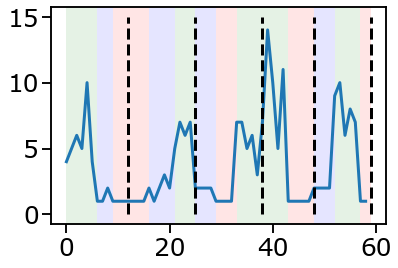

In [ ]:
cond_num = 5
total_treasure,prts,planet_vis=_sim(cond_num )

condition = dc.condition_type(cond_num )

exp_struc, rho_0,decay = dc.load_data(condition)


plt.plot(dc.flatten_list(prts))
plt.plot([len(prts[0]),len(prts[0])],[0,15],'k--')
plt.plot([len(prts[1])+len(prts[0]),len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[2])+len(prts[1])+len(prts[0]),len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')

for block in range(5):
    for planet in range(len(prts[block])):
        planet_num = planet + sum([planet_vis[i][-1] + 1 for i in range(block)])
        galaxy = dc.flatten_list(exp_struc[block])[planet]
        if galaxy == 0:
            plt.axvspan(planet_num, planet_num+1, facecolor='r', alpha=0.1)
        elif galaxy == 1:
            plt.axvspan(planet_num, planet_num+1, facecolor='b', alpha=0.1)
        elif galaxy == 2:
            plt.axvspan(planet_num, planet_num+1, facecolor='g', alpha=0.1)
print(prts)

global_rr: 12.723927804992604
global_rr: 11.73231708533215
global_rr: 11.005206818909883
global_rr: 11.33484348292873
global_rr: 11.385564853483903
[[4, 8, 2, 3, 7, 5, 1, 1, 1, 9], [1, 1, 1, 1, 6, 6, 5, 7, 9, 2, 2, 2], [2, 2, 2, 2, 1, 1, 1, 1, 7, 7, 5, 6, 3], [7, 14, 10, 4, 11, 1, 1, 1, 1, 1], [2, 2, 2, 2, 9, 10, 6, 7, 7, 1, 1]]


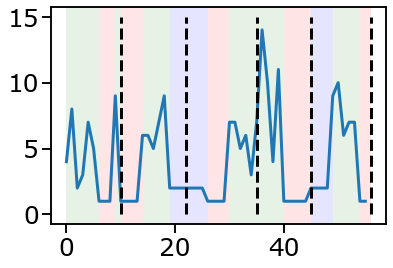

In [ ]:
cond_num = 6
total_treasure,prts,planet_vis=_sim(cond_num )

condition = dc.condition_type(cond_num )

exp_struc, rho_0,decay = dc.load_data(condition)


plt.plot(dc.flatten_list(prts))
plt.plot([len(prts[0]),len(prts[0])],[0,15],'k--')
plt.plot([len(prts[1])+len(prts[0]),len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[2])+len(prts[1])+len(prts[0]),len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')
plt.plot([len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0]),len(prts[4])+len(prts[3])+len(prts[2])+len(prts[1])+len(prts[0])],[0,15],'k--')

for block in range(5):
    for planet in range(len(prts[block])):
        planet_num = planet + sum([planet_vis[i][-1] + 1 for i in range(block)])
        galaxy = dc.flatten_list(exp_struc[block])[planet]
        if galaxy == 0:
            plt.axvspan(planet_num, planet_num+1, facecolor='r', alpha=0.1)
        elif galaxy == 1:
            plt.axvspan(planet_num, planet_num+1, facecolor='b', alpha=0.1)
        elif galaxy == 2:
            plt.axvspan(planet_num, planet_num+1, facecolor='g', alpha=0.1)
print(prts)

# bayesian

In [ ]:
import pymc3 as pm
group1 = avgd_data_post.query("condition==5").prt_rel_mvt.tolist()
group2 = avgd_data_post.query("condition==6").prt_rel_mvt.tolist()
pooled = np.concatenate((group1,group2))


In [ ]:
μ_m = pooled.mean()
μ_s = pooled.std() * 2

with pm.Model() as model:
    group1_mean = pm.Normal('group1_mean', mu=μ_m, sd=μ_s)
    group2_mean = pm.Normal('group2_mean', mu=μ_m, sd=μ_s)

σ_low = pooled.std()/1000
σ_high = pooled.std()*1000

with model:
    group1_std = pm.Uniform('group1_std', lower=σ_low, upper=σ_high)
    group2_std = pm.Uniform('group2_std', lower=σ_low, upper=σ_high)
    

with model:
    ν = pm.Exponential('ν_minus_one', 1/ 1/29.) + 1
    
with model:
    λ1 = group1_std**-2
    λ2 = group2_std**-2

    group1 = pm.StudentT('drug', nu=ν, mu=group1_mean, lam=λ1, observed=group1)
    group2 = pm.StudentT('placebo', nu=ν, mu=group2_mean, lam=λ2, observed=group2)

In [ ]:
with model:
    diff_of_means = pm.Deterministic('difference of means', group1_mean - group2_mean)
    diff_of_stds = pm.Deterministic('difference of stds', group1_std - group2_std)
    effect_size = pm.Deterministic('effect size',
                                   diff_of_means / np.sqrt((group1_std**2 + group2_std**2) / 2))
    trace = pm.sample(2000)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [ν_minus_one, group2_std, group1_std, group2_mean, group1_mean]
Sampling 2 chains: 100%|██████████| 5000/5000 [00:15<00:00, 330.38draws/s]


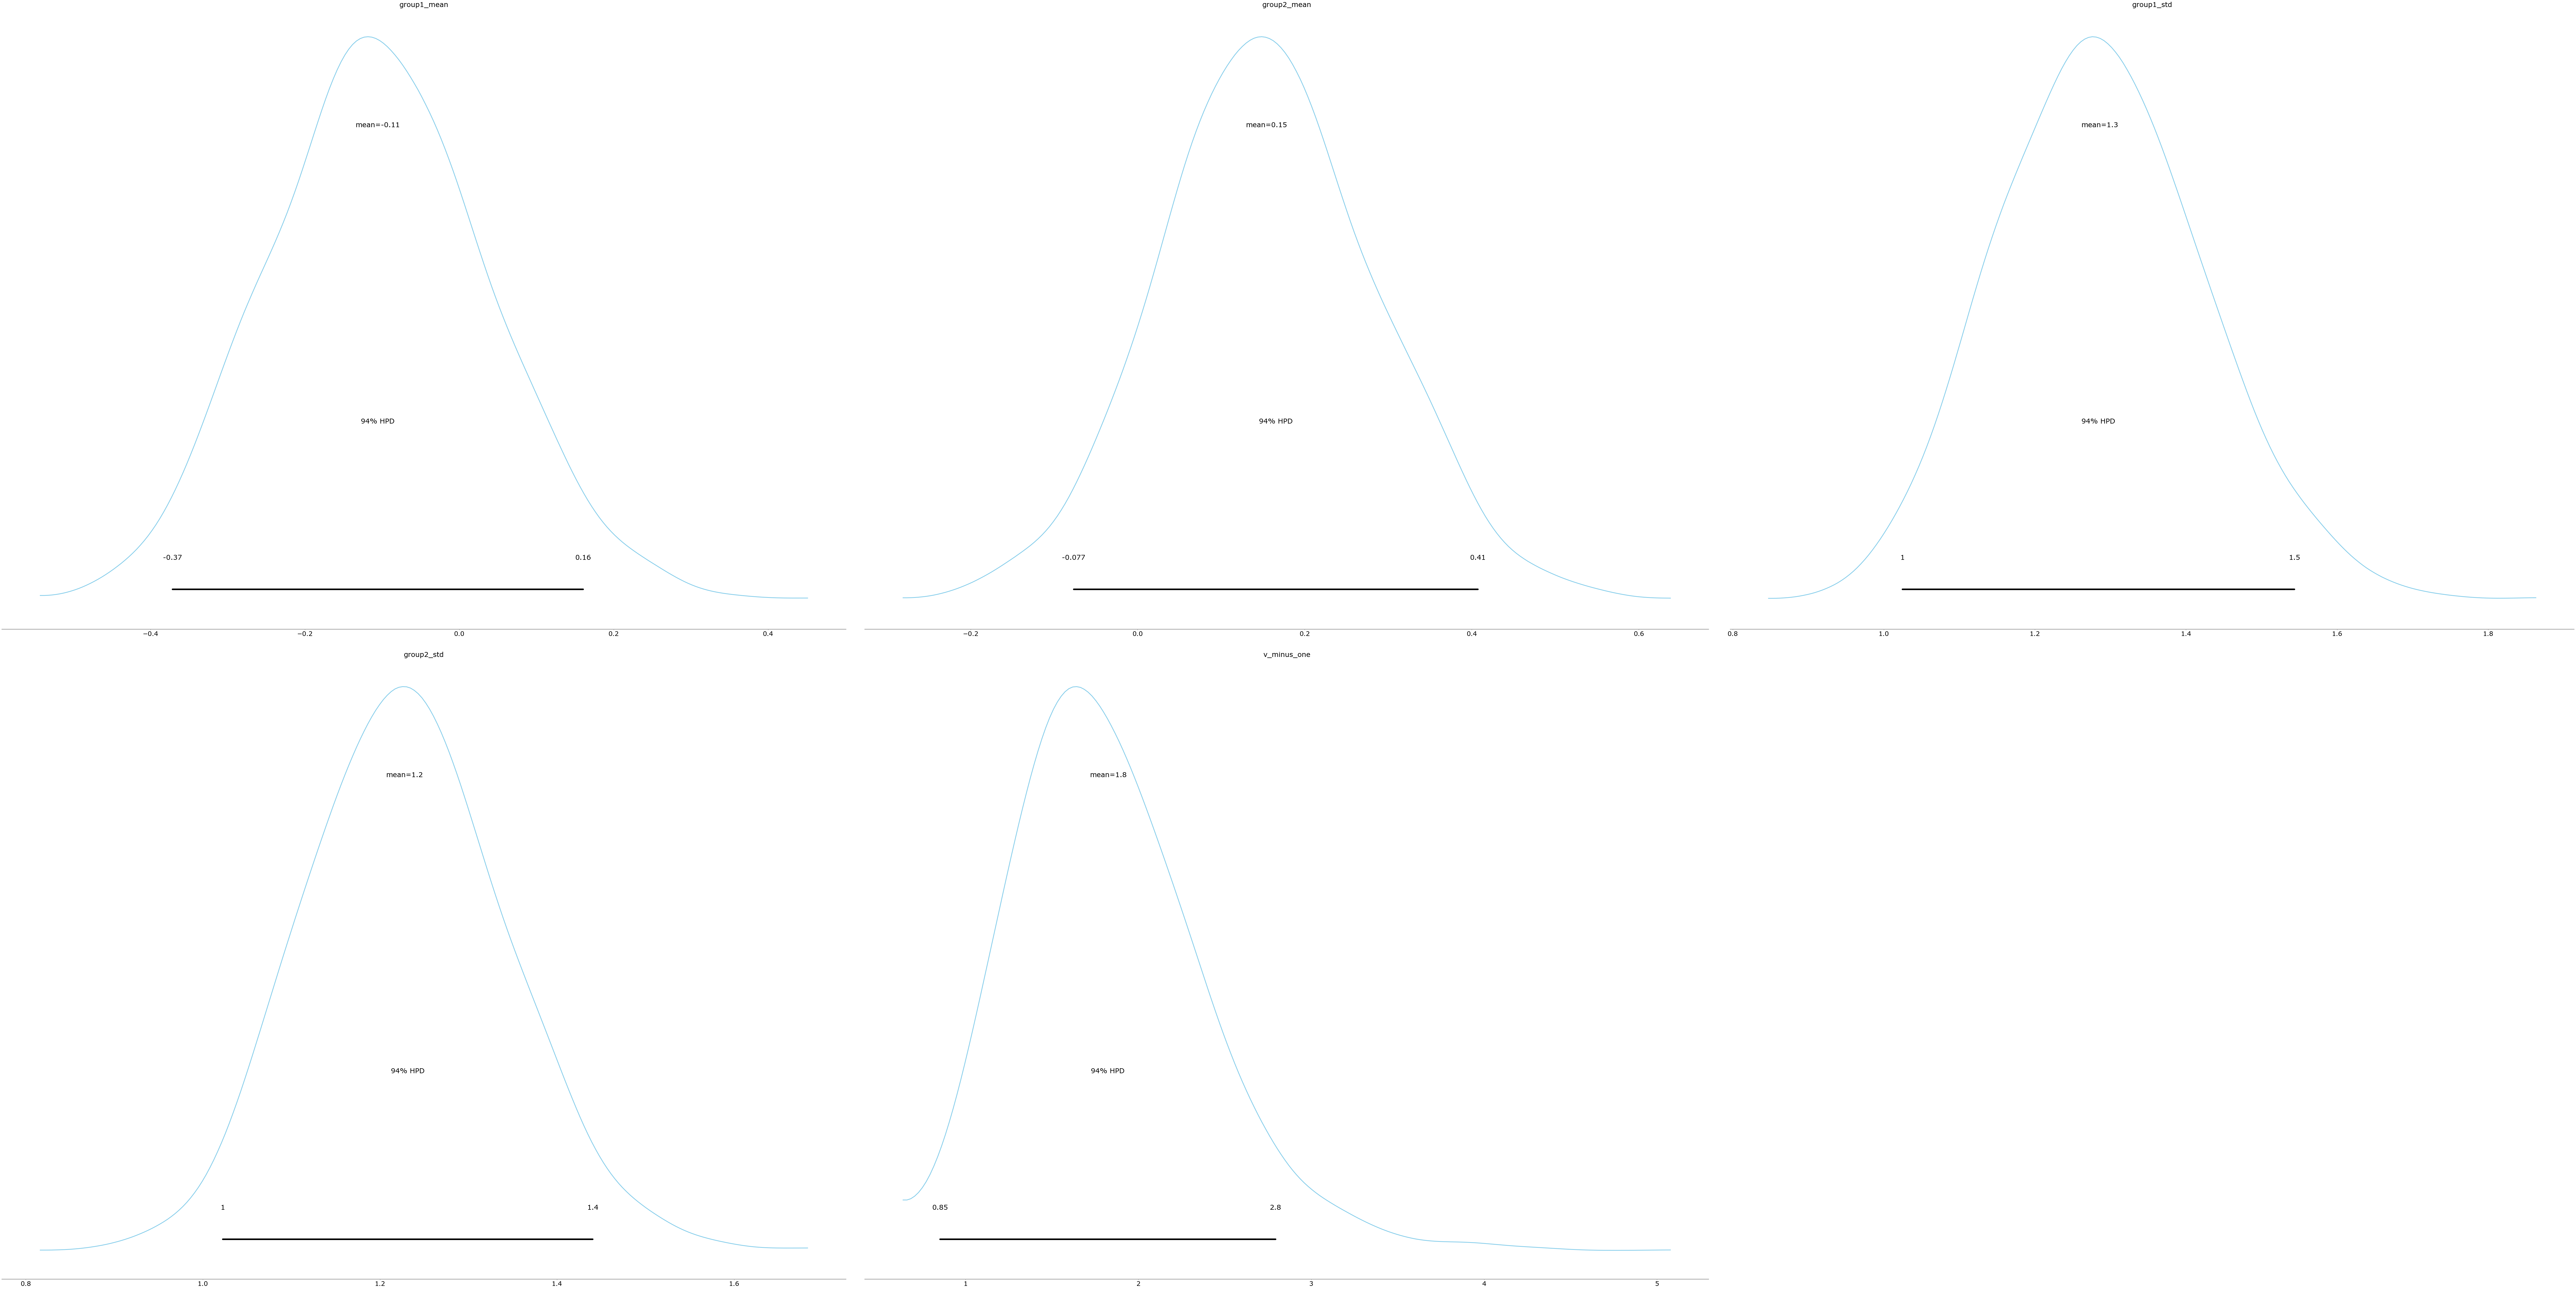

In [ ]:

pm.plot_posterior(trace, var_names=['group1_mean','group2_mean', 'group1_std', 'group2_std', 'ν_minus_one'],
                  color='#87ceeb');

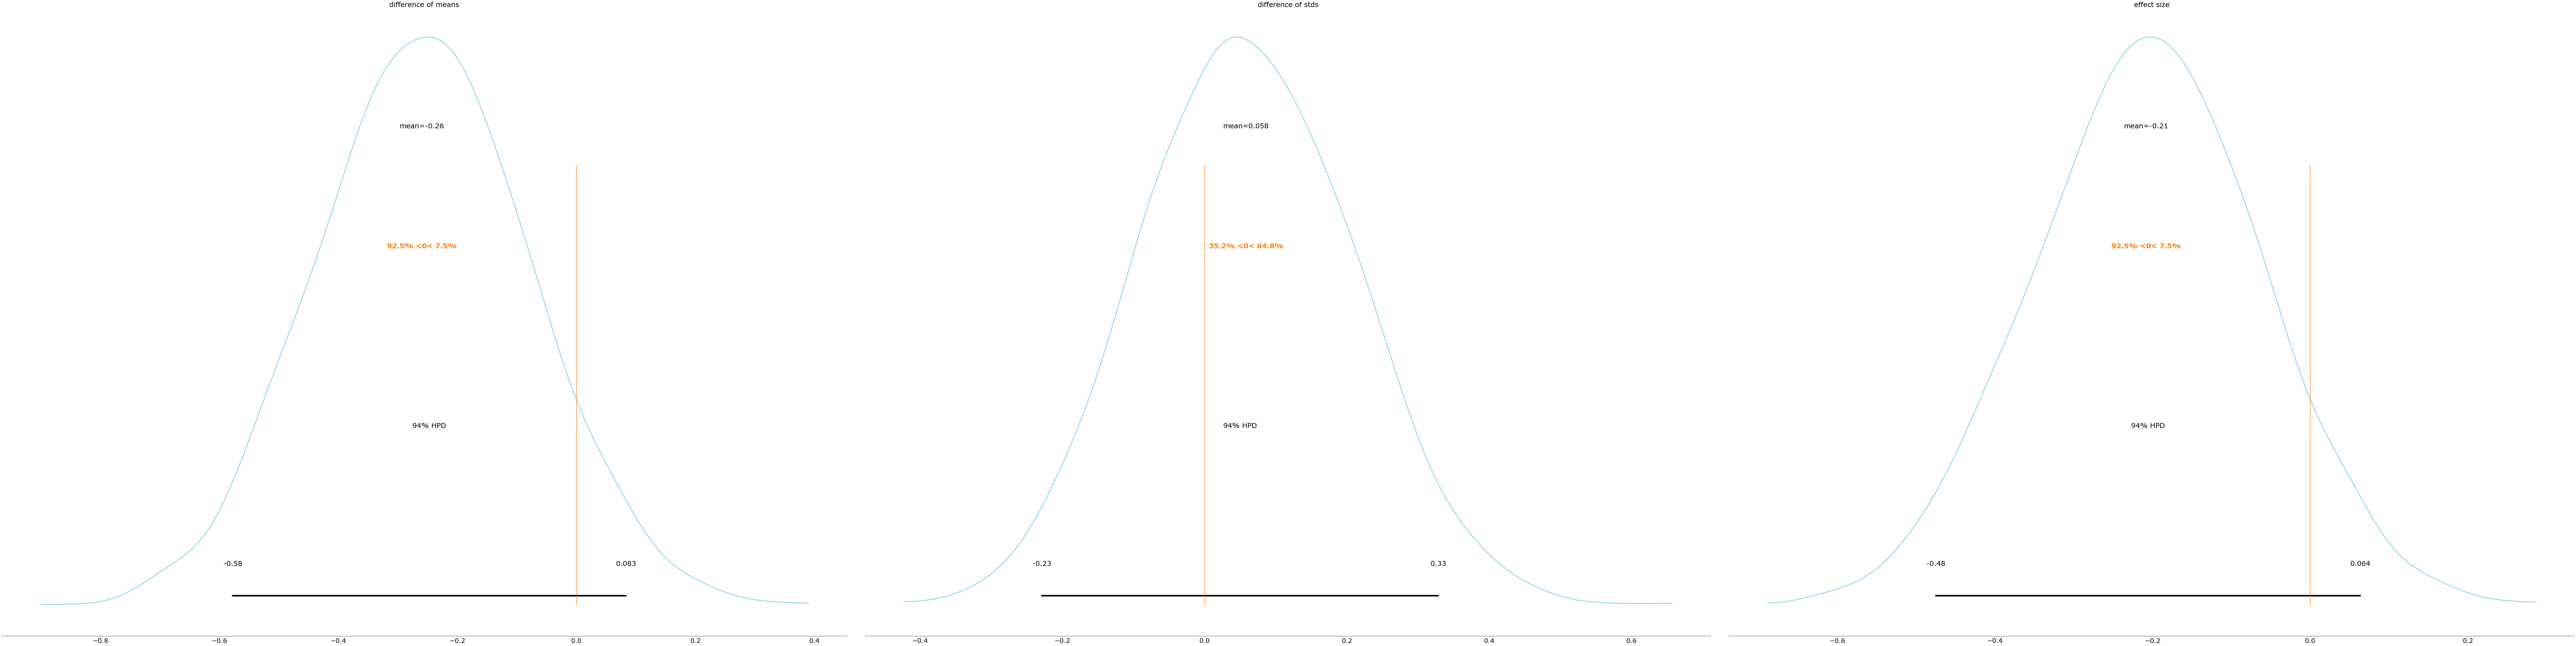

In [ ]:

pm.plot_posterior(trace, var_names=['difference of means','difference of stds', 'effect size'],
                  ref_val=0,
                  color='#87ceeb');

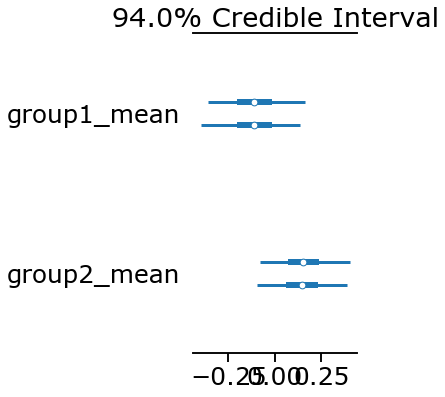

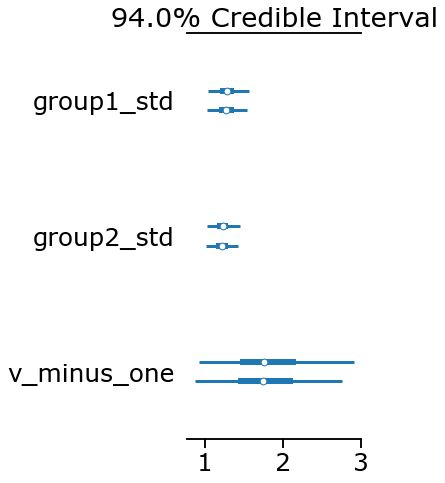

In [ ]:

pm.forestplot(trace, var_names=['group1_mean',
                                'group2_mean']);
pm.forestplot(trace, var_names=['group1_std',
                               'group2_std',
                               'ν_minus_one']);

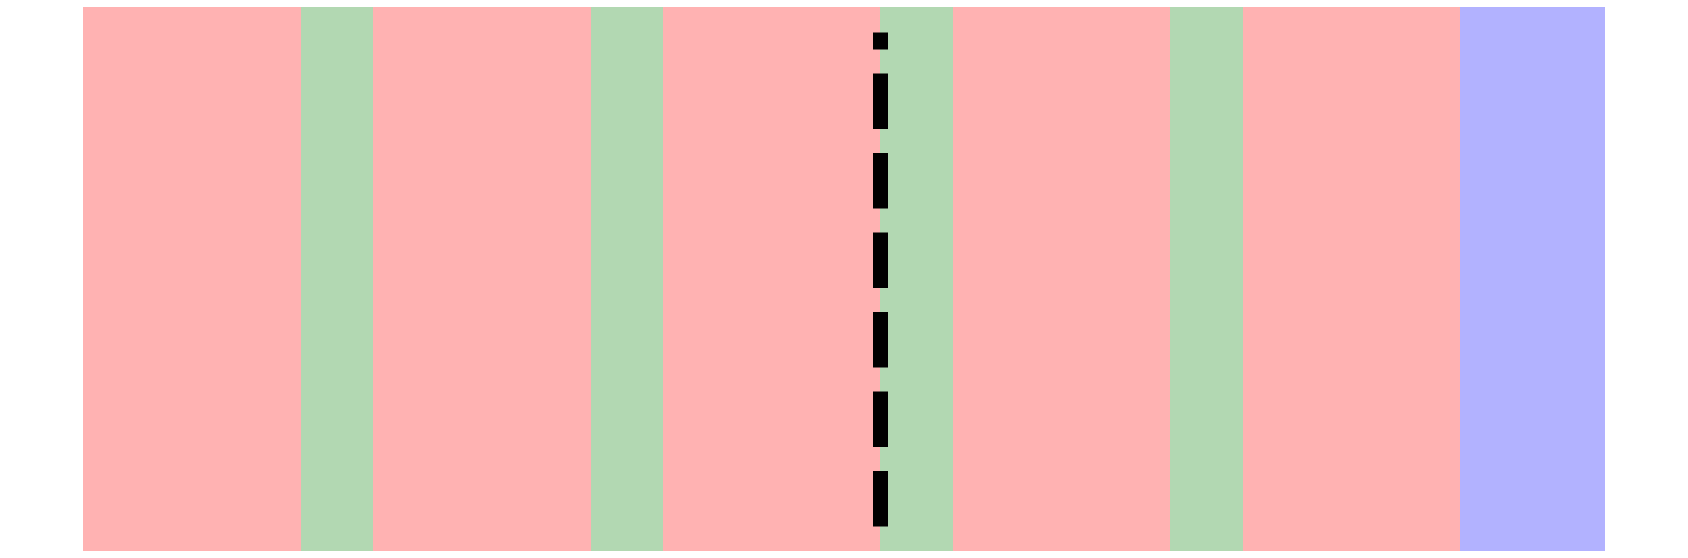

In [ ]:
plt.rcParams["figure.figsize"] = (30,10)


plt.axvspan(0,3,facecolor='r', alpha=0.3)
plt.axvspan(3,4,facecolor='g', alpha=0.3)
plt.axvspan(4,7,facecolor='r', alpha=0.3)
plt.axvspan(7,8,facecolor='g', alpha=0.3)
plt.axvspan(8,11,facecolor='r', alpha=0.3)

plt.axvspan(11,12,facecolor='g', alpha=0.3)
plt.axvspan(12,15,facecolor='r', alpha=0.3)
plt.axvspan(15,16,facecolor='g', alpha=0.3)
plt.axvspan(16,19,facecolor='r', alpha=0.3)
plt.axvspan(19,21,facecolor='b', alpha=0.3)

plt.plot([11,11],[0,1],'k--',linewidth=15)
sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])

plt.savefig("plots/exp_struc_poor_extreme_ex.png")

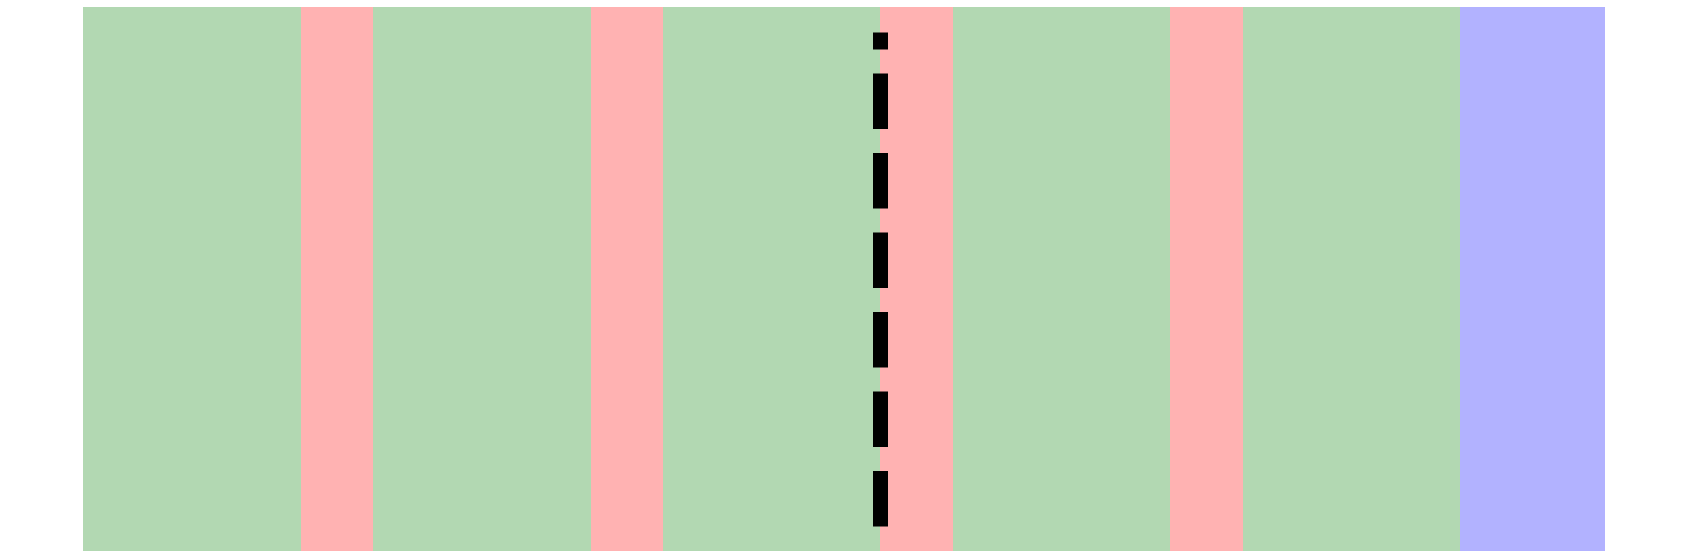

In [ ]:
plt.rcParams["figure.figsize"] = (30,10)


plt.axvspan(0,3,facecolor='g', alpha=0.3)
plt.axvspan(3,4,facecolor='r', alpha=0.3)
plt.axvspan(4,7,facecolor='g', alpha=0.3)
plt.axvspan(7,8,facecolor='r', alpha=0.3)
plt.axvspan(8,11,facecolor='g', alpha=0.3)

plt.axvspan(11,12,facecolor='r', alpha=0.3)
plt.axvspan(12,15,facecolor='g', alpha=0.3)
plt.axvspan(15,16,facecolor='r', alpha=0.3)
plt.axvspan(16,19,facecolor='g', alpha=0.3)
plt.axvspan(19,21,facecolor='b', alpha=0.3)

plt.plot([11,11],[0,1],'k--',linewidth=15)
sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])


plt.savefig("plots/exp_struc_rich_extreme_ex.png")

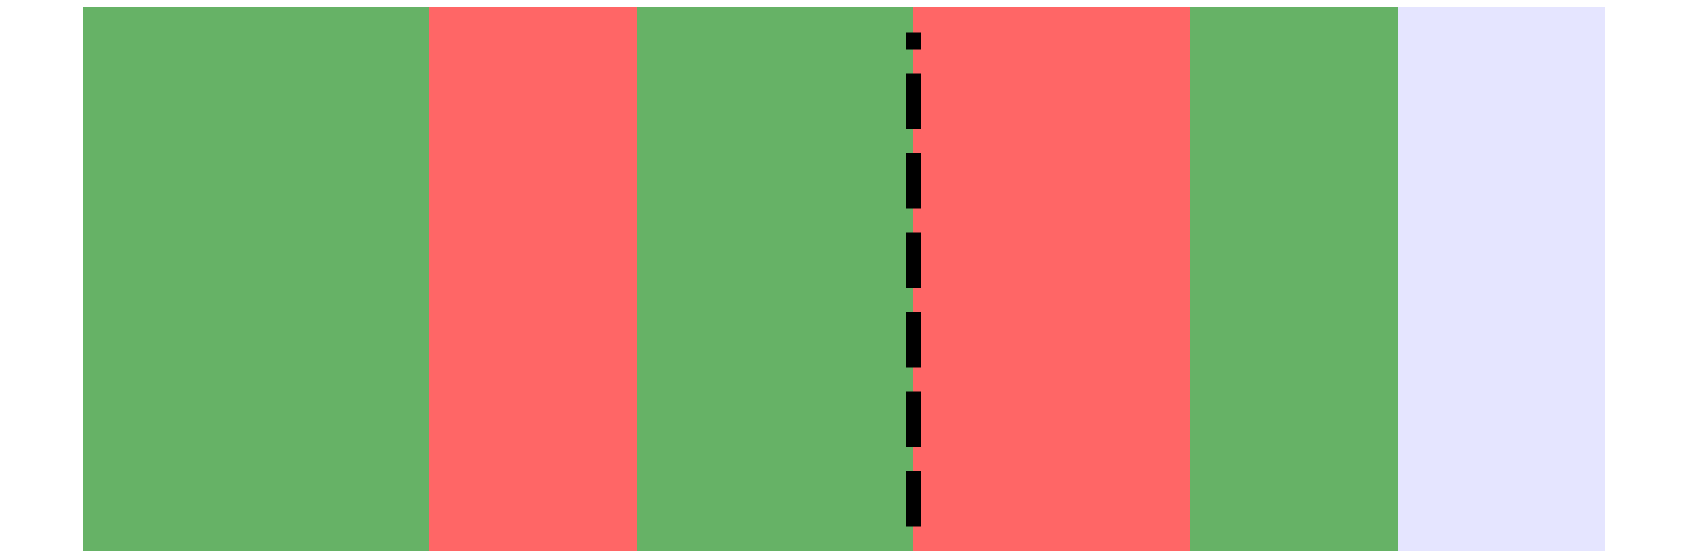

In [ ]:
plt.rcParams["figure.figsize"] = (30,10)


plt.axvspan(0,5,facecolor='g', alpha=0.6)
plt.axvspan(5,8,facecolor='r', alpha=0.6)
plt.axvspan(8,12,facecolor='g', alpha=0.6)
plt.axvspan(12,16,facecolor='r', alpha=0.6)
plt.axvspan(16,19,facecolor='g', alpha=0.6)
plt.axvspan(19,22,facecolor='b', alpha=0.1)

plt.plot([12,12],[0,1],'k--',linewidth=15)
sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])

plt.savefig("plots/exp_struc_rich_extreme_ex.png")

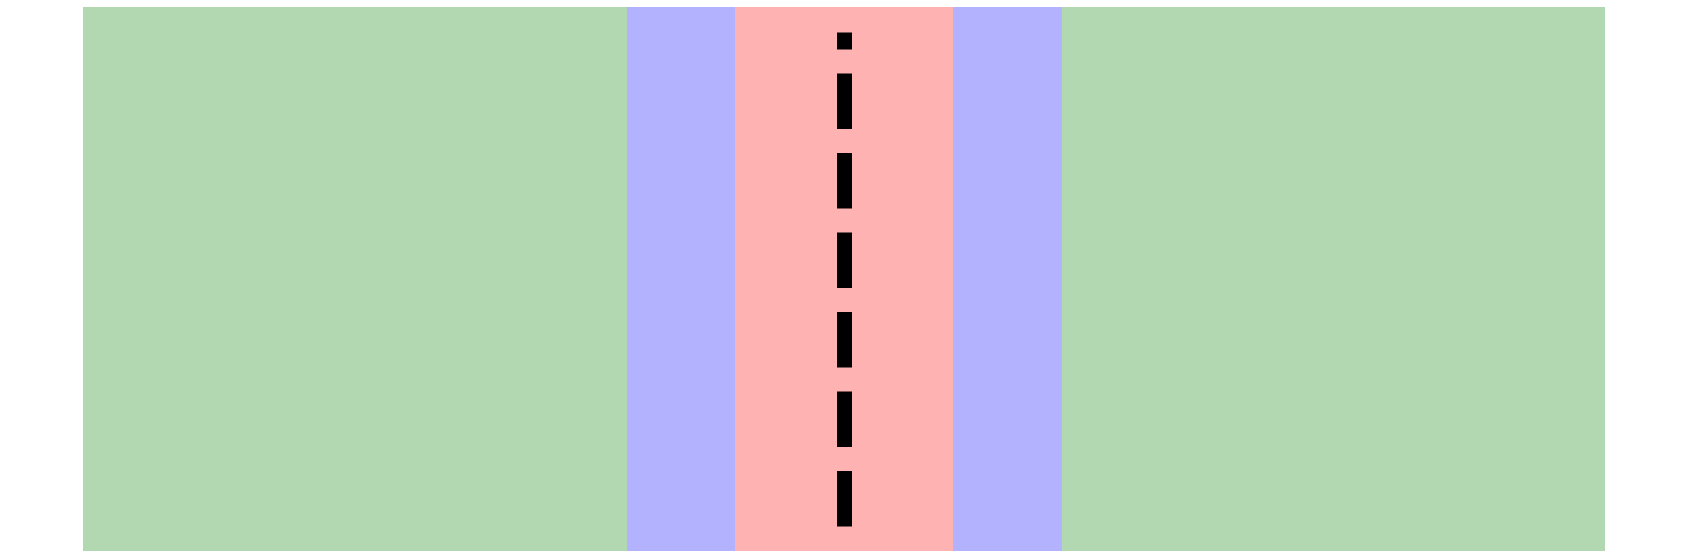

In [ ]:
plt.rcParams["figure.figsize"] = (30,10)


plt.axvspan(0,5,facecolor='g', alpha=0.3)
plt.axvspan(5,6,facecolor='b', alpha=0.3)
plt.axvspan(6,7,facecolor='r', alpha=0.3)
plt.axvspan(7,8,facecolor='r', alpha=0.3)
plt.axvspan(8,9,facecolor='b', alpha=0.3)
plt.axvspan(9,14,facecolor='g', alpha=0.3)

plt.plot([7,7],[0,1],'k--',linewidth=15)
sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])

plt.savefig("plots/exp_struc_rich_graded_ex.png")

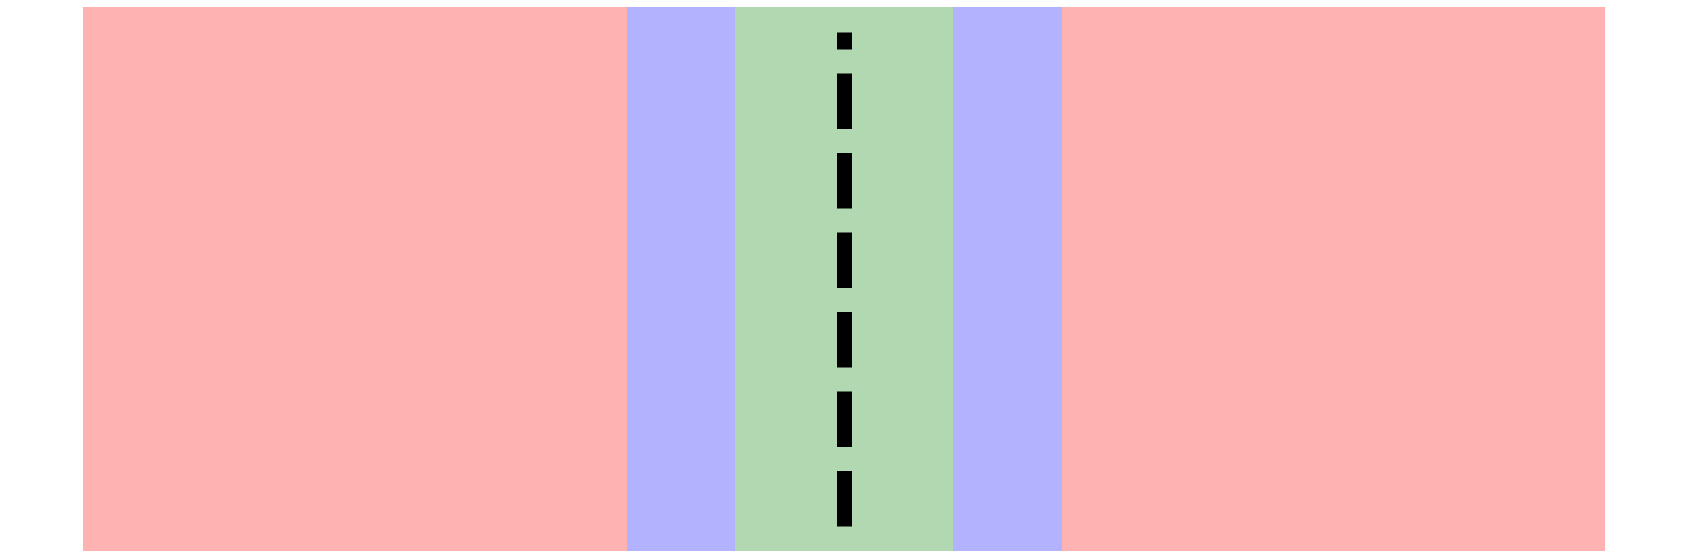

In [ ]:
plt.axvspan(0,5,facecolor='r', alpha=0.3)
plt.axvspan(5,6,facecolor='b', alpha=0.3)
plt.axvspan(6,7,facecolor='g', alpha=0.3)
plt.axvspan(7,8,facecolor='g', alpha=0.3)
plt.axvspan(8,9,facecolor='b', alpha=0.3)
plt.axvspan(9,14,facecolor='r', alpha=0.3)

plt.plot([7,7],[0,1],'k--',linewidth=15)
sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])

plt.savefig("plots/exp_struc_poor_graded_ex.png")

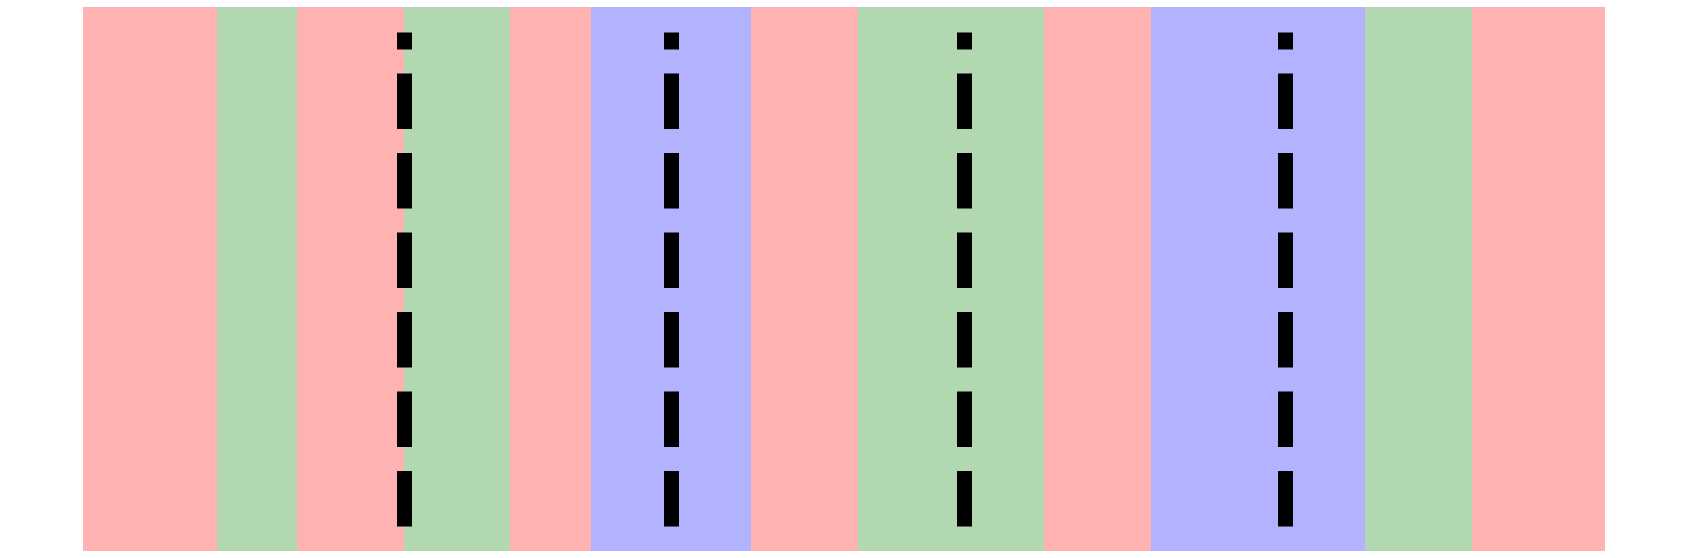

In [ ]:
plt.rcParams["figure.figsize"] = (30,10)


plt.axvspan(0,5,facecolor='r', alpha=0.3)
plt.axvspan(5,8,facecolor='g', alpha=0.3)
plt.axvspan(8,12,facecolor='r', alpha=0.3)

plt.axvspan(12,16,facecolor='g', alpha=0.3)
plt.axvspan(16,19,facecolor='r', alpha=0.3)
plt.axvspan(19,22,facecolor='b', alpha=0.3)

plt.axvspan(22,25,facecolor='b', alpha=0.3)
plt.axvspan(25,29,facecolor='r', alpha=0.3)
plt.axvspan(29,33,facecolor='g', alpha=0.3)

plt.axvspan(33,36,facecolor='g', alpha=0.3)
plt.axvspan(36,40,facecolor='r', alpha=0.3)
plt.axvspan(40,45,facecolor='b', alpha=0.3)

plt.axvspan(45,48,facecolor='b', alpha=0.3)
plt.axvspan(48,52,facecolor='g', alpha=0.3)
plt.axvspan(52,57,facecolor='r', alpha=0.3)

plt.plot([12,12],[0,1],'k--',linewidth=15)
plt.plot([22,22],[0,1],'k--',linewidth=15)
plt.plot([33,33],[0,1],'k--',linewidth=15)
plt.plot([45,45],[0,1],'k--',linewidth=15)



sns.despine(top=True,right=True,bottom=True,left=True)
plt.xticks([])
plt.yticks([])

plt.savefig("plots/whole.png")

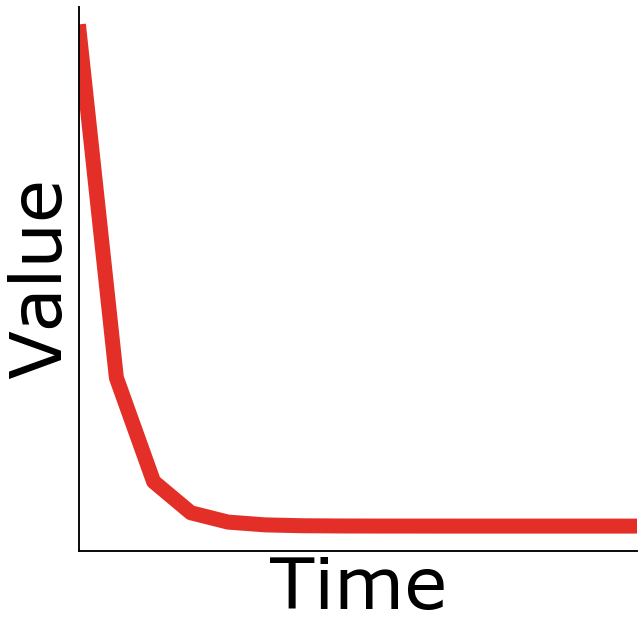

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)
sns.set_context('talk',font_scale=4)

x = range(100)
y = [1*((0.3)**(i)) for i in x]

plt.plot(x,y,linewidth=15,color=pal[0])
plt.xlim([0,15])
sns.despine(right=True,top=True)
plt.ylabel('Value')
plt.yticks([])
plt.xlabel('Time')
plt.xticks([])

plt.savefig("plots/poor.png")

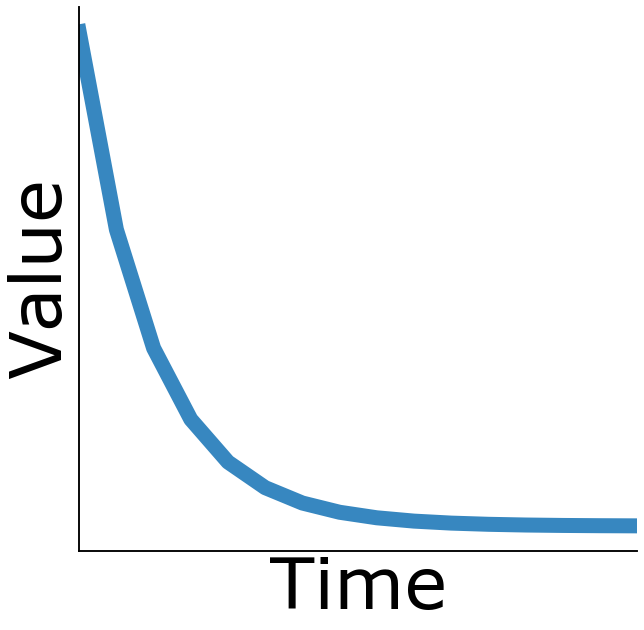

In [ ]:

x = range(100)
y = [1*((0.6)**(i)) for i in x]

plt.plot(x,y,linewidth=15,color= sns.color_palette("Blues_r", 2)[0])
plt.xlim([0,15])
sns.despine(right=True,top=True)
plt.ylabel('Value')
plt.yticks([])
plt.xlabel('Time')
plt.xticks([])

plt.savefig("plots/neutral.png")

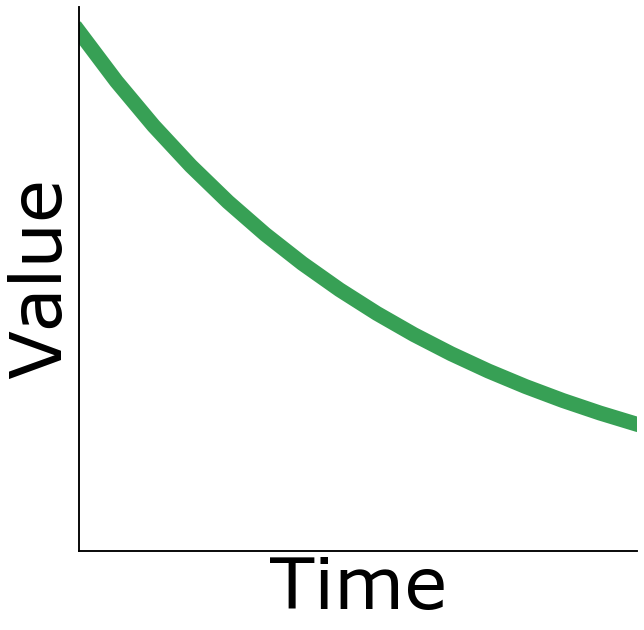

In [ ]:

x = range(100)
y = [1*((0.9)**(i)) for i in x]

plt.plot(x,y,linewidth=15,color= pal[2])
plt.xlim([0,15])
sns.despine(right=True,top=True)
plt.ylabel('Value')
plt.yticks([])
plt.xlabel('Time')
plt.xticks([])

plt.savefig("plots/rich.png")

In [ ]:
avgd_data_post.groupby("condition").prt_rel_mvt.mean().reset_index(drop=False).to_csv("fit_plot_condition_average.csv")

# sim for determining travel time

In [ ]:
import sim 
import pandas as pd
import seaborn as sns

def run_sim(cond_num):
    total_treasure,prts = sim.sim(cond_num)

    block_n_planets = [len(x) for x in prts] 
    exp_struc, rho_0, all_decay = sim.load_data(sim.condition_type(cond_num))
    exp_struc = [sim.flatten_list(x) for x in exp_struc]
    exp_planets = [exp_struc[i][:block_n_planets[i]] for i in range(5)]
    
    post_prts = prts[2:]
    exp_planets = exp_planets[2:]

    exp_planets = sim.flatten_list(exp_planets)
    exp_struc = sim.flatten_list(exp_struc)

    df = pd.DataFrame({'condition':[cond_num]*len(exp_planets),'galaxy':exp_planets,'prt':sim.flatten_list(post_prts)})

    return df

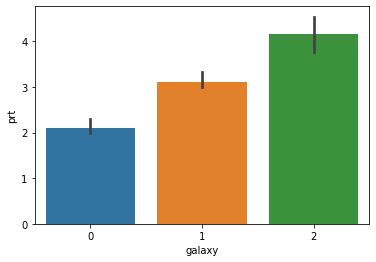

In [ ]:
df_1 = run_sim(1)
sns.barplot(x='galaxy',y='prt',data=df_1)

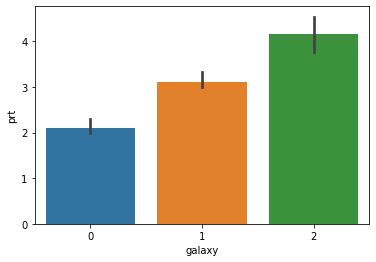

In [ ]:
df_2 = run_sim(2)
sns.barplot(x='galaxy',y='prt',data=df_2)

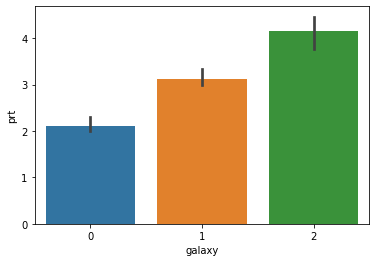

In [ ]:
df_5 = run_sim(5)
sns.barplot(x='galaxy',y='prt',data=df_5)

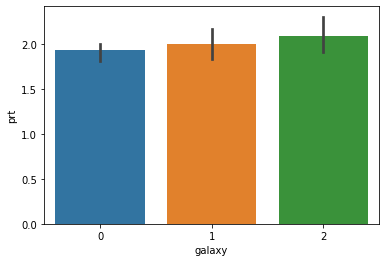

In [ ]:
df_6 = run_sim(6)
sns.barplot(x='galaxy',y='prt',data=df_6)